# Minería de Datos – Práctica 3.4 Clasificación
## Equipo 7
**Integrantes:** Flores García Claudio, Juarez Valdivia Barvara Caridad, Ortega de la Paz Rafael

**Datos:** *Diabetes demo* (829 registros de personas con 11 mediciones clínicas y su diagnóstico de diabetes).

**Algoritmos de clasificación (Python):** Regresión Logística, Árbol de Decisión y Random Forest; además, K Vecinos Más Cercanos (KNN) como cuarto modelo de comparación.

**Cómo se responde cada requerimiento de la práctica:**

| Requerimiento | Sección |
|---|---|
| Definir la variable objetivo categórica binaria asociada al caso de negocio | 1 y 2 |
| Crear diagramas EDA para analizar las variables independientes y decidir cuáles utilizar | 4 |
| Realizar un split de los datos (70% entrenamiento, 30% prueba) de forma aleatoria | 6 |
| Aplicar los algoritmos de clasificación (mínimo 3) | 8 |
| Identificar las variables independientes que más inciden en la variable objetivo | 12 |
| Métricas correspondientes a cada variable significativa | 12 y 13 |
| Obtener la matriz de confusión y explicar los falsos positivos y falsos negativos | 10 |
| Identificar a las personas que se encuentran en los falsos positivos y negativos | 14 |
| Aplicar las métricas de evaluación del algoritmo | 9 y 11 |
| Conclusión de los resultados desde el punto de vista de negocio | 15 |

## 1. Caso de negocio
Una institución de salud quiere **identificar las características principales que determinan que una persona pueda tener diabetes**. Con un modelo de clasificación confiable se puede:
- **Detectar de forma temprana** a las personas con mayor probabilidad de tener diabetes y enviarlas a estudios de confirmación.
- Saber **qué variables clínicas inciden más** en el diagnóstico y **a partir de qué valores** se vuelven críticas, para orientar campañas de prevención.
- Conocer **qué tan confiable es el modelo** y qué consecuencias tiene cada tipo de error.

En un problema de salud los errores no pesan lo mismo. Un **falso negativo** (decirle a una persona que no tiene diabetes cuando sí la tiene) es el error más grave: la persona se va sin tratamiento y la enfermedad avanza. Un **falso positivo** (decirle que sí tiene cuando no) genera preocupación y el costo de un estudio adicional, pero no pone en riesgo su salud. Por eso, además de la exactitud global, en esta práctica se vigila especialmente el **Recall** (la proporción de personas con diabetes que el modelo logra detectar).

## 2. Variable objetivo
**Tiene Diabetes** es una **variable categórica binaria**: **1 = la persona tiene diabetes** y **0 = no tiene diabetes**. Es la variable dependiente (Y) que se busca predecir, por lo que se trata de un problema de **clasificación supervisada**: el modelo aprende de personas cuyo diagnóstico ya se conoce para clasificar a personas nuevas.

Las demás mediciones clínicas son las variables independientes (X) candidatas. `Persona` es un número de identificación, no una característica clínica, por lo que **no se usa para entrenar**; se conserva aparte para poder identificar a las personas en los errores del modelo.

**Descripción de las variables independientes candidatas:**

| Variable | Qué mide |
|---|---|
| Num Embarazos | Número de embarazos de la persona |
| N Glucosa | Nivel de glucosa en sangre |
| Presion Arterial | Presión arterial |
| Grosor de la Piel | Grosor del pliegue de la piel, indicador de grasa corporal |
| Urea | Nivel de urea en sangre, relacionado con la función renal |
| Trigliceridos | Nivel de triglicéridos (grasas) en sangre |
| Lipoproteina BD | Lipoproteína de baja densidad (colesterol "malo") |
| N. Insulina | Nivel de insulina en sangre |
| Masa Corporal | Índice de masa corporal (IMC) |
| Prediccion Diabetes | Índice de predisposición a la diabetes relacionado con antecedentes familiares; es un dato de entrada, **no** una predicción de nuestro modelo |
| Edad | Edad en años |

## 3. Librerías y carga de datos
Se importan las librerías del análisis:
- **pandas** y **numpy** para manejar la tabla de datos y hacer cálculos.
- **matplotlib** y **seaborn** para las gráficas.
- **scikit-learn** para dividir los datos, preparar las variables (imputación y estandarización), entrenar los modelos de clasificación, validarlos y calcular sus métricas.
- **statsmodels** para obtener la significancia estadística (valor p) de cada variable en la regresión logística.

Se fija una semilla (`SEMILLA = 42`) para que el split y los modelos que usan azar den **siempre los mismos resultados** cada vez que se ejecute el notebook.

In [1]:
import io, warnings, datetime
warnings.filterwarnings('ignore')
# Ocultar el aviso interno de Colab
try:
    import jupyter_client.session as _jcs
    _jcs.utcnow = lambda _dt=datetime: _dt.datetime.now(_dt.timezone.utc)
except Exception:
    pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_val_score, cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')
AZUL, DORADO, GRIS = '#1F3A68', '#C9A227', '#9DB0CC'
COLORES_CLASE = {0: '#4F6D9A', 1: '#C0392B'}
SEMILLA = 42

Los datos originales de *diabetes demo.csv* vienen **copiados dentro de la siguiente celda**, así que **no es necesario subir ningún archivo**: el notebook funciona en Google Colab con solo abrirlo (Entorno de ejecución → Ejecutar todas).

Además se agrega la columna **Registro**, que es el número de fila de cada persona en el archivo original (1 a 829). Como se verá en el EDA, el número de `Persona` se repite en algunos registros, así que para identificar sin ambigüedad a cada persona se usan **Registro y Persona juntos**.

In [2]:
# Datos originales de "diabetes demo.csv" (829 registros), copiados tal cual
DATOS_CSV = """Persona,Num Embarazos,N Glucosa,Presion Arterial,Grosor de la Piel,Urea,Trigliceridos,Lipoproteina BD,N. Insulina,Masa Corporal,Prediccion Diabetes,Edad,Tiene Diabetes
6710,1,199,76,43,6,3,0.8,0,42.9,1.394,22,1
5710,0,198,66,32,2,3,0.6,274,41.3,0.502,28,1
180,2,197,70,45,4.4,3,0.3,543,30.5,0.158,53,1
2380,4,197,70,39,8.5,5,0.7,744,36.7,2.329,31,0
4180,8,197,74,0,1.9,2,1.2,0,25.9,1.191,39,1
5890,2,197,70,99,4.5,3,0.3,0,34.7,0.575,62,1
320,7,196,90,0,3,2,0.5,0,39.8,0.451,41,1
2160,8,196,76,29,4.5,5.5,0.7,280,37.5,0.605,57,1
3690,1,196,76,36,6.1,7,0.8,249,36.5,0.875,29,1
3700,8,196,76,29,5,5,0.4,57,46.3,1.096,32,0
5080,7,195,70,33,6.66,3.2,22.2,145,25.1,0.163,55,1
6850,6,195,70,0,2.7,6.1,0.9,0,30.9,0.328,31,1
1950,7,194,68,28,5.2,6,0.9,0,35.9,0.745,41,1
3290,6,194,78,0,4,6.3,1,0,23.5,0.129,59,1
4990,8,194,80,0,5.7,2,1.2,0,26.1,0.551,67,0
5000,7,194,68,28,24,5,1.3,180,36.1,0.496,25,0
2680,1,193,50,16,24,5,1.3,375,25.9,0.655,24,0
4090,3,193,70,31,5.6,5.2,1.4,0,34.9,0.241,25,1
2700,3,191,68,15,24,4.8,1.3,130,30.9,0.299,34,0
7690,6,190,92,0,4.3,5.5,2,0,35.5,0.278,66,1
230,1,189,60,23,5.5,6,0.5,846,30.1,0.398,59,1
3700,5,189,64,33,3.9,6.1,1.8,325,31.2,0.583,29,1
4500,0,189,104,25,3.2,2.1,1.7,0,34.3,0.435,41,1
5590,4,189,110,31,3.2,2,0.6,0,28.5,0.68,37,0
1640,8,188,78,0,4,3,1,0,47.9,0.137,43,1
6050,0,188,82,14,4,3,1.3,185,32,0.682,22,1
660,7,187,68,39,7.6,3,1,304,37.7,0.254,41,1
5560,5,187,76,27,5,2,0.4,207,43.6,1.034,53,1
7250,7,187,50,33,4.4,2,1.6,392,33.9,0.826,34,1
7580,3,187,70,22,5,5.5,0.7,200,36.4,0.408,36,1
5550,8,186,90,35,13.5,3.2,0.8,225,34.5,0.423,37,1
2190,7,184,84,33,6.3,2,0.3,0,35.5,0.355,41,1
2550,9,184,85,15,6.6,2.1,1,0,30,1.213,49,1
4350,4,184,78,39,6.2,2,1.6,277,37,0.264,31,1
4360,7,184,84,33,5.2,2,0.6,0,31.2,1.182,22,1
120,8,183,64,0,7.1,2,0.4,0,23.3,0.672,32,1
6140,4,183,0,0,3.6,2,1,0,28.4,0.212,36,1
6320,6,183,94,0,4.7,5.2,1.3,0,40.8,1.461,45,0
3270,3,182,74,0,3.9,2,0.7,0,30.5,0.345,29,1
1960,8,181,68,36,8,5.5,1.1,495,30.1,0.615,60,1
2460,7,181,84,21,8.8,6,1.2,192,35.9,0.586,51,1
4370,1,181,64,30,4.2,6.1,1.1,180,34.1,0.328,38,1
6160,1,181,78,42,3.3,2.1,0.7,293,40,1.258,22,1
7630,0,181,88,44,5.7,6.3,1.2,510,43.3,0.222,26,1
7640,8,181,68,36,24,5.5,1.3,0,32.4,0.433,22,0
500,3,180,64,25,5.7,5.5,0.7,70,34,0.271,26,0
550,0,180,66,39,4,2,0.4,0,42,1.893,25,1
3420,1,180,0,0,4.4,5.2,0.6,0,43.3,0.282,41,1
4550,0,180,78,63,4,4.8,1.1,14,59.4,2.42,25,1
5160,0,180,90,26,10.4,1.3,2,90,36.5,0.314,35,1
1850,8,179,72,42,4.16,3.5,24.5,130,32.7,0.719,36,1
2220,7,179,95,31,4.9,2.9,1.3,0,34.2,0.164,60,0
2470,0,179,90,27,5,4.6,31.8,0,44.1,0.686,23,1
3370,10,179,70,0,3.9,1.8,0.8,0,35.1,0.2,37,0
6570,0,179,50,36,5.7,4,0.7,159,37.8,0.455,22,1
6580,8,179,72,42,10.3,4,0.7,185,33.8,0.97,31,1
6590,7,179,95,31,6.1,4,0.5,510,43.3,0.222,26,1
3490,7,178,84,0,6.3,5,1.2,0,39.9,0.331,41,1
2300,0,177,60,29,5,2,0.7,478,34.6,1.072,21,1
2310,0,177,60,29,5.9,2,0.7,0,44,0.403,43,1
630,8,176,90,34,3.9,2,0.7,300,33.7,0.467,58,1
5980,3,176,86,27,2.8,2,1.1,156,33.3,1.154,52,1
4650,14,175,62,30,5.2,7.1,0.9,0,33.6,0.212,38,1
7380,2,175,88,0,5,5.5,1.3,0,22.9,0.326,22,0
6210,3,174,58,22,5.5,6,0.8,194,32.9,0.593,36,1
7420,2,174,88,37,7.1,5.5,1,120,44.5,0.646,24,1
1400,4,173,70,14,4.4,3.2,0.8,168,29.7,0.361,33,1
3800,3,173,82,48,3.3,3,0.8,465,38.4,2.137,25,1
4250,3,173,84,33,3,2.1,0.5,474,35.7,0.258,22,1
4970,0,173,78,32,6.1,2,1.5,265,46.5,1.159,58,0
6080,1,173,74,0,3.3,5.5,0.7,0,36.8,0.088,38,1
7260,3,173,78,39,6.1,5.5,2.2,185,33.8,0.97,31,1
4190,1,172,68,49,3.8,5.4,1.5,579,42.4,0.702,28,1
530,9,171,110,24,3.7,5.2,0.7,240,45.4,0.721,54,1
1200,3,171,72,33,4.3,4.8,0.7,135,33.3,0.199,24,1
2450,4,171,72,0,7.4,5.5,2.1,0,43.6,0.479,26,1
1420,3,170,64,37,4,3.2,1.3,225,34.5,0.356,30,1
7710,9,170,74,31,8.8,6.1,1.3,0,44,0.403,43,1
7060,3,169,74,19,3.1,2.1,0.8,125,29.9,0.268,31,1
210,10,168,74,0,4.6,6.3,0.8,0,38,0.537,34,1
4140,5,168,64,0,2.1,5.5,1.3,0,32.9,0.135,41,1
6220,7,168,88,42,5.5,5.5,0.8,321,38.2,0.787,40,1
7120,1,168,88,29,4.2,5.4,0.5,0,35,0.905,52,1
3100,0,167,0,0,4.7,5.2,0.3,0,32.3,0.839,30,1
6560,1,167,74,17,4.8,3,0.6,144,23.4,0.447,33,1
6720,8,167,106,46,5,3,0.9,231,37.6,0.165,43,1
240,5,166,72,19,5.9,3.2,0.3,175,25.8,0.587,51,1
4010,5,166,76,0,3.4,3,1.7,0,45.7,0.34,27,1
5050,6,166,74,0,4.3,2.1,2,0,26.6,0.304,66,0
2570,0,165,90,33,10,2,1.7,680,52.3,0.427,23,0
3450,0,165,76,43,4.5,5.5,1.1,255,47.9,0.259,26,0
3650,9,165,88,0,3.3,3,0.6,0,30.4,0.302,49,1
6800,6,165,68,26,2.5,2,0.3,168,33.6,0.631,49,0
2480,9,164,84,21,10,5.2,2,0,30.8,0.831,32,1
5580,1,164,82,43,4,5,0.4,67,32.8,0.341,50,0
7180,9,164,78,0,4.6,5.5,0.8,0,32.8,0.148,45,1
1100,1,163,72,0,5.4,3.2,1.7,0,39,1.222,33,1
1690,17,163,72,41,4.4,3,1.5,114,40.9,0.817,47,1
5250,3,163,70,18,7.5,6,7,105,31.6,0.268,28,1
1300,0,162,76,56,4.6,3,1.7,100,53.2,0.759,25,1
2170,5,162,104,0,7.5,5.5,0.6,0,37.7,0.151,52,1
2370,3,162,52,38,7.8,5.5,0.5,0,37.2,0.652,24,1
6700,10,162,84,0,4,5.4,1.3,0,27.7,0.182,54,0
6910,0,162,76,36,3,5.2,0.3,0,49.6,0.364,26,1
7590,6,162,62,0,6.3,4.8,1,0,24.3,0.178,50,1
7600,5,162,104,0,4,1.3,0.8,200,36.4,0.408,36,1
2930,7,161,86,0,5.3,3.5,0.6,0,30.4,0.165,47,1
3040,0,161,50,0,5.6,2.9,0.7,0,21.9,0.254,65,0
3160,10,161,68,23,3.8,4.6,0.8,132,25.5,0.326,47,1
1240,7,160,54,32,4.8,1.8,0.5,175,30.5,0.588,39,1
540,7,159,64,0,3.1,1.7,0.8,0,27.4,0.294,40,0
2020,7,159,66,0,3.1,6,1,0,30.4,0.383,36,1
2030,7,159,66,0,3.1,1.3,0.4,165,29,0.426,22,0
410,3,158,76,36,6,6,0.3,245,31.6,0.851,28,1
2050,5,158,84,41,5.4,6,1.3,210,39.4,0.395,29,1
2310,2,158,90,0,6.3,3,1,0,31.6,0.805,66,1
3710,5,158,70,0,3.9,1.5,1.8,0,29.8,0.207,63,0
4040,4,158,78,0,4.4,3,0.8,0,32.9,0.803,31,1
4900,3,158,70,30,7.9,3,1.5,328,35.5,0.344,35,1
7010,13,158,114,0,4.2,3,1.1,0,42.3,0.257,44,1
7200,3,158,64,13,5,4,0.6,387,31.2,0.295,24,0
7210,5,158,84,41,3.6,5.5,0.4,120,27.4,0.515,21,0
7220,2,158,90,0,4.8,3.2,0.3,0,22.5,0.142,33,0
3350,1,157,72,21,2.1,5,1.4,168,25.6,0.123,24,0
6550,2,157,74,35,2.7,2.1,0.7,440,39.4,0.134,30,0
1620,9,156,86,28,11,6.3,1.6,155,34.3,1.189,42,1
3880,4,156,75,0,4.8,5.5,0.5,0,48.3,0.238,32,1
6860,9,156,86,0,4.9,5.5,0.3,0,24.8,0.23,53,1
1210,8,155,62,26,3,5.4,0.6,495,34,0.543,46,1
2690,11,155,76,28,24,5.2,1.3,150,33.3,1.353,51,1
2960,5,155,84,44,3,4.8,0.5,545,38.7,0.619,34,0
3220,2,155,74,17,4.4,5.5,0.4,96,26.6,0.433,27,1
6650,2,155,52,27,3.4,3.2,1.7,540,38.7,0.24,25,1
1540,4,154,62,31,1.9,2,1.2,284,32.8,0.237,23,0
4790,6,154,78,41,4.5,2.1,1.9,140,46.1,0.571,27,0
5090,6,154,74,32,7.4,3,2.1,193,29.3,0.839,39,0
5780,4,154,72,29,5.7,5.5,0.7,126,31.3,0.338,37,0
6790,9,154,78,30,4,3,0.9,100,30.9,0.164,45,0
7640,8,154,78,32,5,5.4,2,0,32.4,0.443,45,1
1630,1,153,82,42,3,5.2,0.3,485,40.6,0.687,23,0
7540,13,153,88,37,7.9,4.8,1.5,140,40.6,1.174,39,0
1650,7,152,88,44,2.7,5.5,0.2,0,50,0.337,36,1
3330,13,152,90,33,5,3.2,1.1,29,26.8,0.731,43,1
3480,9,152,78,34,4.6,6.1,1.1,171,34.2,0.893,33,1
6180,0,152,82,39,10,2.1,0.8,272,41.5,0.27,27,0
1110,1,151,60,0,4.1,3,0.8,0,26.1,0.179,22,0
1700,4,151,90,38,7.4,5.5,0.6,0,29.7,0.294,36,0
2250,12,151,70,40,8.6,5.5,1,271,41.8,0.742,38,1
3050,6,151,62,31,6,5.4,0.3,120,35.5,0.692,28,0
4340,8,151,78,32,7.4,5.2,0.6,210,42.9,0.516,36,1
5900,0,151,90,46,2.1,4.8,0.4,0,42.1,0.371,21,1
5910,12,151,70,40,5.2,5.5,0.6,0,32,0.391,39,0
640,7,150,66,42,2.8,3.2,0.2,342,34.7,0.718,42,0
3140,3,150,76,0,5.7,3,0.7,0,21,0.207,37,0
6130,7,150,78,29,6.3,2.1,1.2,126,35.2,0.692,54,1
7320,1,149,68,29,5.1,6.3,0.6,127,29.3,0.349,42,1
100,6,148,72,35,4.7,5.5,0.5,0,33.6,0.627,50,1
1760,3,148,66,25,4.3,5,0.9,0,32.5,0.256,22,0
2090,4,148,60,27,5.1,5.4,0.9,318,30.9,0.15,29,1
4680,10,148,84,48,5.1,5.2,0.6,237,37.6,1.001,51,1
4690,3,148,66,25,8.7,4.8,1.5,335,34.4,0.176,22,0
4700,4,148,60,27,4.16,5,1,150,42.3,0.785,48,1
360,7,147,76,0,4.3,3.5,0.6,0,39.4,0.257,43,1
1580,5,147,78,0,4.9,2.9,0.3,0,33.7,0.218,65,0
2210,0,147,85,54,7.1,4.6,10,0,42.8,0.375,24,0
3740,4,147,74,25,5.4,1.8,1.7,293,34.9,0.385,30,0
4470,5,147,75,0,4.6,1.7,1,0,29.9,0.434,28,0
6520,6,147,80,0,4.8,5,0.5,0,29.5,0.178,50,1
7560,1,147,94,41,5.4,5,0.8,0,49.3,0.358,27,1
7570,0,147,85,54,4.4,1.2,0.6,0,26,0.223,25,0
560,1,146,56,0,2.4,1.6,0.8,0,29.7,0.564,29,0
680,0,146,82,0,3.9,1.5,1,0,40.5,1.781,44,0
790,4,146,85,27,4.7,1.5,1.1,100,28.9,0.189,27,0
1250,4,146,92,0,4.8,2.5,0.6,0,31.2,0.539,61,1
2540,2,146,76,35,22,3.7,1.5,194,38.2,0.329,29,0
2790,2,146,0,0,4.7,5,0.4,0,27.5,0.24,28,1
2900,0,146,70,0,3.8,5,0.4,0,37.9,0.334,28,1
3060,2,146,70,38,2,1.2,0.5,360,28,0.337,29,1
3730,4,146,78,0,2.1,5.3,2.4,0,38.5,0.52,67,1
380,13,145,82,19,4.6,4,4.1,110,22.2,0.245,57,0
4940,0,145,0,0,5,1.6,0.7,0,44.2,0.63,31,1
5260,9,145,88,34,26.4,1.9,0.9,165,30.3,0.771,53,1
6730,9,145,80,46,5.6,5,1.4,130,37.9,0.637,40,1
6760,4,145,82,18,2.3,5,0.9,0,32.5,0.235,70,1
1050,6,144,72,27,6.1,1.7,0.8,228,33.9,0.255,40,0
1170,4,144,58,28,5,0.8,0.4,140,29.5,0.287,37,0
3110,2,144,58,33,3,6,0.6,135,31.6,0.422,25,1
3980,5,144,82,26,3.5,2.1,0.9,285,32,0.452,58,1
4270,4,144,82,32,3,5,0.3,0,38.5,0.554,37,1
4800,1,144,82,40,4.5,3.8,0.7,0,41.3,0.607,28,0
6990,1,144,82,46,6.2,2.9,1.6,180,46.1,0.335,46,1
340,11,143,94,33,4.2,2.9,1.3,146,36.6,0.254,51,1
1880,5,143,78,0,4.7,1.7,0.8,0,45,0.19,47,0
4220,1,143,84,23,4.9,3,0.3,310,42.4,1.076,22,0
4230,1,143,74,22,1.1,1.6,1.5,61,26.2,0.256,21,0
5840,1,143,86,30,2.4,1.9,0.8,330,30.1,0.892,23,0
5960,8,143,66,0,3.9,5.9,1,0,34.9,0.129,41,1
5970,5,143,78,0,26.4,6,0.9,0,35.6,0.378,52,1
1040,2,142,82,18,4.7,1.8,1.3,64,24.7,0.761,21,0
2330,7,142,60,33,6.1,3.3,1.5,190,28.8,0.687,61,0
2400,4,142,86,0,10.3,3.4,1,0,44,0.645,22,1
2730,3,142,80,15,20.8,2.9,1.3,0,32.4,0.2,63,0
7050,7,142,90,24,4.5,4.4,2,480,30.4,0.128,43,1
7060,7,142,60,33,5.1,1.3,0.6,0,36.8,0.34,27,0
730,2,141,58,34,3.9,1.8,0.8,128,25.4,0.699,24,0
1940,4,141,74,0,5.1,1.5,0.6,0,27.6,0.244,40,0
2710,3,141,0,0,20.8,1.1,0.5,0,30,0.761,27,1
4450,0,141,0,0,3.6,4.5,2,0,42.4,0.205,29,1
7370,0,141,84,26,5.1,4,0.9,0,32.4,0.433,22,0
7380,4,141,74,0,24,4,1.3,0,39.4,0.236,38,0
2230,0,140,65,26,6.8,2,1.5,130,42.6,0.431,24,1
3850,12,140,82,43,3,1.3,0.6,325,39.2,0.528,58,1
4460,12,140,85,33,4.7,4,0.4,0,37.4,0.244,41,0
6980,1,140,74,26,7.4,1.4,0.6,180,24.1,0.828,23,0
7530,9,140,94,0,8.6,2.6,1,0,32.7,0.734,45,1
7540,0,140,65,26,5.2,1.8,0.8,0,32.4,0.443,45,1
220,10,139,80,0,3.5,1.5,0.7,0,27.1,1.441,57,0
810,5,139,64,35,4.5,4,1.1,140,28.6,0.411,26,0
1990,5,139,80,35,5.2,5.1,0.9,160,31.6,0.361,25,1
2520,3,139,54,0,10.4,1.3,2,0,25.6,0.402,22,1
3560,1,139,46,19,6.3,0.8,1.2,83,28.7,0.654,22,0
4430,2,139,75,0,3.2,4,0.5,0,25.6,0.167,29,0
4960,1,139,62,41,4.66,4,11.3,480,40.7,0.536,21,0
5210,0,139,62,17,10,1.6,1.7,210,22.1,0.207,21,0
5220,5,139,80,35,20.8,2.9,1.3,79,28.4,0.323,34,1
460,11,138,76,0,4.7,4,0.3,0,33.2,0.42,35,0
2110,1,138,82,0,3.3,1.9,13.1,0,40.1,0.236,28,0
2760,0,138,0,0,7.1,1,0.4,0,36.3,0.933,25,1
4240,0,138,60,35,3,2.9,1.3,167,34.6,0.534,21,1
6240,11,138,74,26,7.5,5.3,0.8,144,36.1,0.557,50,1
6250,1,138,82,0,3.9,1.7,0.8,116,28.5,0.219,22,0
140,0,137,40,35,2,1.3,0.6,168,43.1,2.288,33,1
940,5,137,108,0,5.5,1.6,0.8,0,48.8,0.227,37,1
3170,0,137,68,14,3.7,1.6,0.7,148,24.8,0.143,21,0
3610,4,137,84,0,5,2.1,1.1,0,31.2,0.252,30,0
4110,6,137,61,0,1.8,6,1.1,0,24.2,0.151,55,0
4810,0,137,70,38,7.5,2.5,0.6,0,33.2,0.17,22,0
4850,0,137,84,27,7.1,1.4,10,0,27.3,0.231,59,0
7660,7,137,90,41,8.5,1.7,0.7,0,32,0.391,39,0
980,15,136,70,32,7.3,1.9,0.7,110,37.1,0.153,43,1
1600,1,136,74,50,3,2.9,1.3,204,37.4,0.399,24,0
2950,7,136,74,26,3.2,6,0.6,135,26,0.647,51,0
4120,5,136,84,41,2.3,2,0.9,88,35,0.286,35,1
4830,7,136,90,0,6.3,4,0.3,0,29.9,0.21,50,0
6580,11,136,84,35,4.6,1.4,1.7,130,28.3,0.26,42,1
6940,5,136,82,0,6,4.4,2,0,0,0.64,69,0
7600,4,136,70,0,4.66,1.6,11.3,0,31.2,1.182,22,1
2030,11,135,0,0,4.1,3.3,1.3,0,52.3,0.578,40,1
4380,0,135,94,46,3,1.5,0.7,145,40.6,0.284,26,0
4660,1,135,54,0,3.1,2.2,1,0,26.7,0.687,62,0
4950,0,135,68,42,6.3,2.3,1,250,42.3,0.365,24,1
4960,11,135,0,0,3.2,1,0.4,0,23.3,0.56,53,0
1030,4,134,72,0,5,2.8,0.7,0,23.8,0.277,60,1
1810,6,134,70,23,3.6,4.5,2,130,35.4,0.542,29,1
2410,6,134,80,37,4.3,1.2,2,370,46.2,0.238,46,1
4610,2,134,70,0,4.4,3.5,1.6,0,28.9,0.542,23,1
4690,9,134,74,33,5.4,2.9,1.3,60,25.9,0.46,81,0
7230,0,134,58,20,5.2,2.1,0.9,291,26.4,0.352,21,0
7240,6,134,70,23,6.6,2.3,1,0,41.2,0.441,38,1
510,7,133,84,0,3.6,2.1,14.5,0,40.2,0.696,37,0
710,8,133,72,0,2.1,1.1,1.4,0,32.9,0.27,39,1
2920,7,133,88,15,5,1,0.4,155,32.4,0.262,37,0
3790,1,133,102,28,3.5,2.1,0.9,140,32.8,0.234,45,1
5880,10,133,68,0,2.3,1.3,0.7,0,27,0.245,36,0
1330,5,132,80,0,4.7,2.2,0.9,0,26.8,0.186,69,0
4890,4,132,86,31,8.6,2.6,1,0,28,0.419,63,0
5450,4,132,0,0,3.6,2,1,0,32.9,0.302,23,1
6020,3,132,80,0,4.7,1.3,1.3,0,34.4,0.402,44,1
6370,0,132,78,0,2.1,5.3,2.4,0,32.4,0.393,21,0
880,0,131,0,0,3.3,2.5,0.7,0,43.2,0.27,26,1
1740,0,131,88,0,3,1.5,0.7,0,31.6,0.743,32,1
4020,1,131,64,14,4.4,2.5,1.6,415,23.7,0.389,21,0
4070,0,131,66,40,6,1.7,0.8,0,34.3,0.196,22,1
5570,4,131,68,21,5.3,1.5,0.6,166,33.1,0.16,28,0
1890,5,130,82,0,4.7,3.5,1.6,0,39.1,0.956,37,1
3500,1,130,70,13,3.6,1.3,1,105,25.9,0.472,22,0
5170,1,130,60,23,9.9,1.6,0.7,170,28.6,0.692,21,0
5330,9,130,70,0,24,2.9,1.3,0,34.2,0.652,45,1
5810,2,130,96,0,3.7,1.6,0.7,0,22.6,0.268,21,0
6960,3,130,64,0,3.1,1.6,0.7,0,23.1,0.314,22,0
7400,3,130,78,23,5.7,1.7,0.8,79,28.4,0.323,34,1
7410,5,130,82,0,14.5,3.8,1.7,0,29.3,0.317,34,0
830,4,129,86,20,6,6,1.1,270,35.1,0.231,23,0
1480,0,129,80,0,2.3,2,0.9,0,31.2,0.703,29,0
1870,0,129,110,46,3.9,4,0.9,130,67.1,0.319,26,1
2610,2,129,84,0,7.5,6,7,0,28,0.284,27,0
2910,10,129,76,28,13.5,6,0.8,122,35.9,0.28,39,0
3300,4,129,60,12,7.6,2.3,1,231,27.5,0.527,31,0
3670,13,129,0,30,5,2.8,0.7,0,39.9,0.569,44,1
4290,3,129,64,29,2.7,4,0.2,115,26.4,0.219,28,1
5290,6,129,90,7,14.9,6,3.4,326,19.6,0.582,60,0
5490,3,129,92,49,4.6,1.7,0.8,155,36.4,0.968,32,1
6950,2,129,74,26,4.8,1.8,0.8,205,33.2,0.591,25,0
7030,7,129,68,49,2.5,4.9,2.2,125,38.5,0.439,43,1
7130,2,129,0,0,4.16,3.5,24.5,0,38.5,0.304,41,0
7220,10,129,62,36,5.1,1.5,0.6,0,41.2,0.441,38,1
7230,0,129,110,46,7.5,6,7,178,35.5,0.415,24,0
1500,3,128,78,0,2.1,4.2,1.3,0,21.1,0.268,55,0
1970,1,128,98,41,4.4,3.5,1.6,58,32,1.321,33,1
2770,2,128,64,42,2.3,1,0.4,0,40,1.101,24,0
3020,2,128,78,37,4.6,2,4.1,182,43.3,1.224,31,1
3030,1,128,48,45,3.8,2,5,194,40.5,0.613,24,1
3180,0,128,68,19,3.1,2,0.8,180,30.5,1.391,25,1
5510,3,128,72,25,5.5,2,0.5,190,32.4,0.549,27,1
6380,5,128,80,0,5.4,3.7,1.7,0,34.6,0.144,45,0
6430,1,128,82,17,3.5,2.1,0.9,183,27.5,0.115,22,0
6510,4,128,70,0,5,0.8,0.4,0,34.3,0.303,24,0
7650,1,128,88,39,7.8,2,0.5,110,36.5,1.057,37,1
7660,1,128,98,41,20.8,1.1,0.5,0,22.9,0.326,22,0
4050,2,127,58,24,17.1,1.6,0.7,275,27.7,1.6,25,0
5480,0,127,80,37,3,1.3,0.5,210,36.3,0.804,23,0
6680,11,127,106,0,4.4,1.8,0.8,0,39,0.19,51,0
7080,4,127,88,11,4.7,1.8,0.8,155,34.5,0.598,28,0
7170,2,127,46,21,4.7,3.5,1.6,335,34.4,0.176,22,0
300,3,126,88,41,4,1,0.4,235,39.3,0.704,27,0
820,13,126,90,0,3.6,1.8,0.8,0,43.4,0.583,42,1
1150,1,126,56,29,3.5,2.1,0.9,152,28.7,0.801,21,0
3070,0,126,84,29,2,1.3,0.6,215,30.7,0.52,24,0
3550,8,126,88,36,5.8,1.5,0.6,108,38.5,0.349,49,0
4880,8,126,74,38,6.3,2,0.9,75,25.9,0.162,39,0
7210,5,126,78,27,4,2,0.9,22,29.6,0.439,40,0
7460,0,126,86,27,4,4.2,1.9,120,27.4,0.515,21,0
7760,1,126,60,0,10,2.9,2,0,30.1,0.349,47,1
190,8,125,96,0,3.3,1.1,1,0,0,0.232,54,1
350,10,125,70,26,2,1.3,0.6,115,31.1,0.205,41,1
1120,0,125,96,0,4.3,3,1.3,0,22.5,0.262,21,0
1450,2,125,60,20,5.6,6,1.4,140,33.8,0.088,31,0
2270,6,125,68,30,6.4,6,0.9,120,30,0.464,32,0
3660,1,125,50,40,7.5,5.3,0.8,167,33.3,0.962,28,1
3940,1,125,70,24,4.6,6,1.7,110,24.3,0.221,25,0
5030,4,125,70,18,2.6,4.4,1.7,122,28.9,1.144,45,1
5270,7,125,86,0,14.5,3.8,1.7,0,37.6,0.304,51,0
5340,3,125,58,0,24,2.9,1.3,0,31.6,0.151,24,0
5700,6,125,76,0,2,4,0.5,0,33.8,0.121,54,1
6360,0,125,68,0,3.4,1.6,0.7,0,24.7,0.206,21,0
6930,4,125,80,0,2.7,4,0.2,0,32.3,0.536,27,1
7110,6,125,78,31,4.6,2.2,1,0,27.6,0.565,49,1
7120,6,125,68,30,4.1,1.8,0.8,0,37.5,0.197,26,0
1260,5,124,74,0,5.7,1.7,0.7,0,34,0.22,38,1
2580,9,124,70,33,10.3,3.2,1.4,402,35.4,0.282,34,0
3190,2,124,68,28,4,0.9,0.4,205,32.9,0.875,30,1
3320,0,124,70,20,3.9,5.9,1,0,27.4,0.254,36,1
3760,6,124,72,0,4.3,3,1.3,0,27.6,0.368,29,1
4750,0,124,56,13,3.3,1.9,13.1,105,21.8,0.452,21,0
5310,3,124,80,33,4.6,6,1.1,130,33.2,0.305,26,0
5650,7,124,70,33,7.5,1.8,0.8,215,25.5,0.161,37,0
5940,8,124,76,24,7.6,2.3,1,600,28.7,0.687,52,1
6120,1,124,74,36,4.6,1.3,1.1,0,27.8,0.1,30,0
6150,1,124,60,32,6.6,1.7,0.7,0,35.8,0.514,21,0
1010,4,123,80,15,3.3,6,0.6,176,32,0.443,34,0
2010,9,123,70,44,5.2,2,0.9,94,33.1,0.374,40,0
2740,4,123,62,0,4.7,4,0.5,0,32,0.226,35,1
4150,2,123,48,32,4,1.8,0.9,165,42.1,0.52,26,0
4910,0,123,88,37,6.4,1.9,0.9,0,35.2,0.197,29,0
6040,6,123,72,45,2,1.2,0.5,230,33.6,0.733,34,0
6620,5,123,74,40,3.5,2.1,0.9,77,34.1,0.269,28,0
6830,3,123,100,35,3.8,0.8,1.5,240,57.3,0.88,22,0
7670,0,123,72,0,2.6,4.4,1.7,0,36.3,0.258,52,1
7680,9,123,70,44,4.5,1.4,0.6,120,44.5,0.646,24,1
440,10,122,78,31,3.8,1.5,0.7,0,27.6,0.512,45,0
1090,1,122,90,51,2.1,5.3,2.4,220,49.7,0.325,31,1
1410,9,122,56,0,17.1,1.6,0.7,0,33.3,1.114,33,1
2430,4,122,68,0,8.8,3,1.3,0,35,0.394,29,0
2560,10,122,68,0,13.2,1.1,1,0,31.2,0.258,41,0
2820,3,122,78,0,4.4,0.7,0.3,0,23,0.254,40,0
3360,1,122,64,32,5.2,4,0.6,156,35.1,0.692,30,1
3530,5,122,86,0,5.8,1.2,0.8,0,34.7,0.29,33,0
3840,2,122,52,43,4.3,2.4,0.7,158,36.2,0.816,28,0
5400,2,122,60,18,7.1,1,0.4,106,29.8,0.717,22,0
7100,2,122,76,27,4.7,1.7,0.4,200,35.9,0.483,26,0
7740,2,122,70,27,8.8,6,1.2,0,36.8,0.34,27,0
5790,0,121,66,30,3.6,4,14.5,165,34.3,0.203,33,1
5920,12,121,78,17,2.8,6,0.2,0,26.5,0.259,62,0
6880,3,121,52,0,3,2.9,1.3,0,36,0.127,25,1
7020,2,121,70,32,3,6,0.7,95,39.1,0.886,23,0
7610,1,121,78,39,6.1,6,1.5,74,39,0.261,28,0
7750,5,121,72,23,5,4.6,31.8,112,26.2,0.245,30,0
1360,3,120,70,30,2.1,2.3,1.2,135,42.9,0.452,30,0
1770,4,120,68,0,4.5,4.4,2,0,29.6,0.709,34,0
3150,2,120,76,37,3.6,2.1,14.5,105,39.7,0.215,29,0
4590,0,120,74,18,5.2,2.1,0.9,63,30.5,0.285,26,0
4700,9,120,72,22,5.9,1.8,0.6,56,20.8,0.733,48,0
4780,8,120,0,0,7.1,4.5,1,0,30,0.183,38,1
5190,8,120,78,0,6.6,2.3,1,0,25,0.409,64,0
6630,2,120,54,0,4.8,3,1.4,0,26.8,0.455,27,0
6670,1,120,80,48,5.9,5.3,2.4,200,38.9,1.162,41,0
7410,8,120,86,0,7.5,2,0.5,0,28.4,0.259,22,1
7500,11,120,80,37,4.9,2.9,1.3,150,42.3,0.785,48,1
7510,4,120,68,0,10.5,3,1.3,0,32.8,0.148,45,1
330,9,119,80,35,4.8,1.8,0.8,0,29,0.263,29,1
1910,0,119,64,18,4,2,1.1,92,34.9,0.725,23,0
2320,7,119,0,0,4.66,1.6,11.3,0,25.2,0.209,37,0
2530,6,119,50,22,9.9,1.6,0.7,176,27.1,1.318,33,1
2970,1,119,86,39,4.8,1.8,0.8,220,45.6,0.808,29,1
3950,1,119,54,13,2.7,1.4,0.7,50,22.3,0.205,24,0
4300,1,119,88,41,6,4.4,2,170,45.3,0.507,26,0
4630,2,119,0,0,5.2,5.1,0.9,0,19.6,0.832,72,0
4820,0,119,66,27,4,4.2,1.9,0,38.8,0.259,22,0
5850,1,119,44,47,3.3,0.7,0.7,63,35.5,0.28,25,0
6290,0,119,0,0,3.3,0.9,0.6,0,32.4,0.141,24,1
6300,0,119,64,18,14.9,8.7,3.4,127,29.3,0.349,42,1
6310,7,119,0,0,5.1,1.2,0.5,180,32.9,0.171,63,0
260,0,118,84,47,3.8,4,0.4,230,45.8,0.551,31,1
1370,1,118,58,36,3.4,3.8,1.7,94,33.3,0.261,23,0
3400,8,118,72,19,2,1.2,0.5,0,23.1,1.476,46,0
3810,0,118,64,23,5,0.8,0.4,89,0,1.731,21,0
5870,2,118,80,0,5.4,0.8,0.3,0,42.9,0.693,21,1
7090,4,118,70,0,3.6,4.5,2,0,44.5,0.904,26,0
390,5,117,92,0,3.8,0.7,5,0,34.1,0.337,38,0
1380,1,117,88,24,4.4,2.5,1.6,145,34.5,0.403,40,1
2390,0,117,80,31,2.6,4.4,1.7,53,45.2,0.089,24,0
3460,0,117,0,0,3.6,1.8,0.8,0,33.8,0.932,44,0
4520,4,117,64,27,4.7,1.7,0.8,120,33.2,0.23,24,0
4540,4,117,62,12,4.6,2,0.8,0,29.7,0.38,30,1
5100,2,117,90,19,8.8,2.1,1.2,71,25.2,0.313,21,0
5380,0,117,66,31,4.7,0.9,0.5,188,30.8,0.493,22,0
6260,6,117,96,0,7.3,1.9,0.7,0,28.7,0.157,30,0
6610,1,117,60,23,4.7,6,0.9,106,33.8,0.466,27,0
7330,5,117,86,30,5.4,6,1.3,105,39.1,0.251,42,0
150,5,116,74,0,4.7,6,0.4,0,25.6,0.201,30,0
3570,3,116,0,0,5.5,6,0.8,0,23.5,0.187,23,0
3960,5,116,74,29,4.8,1.1,0.5,0,32.3,0.66,35,1
4030,4,116,72,12,5.9,5.3,2.4,87,22.1,0.463,37,0
5370,3,116,74,15,20.8,2.9,1.3,105,26.3,0.107,24,0
5600,1,116,70,28,3,1.3,0.5,0,27.4,0.204,21,0
7360,1,116,78,29,5.1,1.4,2,180,36.1,0.496,25,0
170,10,115,0,0,3.6,2,1,0,35.3,0.134,29,0
290,1,115,70,30,5.3,1.5,0.6,96,34.6,0.529,32,1
3130,5,115,98,0,2.7,1.4,0.7,0,52.9,0.209,28,1
3280,3,115,66,39,2.8,6,0.2,140,38.1,0.15,28,0
3470,5,115,76,0,6,2.7,1.1,0,31.2,0.343,44,1
4160,4,115,72,0,2.5,0.7,0.3,0,28.9,0.376,46,1
4330,2,115,64,22,4.4,3.5,1.5,0,30.8,0.421,21,0
4740,10,115,98,0,5,2,1.3,0,24,1.022,34,0
6740,6,115,60,39,2.2,3.8,1.7,0,33.7,0.245,40,1
7160,10,115,0,0,4.7,1.7,0.8,0,0,0.261,30,1
740,7,114,66,0,4.7,1.3,1.3,0,32.8,0.258,42,1
1610,4,114,65,0,3,6,0.5,0,21.9,0.432,37,0
1720,0,114,80,34,4.2,6,0.5,285,44.2,0.167,27,0
2670,2,114,68,22,4.6,6,1.1,0,28.7,0.092,25,0
2880,5,114,74,0,5.9,0.8,0.3,0,24.9,0.744,57,0
4840,4,114,64,0,6.4,4.3,1.9,0,28.9,0.126,24,0
4870,7,114,76,17,6.8,6,1.5,110,23.8,0.466,31,0
5320,6,114,0,0,24,2.9,1.3,0,0,0.189,26,0
5620,6,114,88,0,4.2,2.9,1.3,0,27.8,0.247,66,0
6400,7,114,64,0,4.3,3,1.3,0,27.4,0.732,34,1
7310,1,114,66,36,4.1,3.3,1.3,200,38.1,0.289,21,0
900,3,113,44,13,10,3.5,0.8,0,22.4,0.14,22,0
1340,0,113,76,0,3.5,2.1,0.9,0,33.3,0.278,23,1
2100,0,113,80,16,5,2,1.3,0,31,0.874,21,0
2650,1,113,64,35,14.9,8.7,3.4,0,33.6,0.543,21,1
3230,3,113,50,10,5.4,0.8,0.3,85,29.5,0.626,25,0
3240,0,113,80,16,3.2,1.3,0.5,94,30.8,0.4,26,0
890,2,112,66,22,5.8,1.2,0.8,0,25,0.307,24,0
2240,9,112,82,32,6.3,2,0.9,175,34.2,0.26,36,1
2290,5,112,66,0,6.4,1.9,0.9,0,37.8,0.261,41,1
3090,8,112,72,0,3.4,1.6,0.7,0,23.6,0.84,58,0
3250,2,112,68,22,4.5,0.7,0.3,94,34.1,0.315,26,0
3310,3,112,74,30,6.8,2.8,1.2,0,31.6,0.197,25,1
3340,2,112,75,32,2.8,2.5,1.1,0,35.7,0.148,21,0
4210,1,112,72,30,2.7,2,0.9,176,34.4,0.528,25,0
6010,2,112,78,50,3.9,1.8,0.8,140,39.4,0.175,24,0
6280,9,112,82,24,6.3,2,0.9,0,28.2,1.282,50,1
6300,2,112,86,42,7.5,2,0.8,160,38.4,0.246,28,0
6750,1,112,80,45,1.8,0.6,1.1,132,34.8,0.217,24,0
7350,4,112,78,40,4.8,1.6,0.7,0,39.4,0.236,38,0
7360,9,112,82,32,4.9,2.9,1.3,110,36.5,1.057,37,1
7370,5,112,66,0,5.4,6,5,16,28.4,0.766,22,0
490,4,111,72,47,2.7,4,0.7,207,37.1,1.39,56,1
1310,6,111,64,39,2.7,1.4,0.7,0,34.2,0.26,24,0
1790,3,111,90,12,3.2,1.2,0.5,78,28.4,0.495,29,0
2000,3,111,62,0,4.9,1.6,0.7,0,22.6,0.142,21,0
2150,5,111,72,28,4.5,2,1.9,0,23.9,0.407,27,0
2590,1,111,86,19,10.3,1.9,0.7,0,30.1,0.143,23,0
2660,3,111,56,39,4.6,6,1.1,0,30.1,0.557,30,0
5390,0,111,65,0,4.5,1.4,0.6,0,24.6,0.66,31,0
5820,3,111,58,31,3.1,1.7,0.8,44,29.5,0.43,22,0
6000,11,111,84,40,5.2,4,0.6,0,46.8,0.925,45,1
6190,1,111,62,13,5.8,1.5,0.6,182,24,0.138,23,0
6420,2,111,60,0,4.7,2.2,0.9,0,26.2,0.343,23,0
6770,10,111,70,27,1.2,4,0.7,0,27.5,0.141,40,1
7340,1,111,94,0,5.9,6,0.6,0,32.8,0.265,45,0
7350,3,111,90,12,9.9,6,0.7,387,31.2,0.295,24,0
7360,3,111,62,0,4.3,4,0.5,0,28.4,0.259,22,1
7370,5,111,72,28,4,1.3,0.6,0,49.3,0.358,27,1
200,4,110,92,0,3,6,0.5,0,37.6,0.191,30,0
950,2,110,74,29,9.6,2,1.3,125,32.4,0.698,27,0
1780,4,110,66,0,3.1,1.8,0.8,0,31.9,0.471,29,0
5060,5,110,68,0,9.1,1.4,0.6,0,26,0.292,30,0
5670,8,110,76,0,3.8,0.7,5,0,27.8,0.237,58,0
7140,4,110,76,20,3.2,2.6,1.7,100,28.4,0.118,27,0
7150,4,110,66,0,10.4,1.3,2,160,38,0.674,23,1
400,5,109,75,26,5.6,1.5,0.7,0,36,0.546,60,0
760,0,109,88,30,2,1.2,0.5,0,32.5,0.855,38,1
770,2,109,92,0,4,1.1,1.3,0,42.7,0.845,54,0
1670,1,109,56,21,4.8,1.8,0.8,135,25.2,0.833,23,0
1980,8,109,76,39,6.1,4.8,2.2,114,27.9,0.64,31,1
2080,4,109,64,44,5.1,1.4,2,99,34.8,0.905,26,1
2260,5,109,62,41,7.9,4,1.5,129,35.8,0.514,25,1
3240,7,109,80,31,2.3,4,0.7,0,35.9,1.127,43,1
3920,1,109,60,8,4.8,1.3,0.6,182,25.4,0.947,21,0
5910,6,109,60,27,3.9,1.5,0.7,0,25,0.206,27,0
6090,1,109,38,18,4.5,1.5,1.1,120,23.1,0.407,26,0
7520,1,109,58,18,6.3,2,0.9,116,28.5,0.219,22,0
7530,8,109,76,39,20.8,2,0.9,0,30.1,0.141,22,0
7540,4,109,64,44,4.2,4,0.3,0,39.5,0.293,42,1
7550,5,109,62,41,3.1,1.4,0.6,0,36.3,0.258,52,1
1520,2,108,52,26,2.5,6,0.3,63,32.5,0.318,22,0
1530,10,108,66,0,1.8,4,0.5,0,32.4,0.272,42,1
2120,0,108,68,20,5.7,6,0.8,0,27.3,0.787,32,0
2810,2,108,62,32,3.6,6,1,56,25.2,0.128,21,0
2890,2,108,62,10,2.2,1.3,0.6,278,25.3,0.881,22,0
2940,2,108,80,0,4,4,0.4,0,27,0.259,52,1
2990,5,108,72,43,2,1.3,0.6,75,36.1,0.263,33,0
4530,8,108,70,0,4.7,3.5,1.6,0,30.5,0.955,33,1
5860,6,108,44,20,4.4,6,0.4,130,24,0.813,35,0
6100,1,108,88,19,3.6,1.8,0.8,0,27.1,0.4,24,0
6340,2,108,64,0,3.9,3.9,1.8,0,30.8,0.158,21,0
7280,1,108,60,46,4.9,6,0.7,178,35.5,0.415,24,0
7620,3,108,62,24,5,3.7,1.7,0,26,0.223,25,0
7630,0,108,68,20,4.7,1.5,0.7,0,32.7,0.734,45,1
270,7,107,74,0,13.5,1.9,0.8,0,29.6,0.254,31,1
990,1,107,68,19,22,1.6,0.7,0,26.5,0.165,24,0
1320,2,107,74,30,4.8,1.1,0.5,100,33.6,0.404,23,0
2070,3,107,62,13,4.8,1.6,0.7,48,22.9,0.678,23,1
3010,0,107,62,30,7.5,1.8,0.8,74,36.6,0.757,25,1
3900,1,107,72,30,5.7,1.7,0.7,82,30.8,0.821,24,0
4490,6,107,88,0,4.16,3.5,24.5,0,36.8,0.727,31,0
5410,0,107,76,0,2.3,6,0.4,0,45.3,0.686,24,0
6590,0,107,60,25,2.7,6,0.7,0,26.4,0.133,23,0
6970,1,107,50,19,4.4,3.5,1.5,0,28.3,0.181,29,0
7000,8,107,80,0,4.2,6,0.5,0,24.6,0.856,34,0
7010,3,107,62,13,4.6,2,1,160,36.6,0.453,21,0
520,7,106,92,18,3.8,1.8,0.8,0,22.7,0.235,48,0
960,13,106,72,54,7.5,2,0.8,0,36.6,0.178,45,0
1510,5,106,82,30,4,1.8,0.9,0,39.5,0.286,38,0
1570,2,106,64,35,2.7,4,0.9,119,30.5,1.4,34,0
2600,9,106,52,0,10.3,3.8,0.8,0,31.2,0.38,42,0
2840,13,106,70,0,3,1.3,0.5,0,34.2,0.251,52,0
2860,7,106,60,24,3.5,1.5,0.7,0,26.5,0.296,29,1
3210,0,106,70,37,3.3,0.7,0.7,148,39.4,0.605,22,0
3430,12,106,80,0,4.7,0.6,1.1,0,23.6,0.137,44,0
6200,3,106,54,21,6.3,0.8,1.2,158,30.9,0.292,24,0
6250,3,106,72,0,5,2.1,1.1,0,25.8,0.207,27,0
6640,1,106,70,28,2.1,2.3,1.2,135,34.2,0.142,22,0
7430,2,106,56,27,4.5,4.1,1.9,165,29,0.426,22,0
7680,1,106,76,0,10.3,3.4,1,0,37.5,0.197,26,0
590,7,105,0,0,5.4,4,0.3,0,0,0.305,24,0
690,0,105,64,41,5,2.5,1.1,142,41.5,0.173,22,0
1390,0,105,84,0,5.9,5.3,2.4,0,27.9,0.741,62,1
1490,5,105,72,29,1.2,1.9,0.7,325,36.9,0.159,28,0
2060,1,105,58,0,5.9,1.8,0.6,0,24.3,0.187,21,0
3390,6,105,70,32,3.8,4.5,1.1,68,30.8,0.122,37,0
3830,2,105,58,40,3,1.3,0.6,94,34.9,0.225,25,0
3910,0,105,68,22,2.7,1.4,0.7,0,20,0.236,22,0
3970,8,105,100,36,4.7,2.2,0.9,0,43.3,0.239,45,1
4860,2,105,80,45,4.9,2.9,1.3,191,33.7,0.711,29,1
5460,0,105,90,0,4.4,4,0.3,0,29.6,0.197,46,0
6230,6,105,80,28,9.6,5.9,1.3,0,32.5,0.878,26,0
7440,2,105,75,0,4.5,3.8,0.7,0,23.3,0.56,53,0
7450,1,105,58,0,4.7,6,1,0,32,0.6,42,0
1750,6,104,74,18,2.5,4.9,2.2,156,29.9,0.722,41,1
2490,0,104,76,0,8.9,3.9,1.5,0,18.4,0.582,27,0
2870,0,104,64,23,5.5,1.1,0.5,116,27.8,0.454,23,0
4580,0,104,64,37,5.1,1.5,0.6,64,33.6,0.51,22,1
6450,13,104,72,0,5,0.8,0.4,0,31.2,0.465,38,1
6460,5,104,74,0,3.3,1.9,0.8,0,28.8,0.153,48,0
280,1,103,30,38,5,4,0.4,83,43.3,0.183,33,0
450,4,103,60,33,3.4,1.6,0.7,192,24,0.966,33,0
580,7,103,66,32,4.4,4,0.4,0,39.1,0.344,31,1
600,1,103,80,11,2.3,1.3,0.7,82,19.4,0.491,22,0
2140,6,103,72,32,7.1,4.5,1,190,37.7,0.324,55,0
3720,5,103,108,37,3.4,1.6,0.7,0,39.2,0.305,65,0
5680,11,103,68,40,5.6,1.5,0.7,0,46.2,0.126,42,0
5970,6,103,66,0,5,2.5,1.1,0,24.3,0.249,29,0
6540,3,103,72,30,5.7,1.7,0.7,152,27.6,0.73,27,0
6550,6,103,72,32,4.6,6,0.3,105,30,0.488,46,0
470,9,102,76,37,3,4,0.6,0,32.9,0.665,46,1
1550,0,102,75,23,3.8,6,1.5,0,0,0.572,21,0
1710,7,102,74,40,6.2,6,1.6,105,37.2,0.204,45,0
1800,6,102,82,0,4.7,1.8,0.8,0,30.8,0.18,36,1
2780,0,102,52,0,2,1.3,0.6,0,25.1,0.078,21,0
3380,2,102,86,36,4.7,1.3,1.3,120,45.5,0.127,23,1
4200,6,102,90,39,3.3,2.4,1.1,0,35.7,0.674,28,0
4320,0,102,64,46,3.1,1.6,0.7,78,40.6,0.496,21,0
6410,0,102,78,40,5,6,0.4,90,34.5,0.238,24,0
6500,0,102,86,17,3.1,2.4,0.6,105,29.3,0.695,27,0
7240,3,102,74,0,8,2.5,1.1,0,29.5,0.121,32,0
7490,1,102,74,0,7.1,4,10,0,39.5,0.293,42,1
7510,3,102,44,20,6.8,2,1.5,94,30.8,0.4,26,0
7520,6,102,82,0,22,3.7,1.5,22,29.6,0.439,40,0
610,1,101,50,15,4.5,4,0.3,36,24.2,0.526,26,0
930,0,101,65,28,5.5,1.8,0.8,0,24.6,0.237,22,0
2360,0,101,76,0,5,4.3,2,0,35.7,0.198,26,0
2800,10,101,86,37,2.6,4,1,0,45.6,1.136,38,1
3770,0,101,64,17,5,6,0.4,0,21,0.252,21,0
4170,0,101,62,0,1.8,1.2,0.5,0,21.9,0.336,25,0
6660,2,101,58,35,4.4,2.5,1.6,90,21.8,0.155,22,0
6890,2,101,58,17,3,1.2,0.5,265,24.2,0.614,23,0
7730,10,101,76,48,7.4,4.5,2.1,180,32.9,0.171,63,0
7740,0,101,76,0,5.7,6,0.3,0,30.4,0.315,23,0
250,7,100,0,0,2.2,1.3,0.6,0,30,0.484,32,1
670,0,100,88,60,6.8,2.8,1.2,110,46.8,0.962,31,0
800,2,100,66,20,3.3,1.9,0.7,90,32.9,0.867,28,1
970,2,100,68,25,5,2.1,1.1,71,38.5,0.324,26,0
1460,0,100,70,26,2.2,3.8,1.7,50,30.8,0.597,21,0
1730,2,100,64,23,4.2,2.2,1.1,0,29.7,0.368,21,0
2340,1,100,66,15,5,3.7,1.7,56,23.6,0.666,26,0
2850,2,100,70,52,4.6,1.7,0.8,57,40.5,0.677,25,0
3080,14,100,78,25,3.8,1.5,0.7,184,36.6,0.412,46,1
3990,3,100,68,23,4.8,3,1.4,81,31.6,0.949,28,0
4000,1,100,66,29,2.1,2.3,1.2,196,32,0.444,42,0
4560,1,100,72,12,5,1.3,0.6,70,25.3,0.658,28,0
4640,2,100,54,28,4.9,1.6,0.7,105,37.8,0.498,24,0
5500,8,100,74,40,3.5,1.5,0.7,215,39.4,0.661,43,1
5930,8,100,76,0,4,1.3,1,0,38.7,0.19,42,0
6490,1,100,74,12,3,1.3,0.6,46,19.5,0.149,28,0
7550,12,100,84,33,6.4,1.9,0.9,105,30,0.488,46,0
7560,1,100,66,15,5,1.5,0.7,112,26.2,0.245,30,0
310,8,99,84,0,3.2,1.3,0.6,0,35.4,0.388,50,0
750,5,99,74,27,3.8,4.5,1.1,0,29,0.203,32,0
1290,4,99,76,15,5.7,1.7,0.7,51,23.2,0.223,21,0
1660,2,99,52,15,6,4.4,2,94,24.6,0.637,21,0
2130,2,99,70,16,7.5,6,0.5,44,20.4,0.235,27,0
3260,3,99,80,11,2.1,0.8,0.4,64,19.3,0.284,30,0
3580,3,99,62,19,5.5,1.6,0.8,74,21.8,0.279,26,0
3750,5,99,54,28,4.1,1.8,0.8,83,34,0.499,30,0
4400,2,99,0,0,4.3,2,0.9,0,22.2,0.108,23,0
4980,4,99,72,17,5,3.7,1.7,0,25.6,0.294,28,0
5020,4,99,68,38,8.5,1.7,0.7,0,32.8,0.145,33,0
5240,3,99,54,19,10.3,3.8,0.8,86,25.6,0.154,24,0
5730,6,99,60,19,3.4,1.6,0.7,54,26.9,0.497,32,0
5760,1,99,72,30,4.1,1.9,0.8,18,38.6,0.412,21,0
6810,1,99,58,10,1.8,1.2,0.5,0,25.4,0.551,21,0
7070,0,99,0,0,3.2,1.2,0.5,0,25,0.253,22,0
7480,2,99,60,17,6.4,4.3,1.9,160,36.6,0.453,21,0
7490,2,99,70,16,4.7,1.1,0.5,140,40.6,1.174,39,0
3860,0,98,82,15,3.1,2.4,0.6,84,25.2,0.299,22,0
5830,2,98,60,17,4,0.9,0.4,120,34.7,0.198,22,0
6780,6,98,58,33,2.1,4.2,1.3,190,34,0.43,43,0
370,1,97,66,15,7.5,1.8,0.8,140,23.2,0.487,22,0
1280,4,97,60,23,4.8,1.3,0.6,0,28.2,0.443,22,0
4260,1,97,68,21,11,3.7,1.6,0,27.2,1.095,22,0
4480,1,97,70,15,4.2,1.1,0.5,0,18.2,0.147,21,0
4770,0,97,64,36,7.5,2,0.5,100,36.8,0.6,25,0
5360,1,97,64,19,20.8,2,0.9,82,18.2,0.299,21,0
5660,1,97,70,40,4.6,0.8,4.1,0,38.1,0.218,30,0
6480,7,97,76,32,4.3,2.4,0.7,91,40.9,0.871,32,1
7290,5,97,76,27,5.2,2,0.9,0,35.6,0.378,52,1
1160,1,96,122,0,3.3,1.9,0.8,0,22.4,0.207,27,0
1440,2,96,68,13,5,2,0.9,49,21.1,0.647,26,0
2180,1,96,64,27,4,4.2,1.9,87,33.2,0.289,21,0
2750,5,96,74,18,4.5,1.4,0.6,67,33.6,0.997,43,0
2980,4,96,56,17,4.2,2.9,1.3,49,20.8,0.34,26,0
4060,3,96,56,34,4,2.9,1.3,115,24.7,0.944,39,0
5140,3,96,78,39,8.7,1.8,1.5,0,37.3,0.238,40,0
6110,6,96,0,0,6,2.7,1.1,0,23.7,0.19,28,0
6120,1,96,64,27,5.1,4,0.4,0,24.3,0.178,50,1
780,1,95,66,13,4.4,1.3,0.6,38,19.6,0.334,25,0
870,5,95,72,33,6.6,1.7,0.7,0,37.7,0.37,27,0
1190,0,95,85,25,3,1.3,0.6,36,37.4,0.247,24,1
2720,4,95,70,32,20.8,2,0.9,0,32.1,0.612,24,0
3440,1,95,60,18,3.3,1.9,0.7,58,23.9,0.26,22,0
3510,1,95,74,21,6.6,1.7,0.7,73,25.9,0.673,36,0
3540,8,95,72,0,10,3.5,0.8,0,36.8,0.485,57,0
4100,4,95,64,0,2.2,3.8,1.7,0,32,0.161,31,1
4390,1,95,82,25,2.5,4.9,2.2,180,35,0.233,43,1
4570,0,95,80,45,4,2,0.9,92,36.5,0.33,26,0
5750,2,95,54,14,3,1.7,0.6,88,26.1,0.748,22,0
6920,0,95,64,39,4,2.3,1,105,44.6,0.366,22,0
7450,4,95,60,32,7.5,2.5,0.6,0,35.4,0.284,28,0
4310,2,94,68,18,4.8,1.8,0.8,76,26,0.561,21,0
4360,0,94,0,0,4.2,1.1,0.5,0,0,0.256,25,0
5130,7,94,64,25,8.9,3.9,1.5,79,33.3,0.738,41,0
6330,0,94,70,27,6.1,1.7,0.8,115,43.5,0.347,21,0
6390,4,94,65,22,4.1,1.8,0.8,0,24.7,0.148,21,0
6470,2,94,76,18,3,1.3,0.6,66,31.6,0.649,23,0
7270,10,94,72,18,5.2,5.1,0.9,0,23.1,0.595,56,0
1080,6,93,50,30,3.4,1.6,0.7,64,28.7,0.356,23,0
1470,0,93,60,25,1.8,0.6,1.1,92,28.7,0.532,22,0
3890,0,93,100,39,4.8,1.3,0.6,72,43.4,1.021,35,0
5950,1,93,56,11,6.8,2.8,1.2,0,22.5,0.417,22,0
6870,0,93,60,0,1.1,1.6,1.5,0,35.3,0.263,25,0
7190,2,93,64,32,4,4,1.1,160,38,0.674,23,1
7770,1,93,70,31,8.9,3.9,1.5,0,30.4,0.315,23,0
430,6,92,92,0,2,1.3,0.6,0,19.9,0.188,28,0
1060,2,92,62,28,3.9,3.9,1.8,0,31.6,0.13,24,0
2640,12,92,62,7,7.8,1.3,1.4,258,27.6,0.926,44,1
3600,4,92,80,0,7.5,5.3,0.8,0,42.2,0.237,29,0
5770,6,92,62,32,2.7,1.4,0.7,126,32,0.085,46,0
6170,1,92,62,25,5.8,1.2,0.8,41,19.5,0.482,25,0
6310,2,92,76,20,5,2.8,0.7,0,24.2,1.698,28,0
6440,10,92,62,0,3.3,1.9,0.8,0,25.9,0.167,31,0
7390,2,92,52,0,3.3,1.9,13.1,0,30.1,0.141,22,0
2500,1,91,64,24,8.7,1.8,1.5,0,29.2,0.192,21,0
2510,4,91,70,32,10.5,3,1.3,88,33.1,0.446,22,0
4620,0,91,68,32,6.1,4.8,2.2,210,39.9,0.381,25,0
5220,9,91,68,0,10.3,3.2,1.4,0,24.2,0.2,58,0
5230,2,91,62,0,10.3,1.9,0.7,0,27.3,0.525,22,0
5430,6,91,0,0,4.7,0.8,0.4,0,29.8,0.501,31,0
5740,0,91,80,0,4.7,0.7,0.3,0,32.4,0.601,27,0
6600,1,91,54,25,4.8,1.1,0.5,100,25.2,0.234,23,0
6840,8,91,82,0,3.3,2.4,1.1,0,35.6,0.587,68,0
480,2,90,68,42,4.1,1.9,0.8,0,38.2,0.503,27,1
1590,2,90,70,17,1.1,1.6,1.5,0,27.3,0.085,22,0
2620,2,90,80,14,26.4,1.9,0.9,55,24.4,0.249,24,0
3630,1,90,62,12,22,1.6,0.7,43,27.2,0.58,24,0
3640,3,90,78,0,6.3,2,0.9,0,42.7,0.559,21,0
3930,1,90,62,18,5.7,1.7,0.7,59,25.1,1.268,25,0
4440,1,90,68,8,4.7,1.8,0.8,0,24.5,1.138,36,0
5520,10,90,85,32,5.9,0.8,0.3,0,34.9,0.825,56,1
6350,4,90,88,47,3.9,3.9,1.8,54,37.7,0.362,29,0
6530,4,90,0,0,4.8,1.3,0.6,0,28,0.61,31,0
7040,2,90,60,0,4.3,2,0.9,0,23.5,0.191,25,0
130,1,89,66,23,2.3,1,0.4,94,28.1,0.167,21,0
1220,1,89,76,34,3.1,2.4,0.6,37,31.2,0.192,23,0
4410,3,89,74,16,4.5,4.4,2,85,30.4,0.551,38,0
5010,2,89,90,30,7.8,1,0.5,0,33.5,0.292,42,0
6070,1,89,24,19,4.7,0.6,1.1,25,27.8,0.559,21,0
7720,9,89,62,0,6.66,3.2,22.2,0,22.5,0.142,33,0
420,3,88,58,11,2,1.2,0.5,54,24.8,0.267,22,0
620,5,88,66,21,2.1,0.8,0.4,23,24.4,0.342,30,0
1350,1,88,30,42,4.8,3,1.4,99,55,0.496,26,1
1680,2,88,74,19,3.1,1.6,0.7,53,29,0.229,22,0
3680,12,88,74,40,4.7,1.8,1.3,54,35.3,0.378,48,0
4730,5,88,78,30,5.1,1.9,0.9,0,27.6,0.258,37,0
5540,1,88,78,29,3.8,0.9,0.4,76,32,0.365,29,0
5630,1,88,62,24,2,1.3,0.6,44,29.9,0.422,23,0
7700,2,88,58,26,9.1,1.4,0.6,16,28.4,0.766,22,0
1820,2,87,0,23,4.7,1.7,0.4,0,28.9,0.773,25,0
1900,6,87,80,0,4.6,2,0.8,0,23.2,0.084,32,0
2350,1,87,78,27,5.7,3.4,1.2,32,34.6,0.101,22,0
3410,2,87,58,16,4,1.1,1.3,52,32.7,0.166,25,0
3870,1,87,60,37,5,0.8,0.4,75,37.2,0.509,22,0
5350,3,87,60,18,20.8,1.1,0.5,0,21.8,0.444,21,0
5720,1,87,68,34,3.8,1.5,0.7,77,37.6,0.401,24,0
5730,2,87,0,23,13.2,1.1,1,291,26.4,0.352,21,0
5740,6,87,80,0,7.8,1.3,1.4,200,38.1,0.289,21,0
5750,1,87,78,27,3.3,1.6,0.7,0,30.1,0.349,47,1
2630,0,86,68,32,14.5,3.8,1.7,0,35.8,0.238,25,0
4670,5,86,68,28,4.1,3.3,1.3,71,30.2,0.364,24,0
5420,1,86,66,52,2,1.3,0.6,65,41.3,0.917,29,0
110,1,85,66,29,4.5,1.4,0.6,0,26.6,0.351,31,0
1140,2,85,65,0,4.7,2.2,0.9,0,39.6,0.93,27,0
1860,6,85,78,0,3.2,2.6,1.7,0,31.2,0.382,42,0
2040,8,85,55,20,5.1,1.7,0.6,0,24.4,0.136,42,0
2280,5,85,74,22,5.4,1.8,0.8,0,29,1.224,32,1
4920,4,85,58,22,5.4,1.8,0.8,49,27.8,0.306,28,0
5690,11,85,74,0,6,0.6,0.3,0,30.1,0.3,35,0
5700,6,85,78,0,10.3,3.8,0.8,0,23.1,0.595,56,0
5710,8,85,55,20,4.7,1.3,0.6,0,35.4,0.284,28,0
5720,5,85,74,22,5.1,4,4.1,0,35.5,0.278,66,1
700,2,84,0,0,2.8,2.5,1.1,0,0,0.304,21,0
1430,8,84,74,31,6,1.7,0.8,0,38.3,0.457,39,0
3820,0,84,64,22,3.3,1.9,0.8,66,35.8,0.545,21,0
4930,0,84,82,31,6.4,1.9,0.9,125,38.2,0.233,23,0
5110,3,84,72,32,5,4.6,31.8,0,37.2,0.267,28,0
5180,2,84,50,23,22,3.7,1.5,76,30.4,0.968,21,0
5200,12,84,72,31,13.2,4,1,0,29.7,0.297,46,1
5530,4,84,90,23,2.2,1.3,0.6,56,39.5,0.159,25,0
5610,3,84,68,30,4.8,1.8,0.8,106,31.9,0.591,25,0
5640,1,84,64,23,4.3,1.4,0.6,115,36.9,0.471,28,0
920,7,83,78,26,6.3,0.8,1.2,71,29.3,0.767,36,0
1180,3,83,58,31,3.3,1.9,0.8,18,34.3,0.336,25,0
4280,1,83,68,0,4,2.3,1,0,18.2,0.624,27,0
4510,2,83,66,23,3.9,2,0.9,50,32.2,0.497,22,0
5000,2,83,65,28,5,2,2,66,36.8,0.629,24,0
7300,4,83,86,19,3.1,2.2,1,0,29.3,0.317,34,0
4080,3,82,70,0,5,2,0.9,0,21.1,0.389,25,0
4600,1,82,64,13,8,2.5,1.1,95,21.2,0.415,23,0
6030,2,82,52,22,3.8,4.5,1.1,115,28.5,1.699,25,0
1020,7,81,78,40,7.5,5.3,0.8,48,46.7,0.261,42,0
1130,1,81,72,18,5,0.8,0.4,40,26.6,0.283,24,0
2200,2,81,60,22,6.4,4.3,1.9,0,27.7,0.29,25,0
3780,3,81,86,16,4.7,2.2,0.9,66,27.5,0.306,22,0
5070,2,81,72,15,8.8,3,1.3,76,30.1,0.547,25,0
7570,1,81,74,41,6.4,1.9,0.9,57,46.3,1.096,32,0
7580,2,81,60,22,8,1,0.4,74,39,0.261,28,0
1000,1,80,55,0,6.3,2,0.9,0,19.1,0.258,21,0
3200,6,80,66,30,2.4,1.9,0.8,0,26.2,0.313,41,0
4420,1,80,74,11,3.1,1.8,0.8,60,30,0.527,22,0
5040,3,80,0,0,10.3,3.4,1,0,0,0.174,22,0
6690,3,80,82,31,17.1,4,0.7,70,34.2,1.292,27,1
7150,6,80,80,36,3.9,2,0.9,0,39.8,0.177,28,0
840,1,79,75,30,4.6,1.3,1.1,0,32,0.396,22,0
1830,1,79,60,42,4.6,2.2,1,48,43.5,0.678,23,0
2420,1,79,80,25,9.1,1.4,0.6,37,25.4,0.583,22,0
2430,1,79,60,42,10,1.6,1.7,0,29.5,0.121,32,0
160,3,78,50,32,2.6,4,1,88,31,0.248,26,1
1270,5,78,48,0,2.7,1.4,0.7,0,33.7,0.654,25,0
3000,0,78,88,29,4.3,1.4,0.6,40,36.9,0.434,21,0
5800,3,78,70,0,3.8,1.8,0.8,0,32.5,0.27,39,0
3120,5,77,82,41,4.1,1.9,0.8,42,35.8,0.156,35,0
5440,1,77,56,30,2.6,0.9,1,56,33.3,1.251,24,0
1230,4,76,62,0,5,0.8,0.4,0,34,0.391,25,0
5280,13,76,60,0,7.8,1.3,1.4,0,32.8,0.18,41,0
1840,2,75,64,24,4.2,1.1,0.5,55,29.7,0.37,33,0
5150,10,75,82,0,10.5,3,1.3,0,33.3,0.263,38,0
5160,2,75,64,24,10.3,3.2,1.4,392,33.9,0.826,34,1
910,2,74,0,0,5.8,1.5,0.6,0,0,0.102,22,0
2440,3,74,68,28,6.66,3.2,22.2,45,29.7,0.293,23,0
4720,8,74,70,40,5.1,1.4,2,49,35.3,0.705,39,0
4760,0,74,52,10,5.7,1.7,0.8,36,27.8,0.269,22,0
650,1,73,50,10,4,1.3,1,0,23,0.248,21,0
1930,5,73,60,0,4,2,0.9,0,26.8,0.268,27,0
5990,0,73,0,0,2.1,1.1,1.4,0,21.1,0.342,25,0
6000,5,73,60,0,4.6,2,1.1,0,32.8,0.265,45,0
4130,9,72,78,25,1.2,1.9,0.7,0,31.6,0.28,38,0
570,2,71,70,27,3.3,0.7,0.7,0,28,0.586,22,0
1070,1,71,48,18,3.9,2,1.8,76,20.4,0.323,22,0
2830,1,71,78,50,3.3,1.1,1,45,33.2,0.422,21,0
4710,1,71,62,0,4.8,1.6,0.7,0,21.8,0.416,26,0
5300,2,68,70,32,4.6,6,1.1,66,25,0.187,25,0
6270,2,68,62,13,22,1.6,0.7,15,20.1,0.257,23,0
6820,10,68,106,23,1.9,5.3,1.2,49,35.5,0.285,47,0
6060,0,67,76,0,4.4,1.3,0.6,0,45.3,0.194,46,0
7470,8,65,72,23,6.3,0.7,0.3,0,32,0.6,42,0
860,7,62,78,0,3.6,1.3,1,0,32.6,0.391,41,0
3620,3,61,82,28,7.3,1.9,0.7,0,34.4,0.243,46,0
1560,9,57,80,37,3.3,2.4,1.1,0,32.8,0.096,41,0
5470,0,57,60,0,3.3,1.1,1,0,21.7,0.735,67,0
6900,2,56,56,28,11,3.7,1.6,45,24.2,0.332,22,0
720,5,44,62,0,5.2,1.2,0.6,0,25,0.587,36,0
850,1,0,48,20,6.3,1.2,1.2,0,24.7,0.14,22,0
1920,1,0,74,20,5,1.3,0.6,23,27.7,0.299,21,0
3520,1,0,68,35,3.3,3,0.7,0,32,0.389,22,0
3590,5,0,80,32,2,3.3,1.3,0,41,0.346,37,1
5120,6,0,68,41,10,2.9,2,0,39,0.727,41,1
5130,1,0,74,20,4.6,6,1.1,105,39.1,0.251,42,0
"""

df = pd.read_csv(io.StringIO(DATOS_CSV))
df.insert(0, 'Registro', np.arange(1, len(df) + 1))   # número de fila en el archivo original

OBJETIVO = 'Tiene Diabetes'
CANDIDATAS = [c for c in df.columns if c not in ('Registro', 'Persona', OBJETIVO)]

print('Filas:', df.shape[0], '| Columnas originales:', df.shape[1] - 1)
print('Variable objetivo (Y):', OBJETIVO)
print('Variables independientes candidatas (X):', len(CANDIDATAS))
df.head()

Filas: 829 | Columnas originales: 13
Variable objetivo (Y): Tiene Diabetes
Variables independientes candidatas (X): 11


,Registro,Persona,Num Embarazos,N Glucosa,Presion Arterial,Grosor de la Piel,Urea,Trigliceridos,Lipoproteina BD,N. Insulina,Masa Corporal,Prediccion Diabetes,Edad,Tiene Diabetes
0,1,6710,1,199,76,43,6.000,3.000,0.800,0,42.900,1.394,22,1
1,2,5710,0,198,66,32,2.000,3.000,0.600,274,41.300,0.502,28,1
2,3,180,2,197,70,45,4.400,3.000,0.300,543,30.500,0.158,53,1
3,4,2380,4,197,70,39,8.500,5.000,0.700,744,36.700,2.329,31,0
4,5,4180,8,197,74,0,1.900,2.000,1.200,0,25.900,1.191,39,1


## 4. Análisis exploratorio de datos (EDA)
Antes de entrenar cualquier modelo se revisan los datos para conocer su calidad, la distribución de cada variable, los valores atípicos y qué variables **separan mejor** a las personas con y sin diabetes. En esta sección **solo se detectan** los problemas; las correcciones se hacen en la sección 5 y cada decisión se justifica con lo que se observa aquí.

### 4.1 Calidad de los datos
Se revisa el tipo de dato de cada columna, los valores nulos, los ceros, los valores mínimo y máximo, los registros duplicados y si el número de `Persona` es único.

In [3]:
calidad = pd.DataFrame({
    'Tipo': df[CANDIDATAS + [OBJETIVO]].dtypes.astype(str),
    'Nulos': df[CANDIDATAS + [OBJETIVO]].isna().sum(),
    'Ceros': (df[CANDIDATAS + [OBJETIVO]] == 0).sum(),
    'Mínimo': df[CANDIDATAS + [OBJETIVO]].min(),
    'Mediana': df[CANDIDATAS + [OBJETIVO]].median(),
    'Máximo': df[CANDIDATAS + [OBJETIVO]].max(),
})
print('Registros duplicados (todas las columnas):', df.drop(columns='Registro').duplicated().sum())
rep = df['Persona'].duplicated(keep=False)
print('Números de Persona que aparecen más de una vez:', df.loc[rep, 'Persona'].nunique(),
      '| registros involucrados:', rep.sum())
calidad

Registros duplicados (todas las columnas): 0
Números de Persona que aparecen más de una vez: 58 | registros involucrados: 119


,Tipo,Nulos,Ceros,Mínimo,Mediana,Máximo
Num Embarazos,int64,0,119,0.000,3.000,17.000
N Glucosa,int64,0,6,0.000,117.000,199.000
Presion Arterial,int64,0,38,0.000,72.000,122.000
Grosor de la Piel,int64,0,246,0.000,23.000,99.000
Urea,float64,0,0,1.100,4.700,26.400
Trigliceridos,float64,0,0,0.600,2.200,8.700
Lipoproteina BD,float64,0,0,0.200,0.800,31.800
N. Insulina,int64,0,405,0.000,23.000,846.000
Masa Corporal,float64,0,11,0.000,32.200,67.100
Prediccion Diabetes,float64,0,0,0.078,0.370,2.420


In [4]:
# Ejemplo de un número de Persona repetido: son registros clínicos distintos
repetido = df.loc[df['Persona'].duplicated(), 'Persona'].iloc[0]
df[df['Persona'] == repetido]

,Registro,Persona,Num Embarazos,N Glucosa,Presion Arterial,Grosor de la Piel,Urea,Trigliceridos,Lipoproteina BD,N. Insulina,Masa Corporal,Prediccion Diabetes,Edad,Tiene Diabetes
9,10,3700,8,196,76,29,5.000,5.000,0.400,57,46.300,1.096,32,0
21,22,3700,5,189,64,33,3.900,6.100,1.800,325,31.200,0.583,29,1


**Interpretación:**
- **No hay valores nulos ni registros duplicados**, y todas las columnas son numéricas, así que no hace falta codificar variables categóricas.
- Sin embargo, hay **ceros** en varias variables. En *Num Embarazos* son válidos (119 personas sin embarazos), pero en glucosa, presión arterial, grosor de la piel, insulina y masa corporal un cero es imposible; se analizan en la sección 4.3.
- **Lipoproteína BD** tiene un máximo de 31.8 cuando su mediana es 0.8, y **Urea** llega a 26.4 con mediana de 4.7: son candidatos a valores atípicos (sección 4.6).
- **El número de `Persona` no es único:** 58 números aparecen más de una vez y abarcan 119 registros. No son duplicados, porque sus datos clínicos son distintos (en el ejemplo, la Persona 3700 aparece en el registro 10 sin diabetes y en el registro 22 con diabetes). Por eso, para identificar a una persona sin ambigüedad se usan **Registro y Persona juntos**.
- Todas las edades van de 21 a 81 años, es decir, solo hay personas adultas.

### 4.2 Balance de la variable objetivo
Se revisa cuántas personas hay en cada clase. Si una clase es mucho más pequeña que la otra (desbalance), la exactitud global puede engañar: un modelo que siempre dijera "no tiene diabetes" acertaría en la mayoría de los casos sin detectar a nadie.

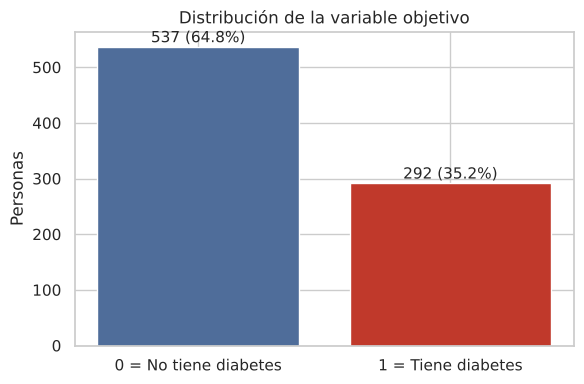

,Personas,% del total
0 = No tiene diabetes,537,64.777
1 = Tiene diabetes,292,35.223


In [5]:
conteo = df[OBJETIVO].value_counts().sort_index()
balance = pd.DataFrame({'Personas': conteo, '% del total': conteo / len(df) * 100})
balance.index = ['0 = No tiene diabetes', '1 = Tiene diabetes']

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(balance.index, balance['Personas'], color=[COLORES_CLASE[0], COLORES_CLASE[1]])
for i, (n, p) in enumerate(zip(balance['Personas'], balance['% del total'])):
    ax.text(i, n + 8, f'{n} ({p:.1f}%)', ha='center', fontsize=11)
ax.set_title('Distribución de la variable objetivo'); ax.set_ylabel('Personas')
plt.tight_layout(); plt.show()
balance

**Interpretación:** 537 personas (64.8%) no tienen diabetes y 292 (35.2%) sí la tienen. Hay un **desbalance moderado** (aproximadamente 2 a 1), no extremo como en los casos de fraude o morosidad (3% a 5%), por lo que no es necesario generar datos artificiales (*oversampling*). Lo que sí se hace es:
- Usar un **split estratificado** para que entrenamiento y prueba mantengan el 35% de personas con diabetes.
- **No juzgar a los modelos solo por la accuracy**: un modelo que dijera siempre "no tiene diabetes" tendría 64.8% de accuracy sin detectar a nadie. Por eso se reportan también recall, precision, F1 y AUC.

### 4.3 Ceros imposibles (datos faltantes)
En la tabla de calidad no hay valores nulos, pero sí hay **ceros**. Algunos ceros son válidos (una persona puede tener 0 embarazos), pero en otras variables **un cero es fisiológicamente imposible**: nadie vivo tiene glucosa, presión arterial, índice de masa corporal o grosor de piel igual a cero. Esos ceros son en realidad **datos faltantes** que se capturaron como 0 (por ejemplo, porque no se hizo la medición).

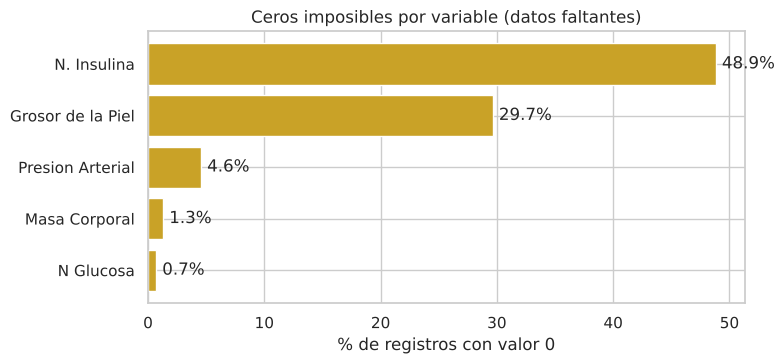

,Ceros,% de los registros
N. Insulina,405,48.854
Grosor de la Piel,246,29.674
Presion Arterial,38,4.584
Masa Corporal,11,1.327
N Glucosa,6,0.724


In [6]:
CEROS_IMPOSIBLES = ['N Glucosa', 'Presion Arterial', 'Grosor de la Piel', 'N. Insulina', 'Masa Corporal']
ceros = pd.DataFrame({'Ceros': (df[CEROS_IMPOSIBLES] == 0).sum()})
ceros['% de los registros'] = ceros['Ceros'] / len(df) * 100
ceros = ceros.sort_values('Ceros', ascending=False)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(ceros.index[::-1], ceros['% de los registros'][::-1], color=DORADO)
for y_, v in enumerate(ceros['% de los registros'][::-1]):
    ax.text(v + 0.5, y_, f'{v:.1f}%', va='center')
ax.set_xlabel('% de registros con valor 0'); ax.set_title('Ceros imposibles por variable (datos faltantes)')
plt.tight_layout(); plt.show()
ceros

**Interpretación:**
- **N. Insulina** tiene 405 ceros (**48.9%** de los registros): a casi la mitad de las personas no se les midió. Si se rellenaran esos valores, la mitad de la variable sería inventada.
- **Grosor de la Piel** tiene 246 ceros (**29.7%**), también una proporción alta.
- **Presión Arterial** (38 ceros, 4.6%), **Masa Corporal** (11, 1.3%) y **N Glucosa** (6, 0.7%) tienen pocos faltantes, que se pueden imputar sin distorsionar la variable.

Estos ceros se tratan como datos faltantes en el resto del análisis. La proporción de faltantes es uno de los criterios para decidir qué variables conservar (sección 4.9).

### 4.4 Distribución de las variables independientes
Se grafica el histograma de cada variable, separando a las personas **con diabetes (rojo)** y **sin diabetes (azul)**. Si las dos distribuciones están desplazadas una respecto de la otra, la variable ayuda a distinguir las clases; si se enciman por completo, aporta poco. En esta gráfica los ceros imposibles ya **no se dibujan** (se tratan como faltantes) para no deformar las distribuciones.

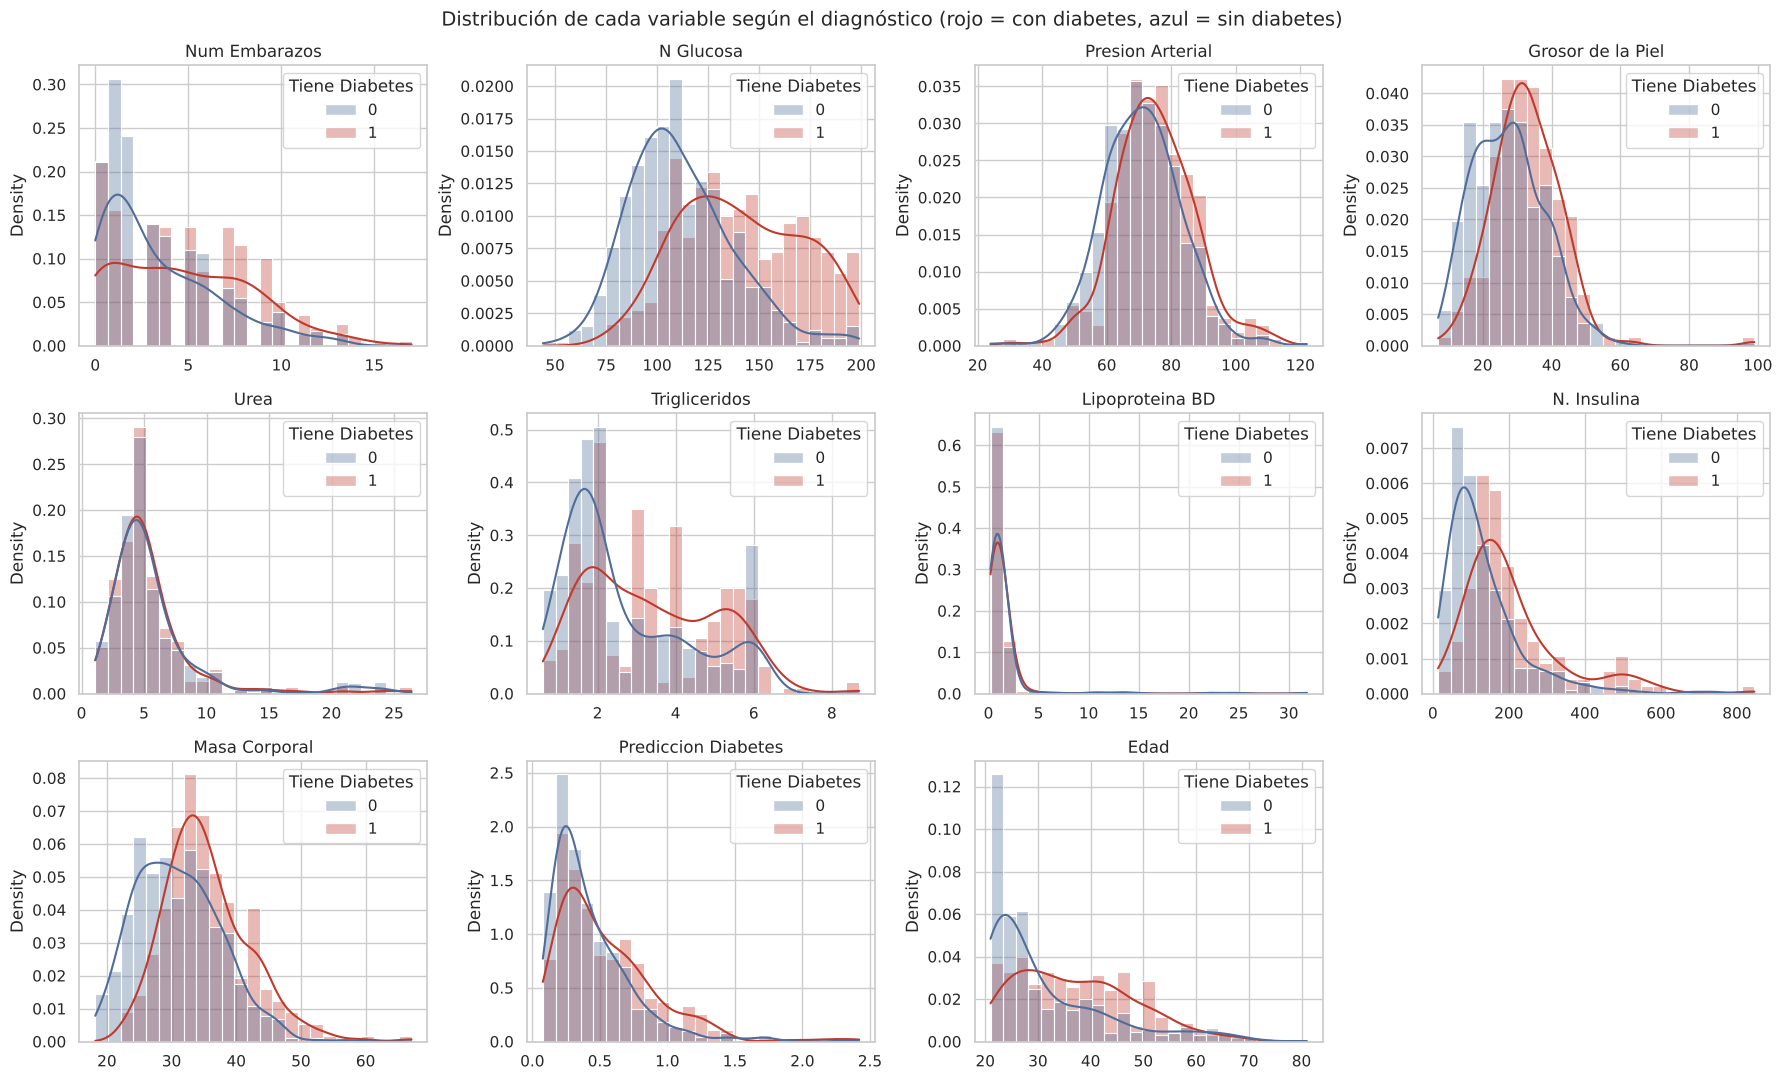

In [7]:
datos_eda = df.copy()
datos_eda[CEROS_IMPOSIBLES] = datos_eda[CEROS_IMPOSIBLES].replace(0, np.nan)

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, v in zip(axes.ravel(), CANDIDATAS):
    sns.histplot(data=datos_eda, x=v, hue=OBJETIVO, bins=25, kde=True, stat='density',
                 common_norm=False, palette=[COLORES_CLASE[0], COLORES_CLASE[1]], alpha=0.35, ax=ax)
    ax.set_title(v); ax.set_xlabel('')
axes.ravel()[-1].set_visible(False)
plt.suptitle('Distribución de cada variable según el diagnóstico (rojo = con diabetes, azul = sin diabetes)', fontsize=14)
plt.tight_layout(); plt.show()

**Interpretación:**
- **N Glucosa** muestra la separación más clara: la distribución de las personas con diabetes (rojo) está claramente desplazada hacia valores altos; la mayoría de las personas sin diabetes se concentra alrededor de 100 y las que tienen diabetes se reparten entre 120 y 200.
- **Masa Corporal**, **Edad** y **N. Insulina** también se desplazan hacia la derecha en las personas con diabetes. La edad tiene sesgo a la derecha: la mayoría de las personas tiene entre 21 y 30 años, y en ese grupo predominan las personas sin diabetes.
- **Num Embarazos**, **Trigliceridos**, **Prediccion Diabetes** y **Grosor de la Piel** tienen un desplazamiento menor, pero visible.
- **Presion Arterial** casi se encima entre las dos clases.
- **Urea** y **Lipoproteina BD** se enciman por completo: las curvas roja y azul son prácticamente iguales, es decir, **no distinguen** a las personas con y sin diabetes. Lipoproteína BD además tiene una cola de valores muy alejados (hasta 31.8).

### 4.5 Diagramas de caja por clase
El diagrama de caja muestra la mediana (línea central), el 50% central de los datos (la caja) y los valores atípicos (puntos). Comparar la caja de las personas con y sin diabetes permite ver **qué variables separan las clases** y detectar valores extremos.

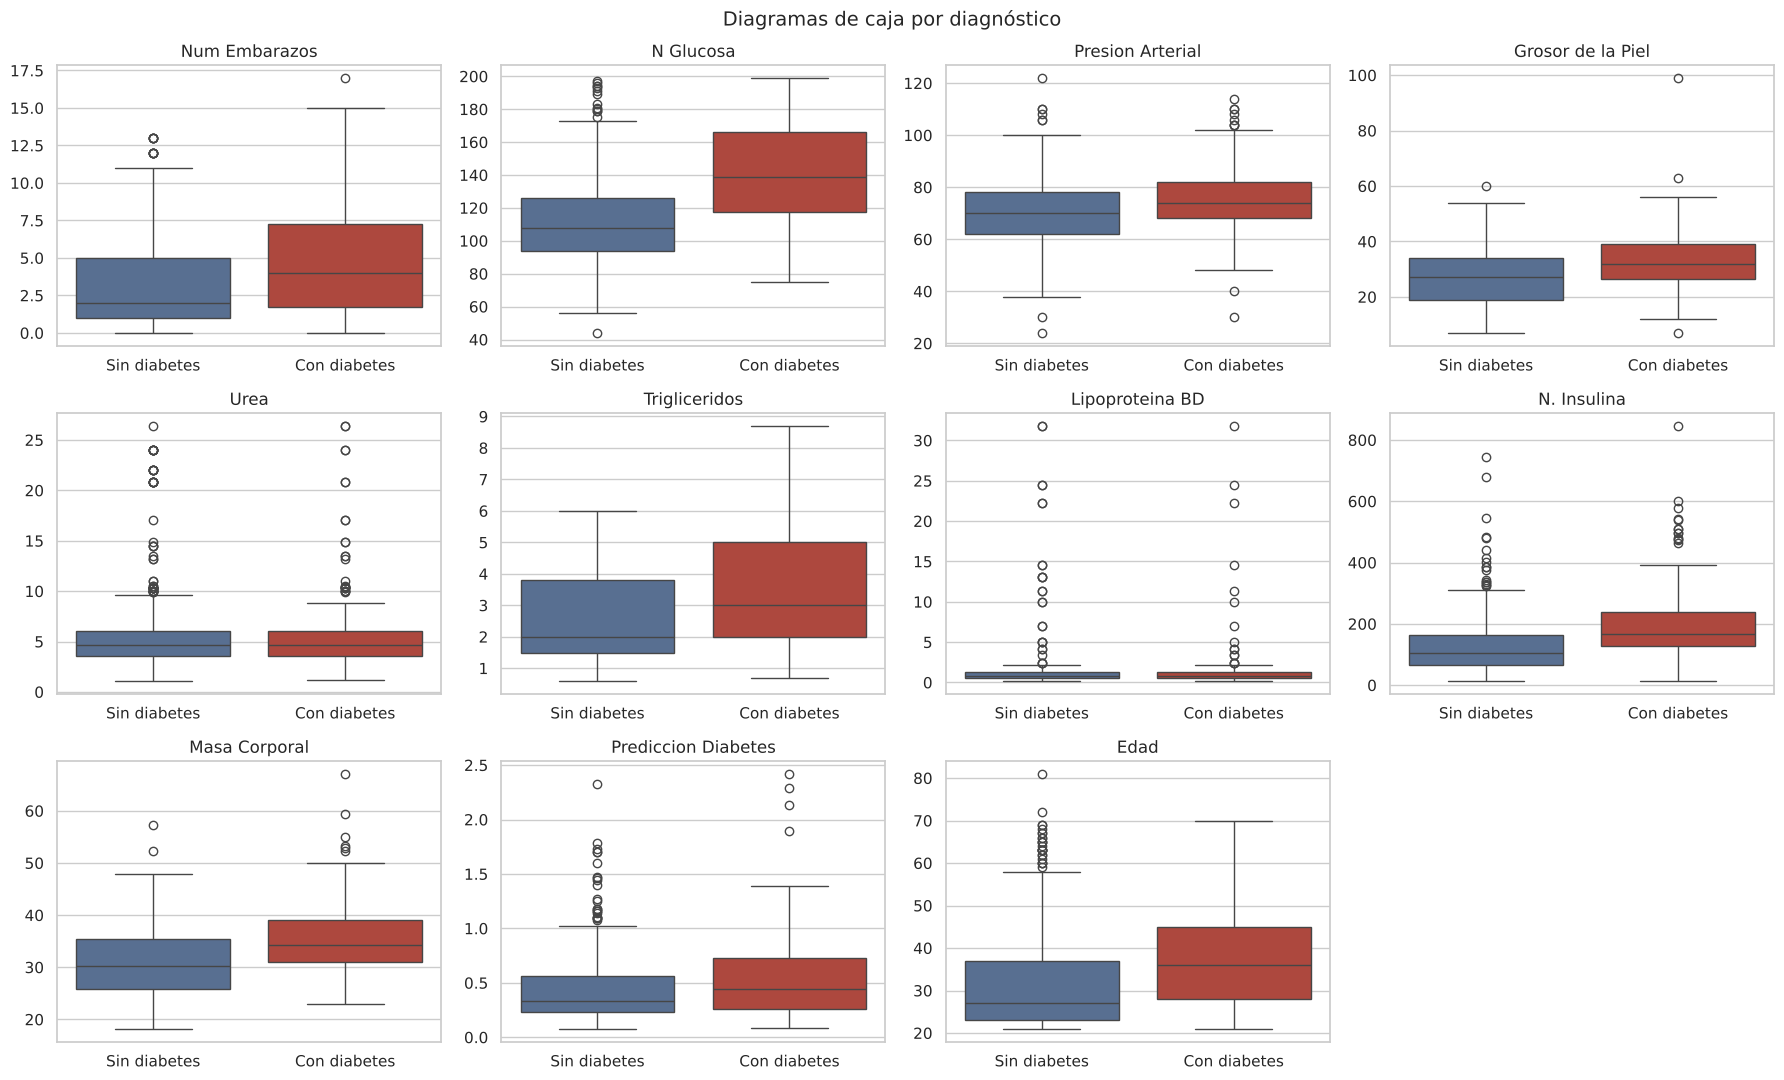

Mediana de cada variable por clase:


,Sin diabetes,Con diabetes,Diferencia
Num Embarazos,2.000,4.000,2.000
N Glucosa,108.000,139.000,31.000
Presion Arterial,70.000,74.000,4.000
Grosor de la Piel,27.000,32.000,5.000
Urea,4.700,4.700,0.000
Trigliceridos,2.000,3.000,1.000
Lipoproteina BD,0.800,0.850,0.050
N. Insulina,105.000,168.000,63.000
Masa Corporal,30.300,34.300,4.000
Prediccion Diabetes,0.336,0.441,0.105


In [8]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, v in zip(axes.ravel(), CANDIDATAS):
    sns.boxplot(data=datos_eda, x=OBJETIVO, y=v, hue=OBJETIVO, palette=[COLORES_CLASE[0], COLORES_CLASE[1]], legend=False, ax=ax)
    ax.set_title(v); ax.set_xlabel(''); ax.set_ylabel('')
    ax.set_xticklabels(['Sin diabetes', 'Con diabetes'])
axes.ravel()[-1].set_visible(False)
plt.suptitle('Diagramas de caja por diagnóstico', fontsize=14)
plt.tight_layout(); plt.show()

print('Mediana de cada variable por clase:')
medianas = datos_eda.groupby(OBJETIVO)[CANDIDATAS].median().T
medianas.columns = ['Sin diabetes', 'Con diabetes']
medianas['Diferencia'] = medianas['Con diabetes'] - medianas['Sin diabetes']
medianas

**Interpretación:** las cajas confirman lo observado en los histogramas.
- Las mayores diferencias de mediana entre personas con y sin diabetes están en **N Glucosa** (139 contra 108), **Edad** (36 contra 27 años), **Masa Corporal** (34.3 contra 30.3), **N. Insulina** (168 contra 105) y **Num Embarazos** (4 contra 2).
- **Urea** tiene exactamente la misma mediana en ambas clases (4.7) y **Lipoproteina BD** casi la misma (0.85 contra 0.80): no aportan separación.
- Hay puntos atípicos en casi todas las variables; los casos de Urea y Lipoproteína BD son los más llamativos y se revisan a continuación.

### 4.6 Valores atípicos
Se cuentan los valores atípicos con el criterio de la puntuación z (más de 3 desviaciones estándar de la media) y se revisan los casos más llamativos de los diagramas de caja: **Lipoproteína BD** y **Urea**. No todo valor atípico es un error: hay que distinguir entre un **error de captura** (un valor imposible) y un **caso real extremo** (una persona con un valor alto pero posible).

In [9]:
z = (datos_eda[CANDIDATAS] - datos_eda[CANDIDATAS].mean()) / datos_eda[CANDIDATAS].std()
atipicos = pd.DataFrame({'Valores con |z| > 3': (z.abs() > 3).sum()})
print(atipicos[atipicos.iloc[:, 0] > 0].sort_values(atipicos.columns[0], ascending=False))

print('\nLipoproteina BD: valores distintos por encima de 5 ->',
      sorted(df.loc[df['Lipoproteina BD'] > 5, 'Lipoproteina BD'].unique()))
print('Lipoproteina BD: registros > 5 =', (df['Lipoproteina BD'] > 5).sum(),
      '| mediana general =', df['Lipoproteina BD'].median())
print('Urea: registros > 15 =', (df['Urea'] > 15).sum(), '| mediana general =', df['Urea'].median())

print('\n% con diabetes según si el valor es atípico o no:')
pd.DataFrame({
    'Lipoproteina BD > 5': df.groupby(df['Lipoproteina BD'] > 5)[OBJETIVO].mean() * 100,
    'Urea > 15': df.groupby(df['Urea'] > 15)[OBJETIVO].mean() * 100,
}).rename(index={False: 'Valor normal', True: 'Valor atípico'})

                     Valores con |z| > 3
Urea                                  27
Lipoproteina BD                       18
Prediccion Diabetes                   12
Presion Arterial                       9
N. Insulina                            8
Masa Corporal                          5
Edad                                   5
Num Embarazos                          4
Trigliceridos                          2
Grosor de la Piel                      2

Lipoproteina BD: valores distintos por encima de 5 -> [np.float64(7.0), np.float64(10.0), np.float64(11.3), np.float64(13.1), np.float64(14.5), np.float64(22.2), np.float64(24.5), np.float64(31.8)]
Lipoproteina BD: registros > 5 = 24 | mediana general = 0.8
Urea: registros > 15 = 30 | mediana general = 4.7

% con diabetes según si el valor es atípico o no:


,Lipoproteina BD > 5,Urea > 15
Valor normal,35.404,35.544
Valor atípico,29.167,26.667


**Interpretación:**
- **Lipoproteina BD:** 24 registros tienen valores entre 7 y 31.8, cuando la mediana es 0.8 (hasta 40 veces más). Además solo hay 8 valores distintos repetidos (7.0, 10.0, 11.3, 13.1, 14.5, 22.2, 24.5 y 31.8), lo que sugiere **errores de captura** (por ejemplo, un punto decimal mal colocado o una unidad distinta) más que casos reales.
- **Urea:** 30 registros superan 15 (mediana 4.7). Valores altos de urea son posibles en personas con problemas renales, así que podrían ser **casos reales extremos**.
- En ninguna de las dos variables los valores atípicos se asocian a más diabetes: el porcentaje con diabetes es incluso menor en los atípicos (29.2% y 26.7%) que en el resto (≈ 35%).
- En el resto de las variables los atípicos son pocos (entre 2 y 12) y corresponden a valores clínicamente posibles (por ejemplo, edades de hasta 81 años o 17 embarazos), por lo que **se conservan**: con 829 registros, eliminarlos significaría perder información real.

### 4.7 Correlación
Se calcula la correlación de Pearson entre todas las variables (ignorando los ceros imposibles). Sirve para dos cosas:
1. Ver qué variables tienen **mayor relación con Tiene Diabetes** (columna inferior del mapa de calor).
2. Detectar **variables redundantes**: dos variables independientes muy correlacionadas entre sí aportan casi la misma información.

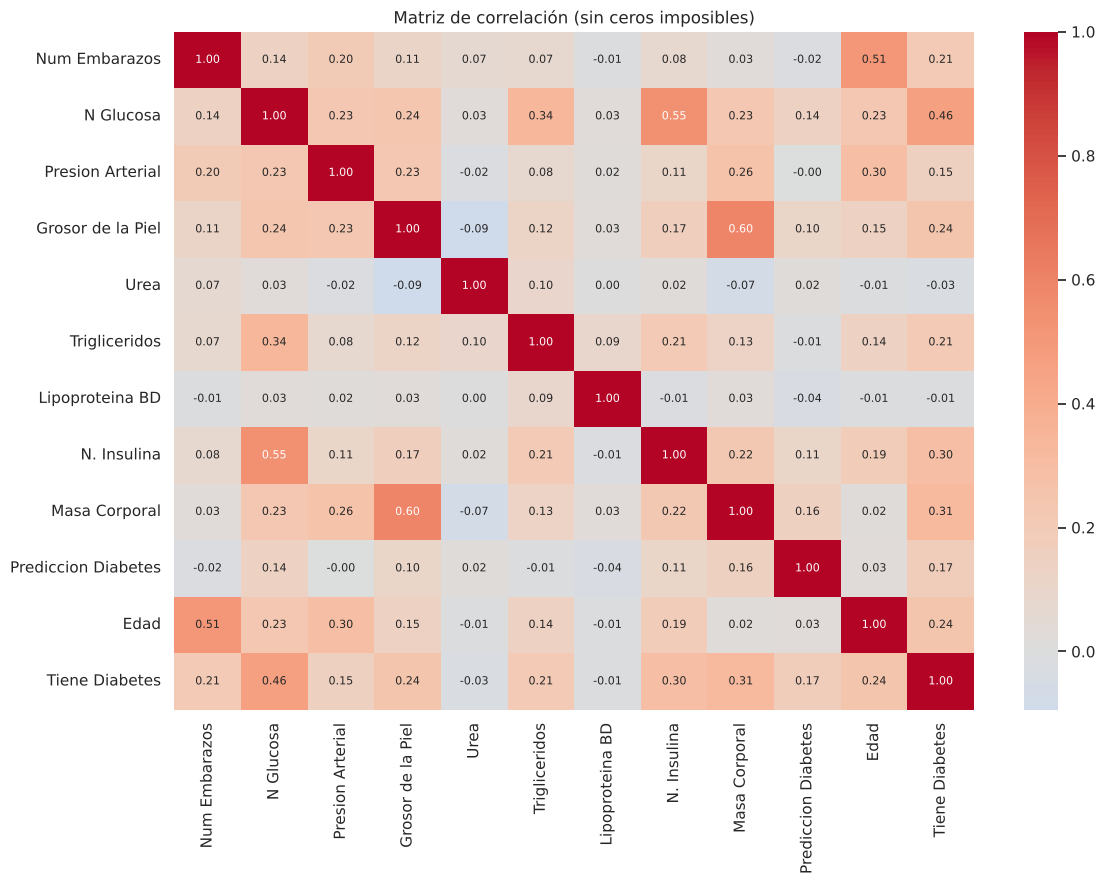

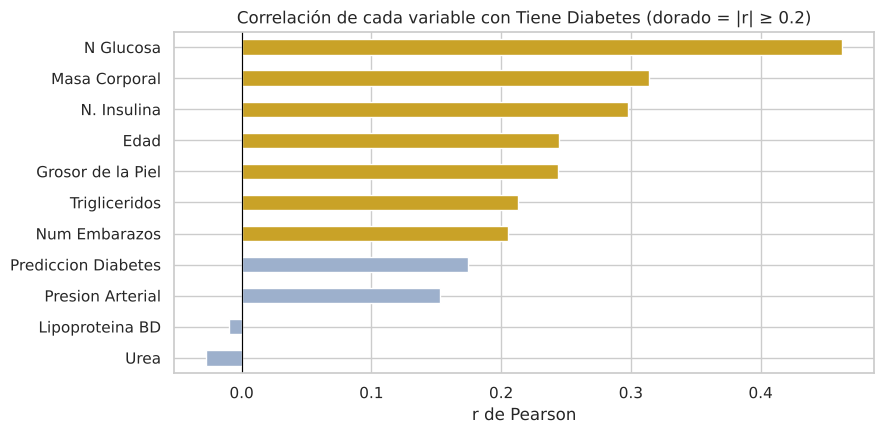

Pares de variables independientes con |r| ≥ 0.5:
Num Embarazos      Edad            0.510
N Glucosa          N. Insulina     0.550
Grosor de la Piel  Masa Corporal   0.600


In [10]:
corr = datos_eda[CANDIDATAS + [OBJETIVO]].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Matriz de correlación (sin ceros imposibles)'); plt.tight_layout(); plt.show()

corr_obj = corr[OBJETIVO].drop(OBJETIVO).sort_values()
plt.figure(figsize=(9, 4.5))
corr_obj.plot.barh(color=[DORADO if abs(v) >= 0.2 else GRIS for v in corr_obj])
plt.axvline(0, color='black', lw=0.8)
plt.title('Correlación de cada variable con Tiene Diabetes (dorado = |r| ≥ 0.2)'); plt.xlabel('r de Pearson')
plt.tight_layout(); plt.show()

print('Pares de variables independientes con |r| ≥ 0.5:')
pares = corr.loc[CANDIDATAS, CANDIDATAS].where(np.triu(np.ones((len(CANDIDATAS),) * 2), 1).astype(bool)).stack()
print(pares[pares.abs() >= 0.5].round(2).to_string())

**Interpretación:**
- Las variables más relacionadas con tener diabetes son **N Glucosa (r = 0.46)**, **Masa Corporal (0.31)**, **N. Insulina (0.30)**, **Edad (0.25)** y **Grosor de la Piel (0.24)**. Todas las correlaciones son positivas: a mayor valor, mayor proporción de personas con diabetes.
- **Urea (−0.03)** y **Lipoproteina BD (−0.01)** tienen correlación prácticamente nula.
- Hay tres pares de variables independientes moderadamente correlacionados:
  - **Grosor de la Piel y Masa Corporal (r = 0.60):** ambas miden grasa corporal, por lo que aportan información parecida.
  - **N Glucosa y N. Insulina (r = 0.55):** la insulina está ligada al nivel de glucosa.
  - **Num Embarazos y Edad (r = 0.51):** las personas de más edad han tenido más embarazos.

### 4.8 Poder de separación de cada variable por sí sola
Para resumir el EDA se calcula, para cada variable, el **AUC individual**: qué tan bien separa a las personas con y sin diabetes si se usara **ella sola** para clasificar. Un AUC de 0.5 equivale a lanzar una moneda (no separa nada) y 1.0 sería una separación perfecta. Se incluye también el porcentaje de datos faltantes de cada variable.

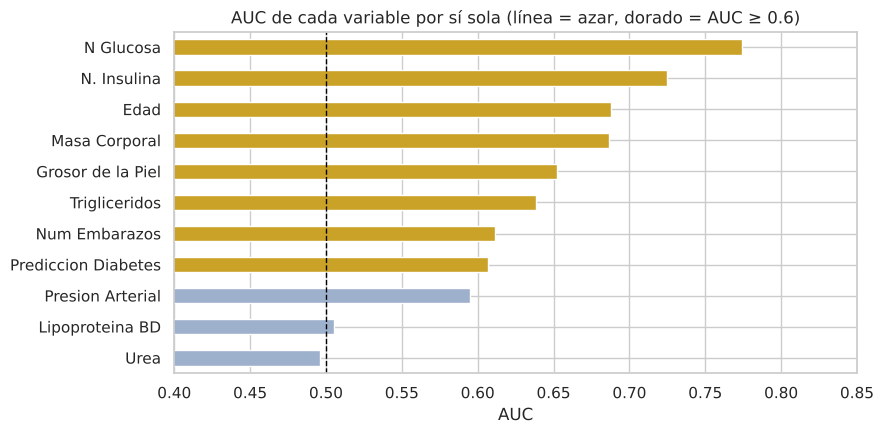

,% faltantes,r con Y,AUC individual
N Glucosa,0.724,0.463,0.774
N. Insulina,48.854,0.298,0.725
Edad,0.000,0.245,0.688
Masa Corporal,1.327,0.314,0.686
Grosor de la Piel,29.674,0.244,0.652
Trigliceridos,0.000,0.213,0.638
Num Embarazos,0.000,0.205,0.612
Prediccion Diabetes,0.000,0.174,0.607
Presion Arterial,4.584,0.153,0.595
Lipoproteina BD,0.000,-0.010,0.506


In [11]:
def auc_individual(v):
    m = datos_eda[v].notna()
    return roc_auc_score(datos_eda.loc[m, OBJETIVO], datos_eda.loc[m, v])

resumen_eda = pd.DataFrame({
    '% faltantes': datos_eda[CANDIDATAS].isna().mean() * 100,
    'r con Y': corr_obj,
    'AUC individual': [auc_individual(v) for v in CANDIDATAS],
}, index=CANDIDATAS).sort_values('AUC individual', ascending=False)

plt.figure(figsize=(9, 4.5))
resumen_eda['AUC individual'][::-1].plot.barh(color=[DORADO if a >= 0.6 else GRIS for a in resumen_eda['AUC individual'][::-1]])
plt.axvline(0.5, color='black', ls='--', lw=1); plt.xlim(0.4, 0.85)
plt.title('AUC de cada variable por sí sola (línea = azar, dorado = AUC ≥ 0.6)'); plt.xlabel('AUC')
plt.tight_layout(); plt.show()
resumen_eda

**Interpretación:**
- **N Glucosa** es la variable que mejor separa por sí sola (AUC = 0.77), seguida de **N. Insulina (0.73)**, **Edad (0.69)** y **Masa Corporal (0.69)**.
- **Urea (0.50)** y **Lipoproteina BD (0.51)** tienen un AUC igual al azar: usadas solas, clasificarían igual que lanzar una moneda.
- **N. Insulina** separa bien, pero ese AUC se calcula solo con la mitad de las personas que sí tienen la medición (48.9% faltante).
- Ninguna variable separa casi perfectamente por sí sola (AUC cercano a 1), así que **no hay una variable que por sí misma defina el diagnóstico**; esto se revisa con los modelos en la sección 12.1.

### 4.9 Decisión de variables
Con base en el EDA, estas son las variables que se usan en los modelos y la justificación de cada decisión:

| Variable | Decisión | Justificación |
|---|---|---|
| N Glucosa | ✅ Se usa | La que mejor separa las clases (AUC = 0.77, r = 0.46). Solo 6 faltantes, que se imputan |
| Masa Corporal | ✅ Se usa | Buena separación (AUC = 0.69, r = 0.31). 11 faltantes |
| Edad | ✅ Se usa | Buena separación (AUC = 0.69, r = 0.25). Sin faltantes |
| Trigliceridos | ✅ Se usa | Separación moderada (AUC = 0.64, r = 0.21). Sin faltantes |
| Num Embarazos | ✅ Se usa | Separación moderada (AUC = 0.61, r = 0.21). **Supuesto:** el archivo no tiene una columna de sexo y todas las personas son adultas; se asume que todas son mujeres. Si hubiera hombres, esta variable sesgaría el modelo y habría que eliminarla. Su correlación con Edad (0.51) es moderada, así que ambas se conservan |
| Prediccion Diabetes | ✅ Se usa | Separación moderada (AUC = 0.61, r = 0.17). Sin faltantes. Representa antecedentes familiares, información que ninguna otra variable aporta |
| Presion Arterial | ✅ Se usa | Separación débil (AUC = 0.60, r = 0.15), pero es clínicamente relevante y solo tiene 4.6% de faltantes. Su aporte real se mide en la sección 12 |
| N. Insulina | ❌ Se descarta | **48.9% de datos faltantes**: imputarla significaría inventar casi la mitad de sus valores. Además, parte de su información ya la aporta N Glucosa (r = 0.55) |
| Grosor de la Piel | ❌ Se descarta | **29.7% de datos faltantes** y es **redundante** con Masa Corporal (r = 0.60), que separa mejor y casi no tiene faltantes |
| Urea | ❌ Se descarta | **No separa las clases**: AUC = 0.50 (azar), r = −0.03 y la misma mediana en ambas clases |
| Lipoproteina BD | ❌ Se descarta | **No separa las clases** (AUC = 0.51, r = −0.01) y tiene 24 valores imposibles por errores de captura |
| Persona | ❌ No se usa | Es un identificador, no una característica clínica. Se conserva aparte (junto con Registro) para identificar a las personas en los errores del modelo |

Se trabaja entonces con **7 variables independientes**.

**Comprobación de la decisión.** Para confirmar que descartar esas cuatro variables no hace perder información, se compara el AUC de validación cruzada (5 particiones) de una regresión logística y de un Random Forest básicos, usando las 11 variables candidatas contra las 7 elegidas. La comparación se hace **solo con el 70% que después será el conjunto de entrenamiento** (mismo split y semilla de la sección 6), para que el conjunto de prueba no influya en la decisión.

In [12]:
cmp = df.copy()
cmp[CEROS_IMPOSIBLES] = cmp[CEROS_IMPOSIBLES].replace(0, np.nan)
cmp.loc[cmp['Lipoproteina BD'] > 5, 'Lipoproteina BD'] = np.nan      # valores imposibles
idx_train, _ = train_test_split(cmp.index, test_size=0.30, random_state=SEMILLA, stratify=cmp[OBJETIVO])
cmp = cmp.loc[idx_train]

ELEGIDAS = ['N Glucosa', 'Masa Corporal', 'Edad', 'Num Embarazos', 'Trigliceridos', 'Prediccion Diabetes', 'Presion Arterial']
cv_cmp = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
lr_basico = Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler()),
                      ('modelo', LogisticRegression(max_iter=40))])
rf_basico = Pipeline([('imputar', SimpleImputer(strategy='median')),
                      ('modelo', RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=SEMILLA))])
filas = {}
for nombre_conj, cols in [('11 variables candidatas', CANDIDATAS), ('7 variables elegidas', ELEGIDAS)]:
    filas[nombre_conj] = {
        'AUC Regresión Logística': cross_val_score(lr_basico, cmp[cols], cmp[OBJETIVO], cv=cv_cmp, scoring='roc_auc').mean(),
        'AUC Random Forest': cross_val_score(rf_basico, cmp[cols], cmp[OBJETIVO], cv=cv_cmp, scoring='roc_auc').mean()}
pd.DataFrame(filas).T

,AUC Regresión Logística,AUC Random Forest
11 variables candidatas,0.837,0.841
7 variables elegidas,0.842,0.846


**Interpretación:** con las 7 variables elegidas el AUC es **igual o ligeramente mejor** que con las 11 candidatas (0.842 contra 0.837 en regresión logística y 0.846 contra 0.841 en Random Forest). Es decir, las variables descartadas no aportaban información útil y quitarlas da un modelo **más simple, sin datos inventados y sin perder capacidad de clasificación**.

## 5. Limpieza de datos
Con base en el EDA:
1. Los **ceros imposibles** de las variables conservadas (glucosa, presión arterial y masa corporal) se convierten en **valores faltantes (NaN)**. **Todavía no se rellenan**: el relleno (imputación) se hace después del split, usando solo los datos de entrenamiento (sección 7), para no filtrar información del conjunto de prueba.
2. Se arma la matriz **X** solo con las variables elegidas, el vector **y** con la variable objetivo y se guardan **Registro y Persona aparte** (no entran al modelo) para identificar después a las personas en los errores.

In [13]:
VARIABLES = ['N Glucosa', 'Masa Corporal', 'Edad', 'Num Embarazos',
             'Trigliceridos', 'Prediccion Diabetes', 'Presion Arterial']

datos = df.copy()
for v in ['N Glucosa', 'Presion Arterial', 'Masa Corporal']:
    datos[v] = datos[v].replace(0, np.nan)

X = datos[VARIABLES]
y = datos[OBJETIVO]
identificacion = datos[['Registro', 'Persona']]

print('X:', X.shape, '| y:', y.shape)
print('Valores faltantes por variable (se imputarán con la mediana del entrenamiento):')
print(X.isna().sum().to_string())

X: (829, 7) | y: (829,)
Valores faltantes por variable (se imputarán con la mediana del entrenamiento):
N Glucosa               6
Masa Corporal          11
Edad                    0
Num Embarazos           0
Trigliceridos           0
Prediccion Diabetes     0
Presion Arterial       38


**Interpretación:** la matriz X tiene 829 registros y 7 variables. Quedan como faltantes 38 valores de presión arterial, 11 de masa corporal y 6 de glucosa (los ceros imposibles). Estos valores se rellenan en la sección 7 con la mediana calculada **únicamente con el conjunto de entrenamiento**.

## 6. Split de los datos: 70% entrenamiento y 30% prueba
Los datos se dividen **aleatoriamente** en dos conjuntos:
- **Entrenamiento (70%)**: con estos datos el algoritmo aprende los patrones.
- **Prueba (30%)**: datos que el modelo **nunca vio**; con ellos se mide de forma honesta qué tan bien clasifica a personas nuevas.

Se usa `random_state=SEMILLA` para que la división sea reproducible y `stratify=y` para que ambos conjuntos conserven la misma proporción de personas con diabetes que el total. La selección de quién va a cada conjunto sigue siendo aleatoria; la estratificación solo evita que por azar un conjunto quede con muy pocas personas con diabetes.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEMILLA, stratify=y)
id_test = identificacion.loc[X_test.index]

pd.DataFrame({
    'Registros': [len(X), len(X_train), len(X_test)],
    '% del total': [100, len(X_train) / len(X) * 100, len(X_test) / len(X) * 100],
    'Con diabetes': [y.sum(), y_train.sum(), y_test.sum()],
    '% con diabetes': [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
}, index=['Total', 'Entrenamiento', 'Prueba'])

,Registros,% del total,Con diabetes,% con diabetes
Total,829,100.000,292,35.223
Entrenamiento,580,69.964,204,35.172
Prueba,249,30.036,88,35.341


**Interpretación:** el conjunto de **entrenamiento** tiene 580 registros (70%), de los cuales 204 tienen diabetes, y el de **prueba** tiene 249 registros (30%), de los cuales 88 tienen diabetes. Ambos conservan prácticamente la misma proporción de personas con diabetes que el total (35.2% y 35.3% contra 35.2%), gracias a la estratificación.

## 7. Preparación de las variables sin fuga de información
Antes de entrenar se hacen dos transformaciones:
1. **Imputación con la mediana**: cada valor faltante se reemplaza por la mediana de su variable. Se usa la mediana y no la media porque no la afectan los valores extremos.
2. **Estandarización (`StandardScaler`)**: cada variable se transforma para que tenga media 0 y desviación estándar 1. Es necesaria para la Regresión Logística y KNN, porque si no las variables con números grandes (glucosa ≈ 120) dominarían a las de números pequeños (Predicción Diabetes ≈ 0.5). Los árboles y Random Forest no la necesitan, porque sus cortes no dependen de la escala; por eso en ellos solo se imputa y sus reglas quedan en las **unidades originales**.

**Punto clave:** la mediana y los parámetros de la estandarización se calculan **solo con el conjunto de entrenamiento** y después se aplican al de prueba. Si se calcularan con todos los datos, el conjunto de prueba "se asomaría" al entrenamiento (*data leakage*) y las métricas saldrían infladas. Para garantizarlo se usa un `Pipeline`, que repite este orden automáticamente en cada entrenamiento y en cada partición de la validación cruzada.

In [15]:
# Ejemplo de lo que aprende la preparación a partir del entrenamiento
prep = Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())]).fit(X_train)
pd.DataFrame({
    'Mediana usada para imputar (entrenamiento)': prep.named_steps['imputar'].statistics_,
    'Media (entrenamiento)': prep.named_steps['escalar'].mean_,
    'Desv. estándar (entrenamiento)': prep.named_steps['escalar'].scale_,
    'Media en prueba ya estandarizada': prep.transform(X_test).mean(axis=0),
}, index=VARIABLES)

,Mediana usada para imputar (entrenamiento),Media (entrenamiento),Desv. estándar (entrenamiento),Media en prueba ya estandarizada
N Glucosa,118.000,122.316,30.716,-0.048
Masa Corporal,32.000,32.319,6.933,0.099
Edad,29.000,33.348,11.914,-0.009
Num Embarazos,3.000,3.883,3.338,-0.008
Trigliceridos,2.200,2.913,1.623,0.001
Prediccion Diabetes,0.376,0.472,0.327,-0.030
Presion Arterial,72.000,72.264,12.170,0.046


**Interpretación:** la mediana que se usa para rellenar cada variable se obtuvo solo del entrenamiento (por ejemplo, 118 para la glucosa, 32 para la masa corporal y 72 para la presión arterial). Al aplicar la misma estandarización al conjunto de prueba, sus medias no quedan exactamente en 0 (van de −0.05 a 0.10). Eso es lo **correcto**: el conjunto de prueba se transformó con parámetros que no conocían sus datos, tal como pasará con personas nuevas en la vida real.

## 8. Algoritmos de clasificación
Se entrenan cuatro algoritmos. Para cada uno se ajustan sus **hiperparámetros** (las "perillas" que controlan cómo aprende) usando **validación cruzada de 5 particiones dentro del entrenamiento** (`GridSearchCV`): se prueba cada combinación de perillas y se elige la que obtiene el mejor AUC promedio. El conjunto de prueba no se usa para elegir nada; solo para la evaluación final.

**Regla para elegir las perillas.** Varias combinaciones suelen quedar prácticamente empatadas en AUC de validación. En ese caso no conviene quedarse con la más compleja: entre las combinaciones que están a menos de 0.005 del mejor AUC de validación, se elige la que tiene **la menor diferencia entre el AUC de entrenamiento y el de validación**, es decir, la que **menos sobreajusta**. En cada tabla de búsqueda la combinación elegida se marca con ◄.

Primero se define una función que calcula las métricas de un modelo en **entrenamiento y en prueba**. Compararlas sirve para detectar **sobreajuste**: si un modelo es mucho mejor en entrenamiento que en prueba, memorizó los datos en lugar de aprender patrones generales.

In [16]:
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
MODELOS = {}      # modelo final de cada algoritmo

def metricas(modelo, Xc, yc, umbral=0.5):
    prob = modelo.predict_proba(Xc)[:, 1]
    pred = (prob >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(yc, pred).ravel()
    return {'Accuracy': accuracy_score(yc, pred), 'Precision': precision_score(yc, pred),
            'Recall': recall_score(yc, pred), 'Especificidad': vn / (vn + fp),
            'F1': f1_score(yc, pred), 'AUC': roc_auc_score(yc, prob)}

def entrenamiento_vs_prueba(nombre, modelo):
    t = pd.DataFrame({'Entrenamiento': metricas(modelo, X_train, y_train),
                      'Prueba': metricas(modelo, X_test, y_test)}).T
    t.index.name = nombre
    return t

def menos_sobreajuste(cv_results, tolerancia=0.005):
    # Entre las combinaciones cuyo AUC de validación está a menos de `tolerancia` del mejor,
    # elige la que tiene la menor diferencia entre entrenamiento y validación (menos sobreajuste)
    r = pd.DataFrame(cv_results)
    candidatas = r[r['mean_test_score'] >= r['mean_test_score'].max() - tolerancia]
    return int((candidatas['mean_train_score'] - candidatas['mean_test_score']).idxmin())

def tabla_busqueda(grid, n=8):
    r = pd.DataFrame(grid.cv_results_)
    cols = [c for c in r.columns if c.startswith('param_')]
    r['brecha'] = r['mean_train_score'] - r['mean_test_score']
    r['Elegida'] = np.where(r.index == grid.best_index_, '◄', '')
    r = r[cols + ['mean_train_score', 'mean_test_score', 'brecha', 'Elegida']].sort_values('mean_test_score', ascending=False)
    elegida = r[r['Elegida'] == '◄']
    r = pd.concat([r.head(n), elegida]).drop_duplicates()
    r.columns = [c.replace('param_modelo__', '') for c in cols] + ['AUC entren. (CV)', 'AUC validación (CV)', 'Brecha', 'Elegida']
    return r.reset_index(drop=True)

### 8.1 Regresión Logística
La regresión logística calcula una combinación lineal de las variables y la pasa por la **función sigmoide** (curva en forma de S), que la convierte en una **probabilidad entre 0 y 1** de tener diabetes. Si la probabilidad es mayor o igual al **umbral** (0.5 por defecto), la persona se clasifica como 1. Es el modelo de clasificación binaria más clásico: rápido y fácil de interpretar, porque cada variable tiene un coeficiente que indica si aumenta o disminuye el riesgo.

**Perillas:**
- `C`: inverso de la fuerza de regularización (penalización). Un `C` pequeño obliga a los coeficientes a ser pequeños (modelo más simple); uno grande los deja libres.
- `max_iter = 40`: número máximo de iteraciones para encontrar los coeficientes. Se limita para evitar iteraciones innecesarias; con las variables estandarizadas el algoritmo converge en muchas menos.

In [17]:
pipe_lr = Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler()),
                    ('modelo', LogisticRegression(max_iter=40, random_state=SEMILLA))])
grid_lr = GridSearchCV(pipe_lr, {'modelo__C': [0.001, 0.01, 0.1, 1, 10, 100]},
                       cv=CV5, scoring='roc_auc', return_train_score=True, refit=menos_sobreajuste).fit(X_train, y_train)
MODELOS['Regresión Logística'] = grid_lr.best_estimator_

print('Mejor C:', grid_lr.best_params_['modelo__C'],
      '| iteraciones usadas:', MODELOS['Regresión Logística'].named_steps['modelo'].n_iter_[0])
display(tabla_busqueda(grid_lr))
entrenamiento_vs_prueba('Regresión Logística', MODELOS['Regresión Logística'])

Mejor C: 0.1 | iteraciones usadas: 7


,C,AUC entren. (CV),AUC validación (CV),Brecha,Elegida
0,0.100,0.845,0.842,0.003,◄
1,1.000,0.845,0.842,0.003,
2,10.000,0.845,0.842,0.004,
3,100.000,0.845,0.842,0.004,
4,0.010,0.841,0.837,0.003,
5,0.001,0.833,0.831,0.002,


,Accuracy,Precision,Recall,Especificidad,F1,AUC
Regresión Logística,,,,,,
Entrenamiento,0.774,0.730,0.569,0.886,0.639,0.845
Prueba,0.747,0.705,0.489,0.888,0.577,0.800


**Interpretación:**
- Se eligió **C = 0.1**. Todos los valores de C desde 0.1 hasta 100 quedaron empatados en AUC de validación (0.842), y entre ellos 0.1 es el que menos sobreajusta. Con C muy pequeño (0.001) el modelo queda demasiado restringido y baja a 0.831.
- El modelo convergió en **7 iteraciones**, muy por debajo del límite de 40.
- En prueba obtuvo **accuracy = 0.747** y **AUC = 0.800**, muy cerca del entrenamiento (0.774 y 0.845). La brecha es pequeña, así que **no hay sobreajuste**.
- Su debilidad es el **recall en prueba de 0.489**: con el umbral de 0.5 solo detecta a 49% de las personas con diabetes. Este punto se trabaja en la sección 11.1.

### 8.2 Árbol de Decisión sin límite de profundidad
Un árbol de decisión hace una secuencia de **preguntas del tipo "¿la glucosa es mayor a X?"** que van dividiendo a las personas desde la raíz hasta las hojas, donde se asigna la clase. Es muy intuitivo y fácil de explicar, pero tiene una debilidad: si se le deja crecer sin límite, sigue haciendo preguntas hasta clasificar perfectamente cada registro de entrenamiento, es decir, **memoriza** los datos.

Primero se entrena un árbol **sin ninguna restricción** para observar ese sobreajuste.

In [18]:
arbol_libre = Pipeline([('imputar', SimpleImputer(strategy='median')),
                        ('modelo', DecisionTreeClassifier(random_state=SEMILLA))]).fit(X_train, y_train)
print('Profundidad alcanzada:', arbol_libre.named_steps['modelo'].get_depth(),
      '| número de hojas:', arbol_libre.named_steps['modelo'].get_n_leaves())
entrenamiento_vs_prueba('Árbol sin límite', arbol_libre)

Profundidad alcanzada: 16 | número de hojas: 93


,Accuracy,Precision,Recall,Especificidad,F1,AUC
Árbol sin límite,,,,,,
Entrenamiento,1.000,1.000,1.000,1.000,1.000,1.000
Prueba,0.719,0.618,0.534,0.820,0.573,0.677


**Interpretación:** el árbol sin límite creció hasta **16 niveles y 93 hojas** y obtuvo **1.000 en todas las métricas de entrenamiento**: clasificó perfecto a cada persona que vio. Pero en prueba su accuracy baja a **0.719** y su AUC a **0.677**. Es un caso claro de **sobreajuste**: memorizó los datos de entrenamiento, incluyendo su ruido, y no generaliza a personas nuevas. Por eso es necesario limitar su crecimiento.

### 8.3 Árbol de Decisión ajustado
Para evitar el sobreajuste se ajustan sus perillas:
- `criterion`: medida de impureza para decidir cada corte, **Gini** o **Entropía**.
- `max_depth`: profundidad máxima (cuántas preguntas seguidas puede hacer).
- `min_samples_leaf`: mínimo de personas que debe tener cada hoja; evita reglas basadas en uno o dos casos.

La gráfica muestra cómo cambia el AUC en entrenamiento y en validación cruzada al aumentar la profundidad: el punto donde la validación deja de mejorar (mientras el entrenamiento sigue subiendo) marca el inicio del sobreajuste.

Mejores perillas: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 5}


,criterion,max_depth,min_samples_leaf,AUC entren. (CV),AUC validación (CV),Brecha,Elegida
0,entropy,3,5,0.836,0.806,0.030,◄
1,entropy,3,20,0.837,0.806,0.030,
2,gini,5,30,0.864,0.805,0.059,
3,entropy,3,10,0.838,0.804,0.033,
4,entropy,5,20,0.876,0.804,0.072,
5,gini,10,30,0.866,0.804,0.062,
6,gini,7,30,0.866,0.804,0.062,
7,gini,9,30,0.866,0.804,0.062,


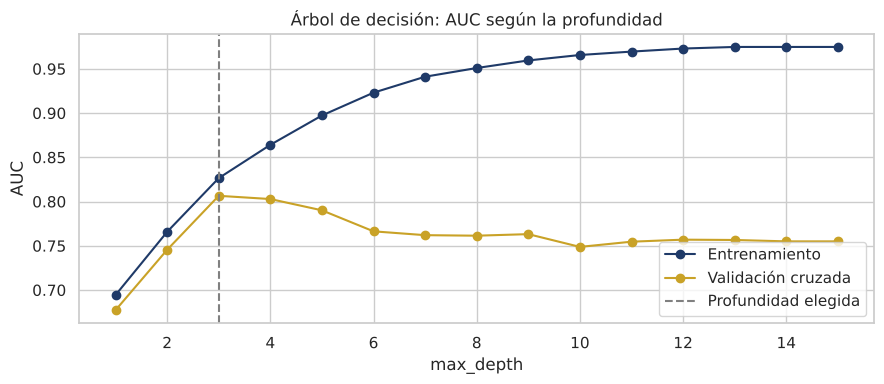

,Accuracy,Precision,Recall,Especificidad,F1,AUC
Árbol de Decisión,,,,,,
Entrenamiento,0.753,0.716,0.495,0.894,0.586,0.826
Prueba,0.691,0.596,0.386,0.857,0.469,0.730


In [19]:
pipe_arbol = Pipeline([('imputar', SimpleImputer(strategy='median')),
                       ('modelo', DecisionTreeClassifier(random_state=SEMILLA))])
grid_arbol = GridSearchCV(pipe_arbol, {'modelo__criterion': ['gini', 'entropy'],
                                       'modelo__max_depth': list(range(2, 11)),
                                       'modelo__min_samples_leaf': [1, 5, 10, 20, 30]},
                          cv=CV5, scoring='roc_auc', return_train_score=True, refit=menos_sobreajuste).fit(X_train, y_train)
MODELOS['Árbol de Decisión'] = grid_arbol.best_estimator_
mejor = grid_arbol.best_params_
print('Mejores perillas:', {k.replace('modelo__', ''): v for k, v in mejor.items()})
display(tabla_busqueda(grid_arbol))

# Curva de profundidad con el criterio y min_samples_leaf elegidos
prof = range(1, 16)
auc_tr, auc_cv = [], []
for d in prof:
    m = clone(pipe_arbol).set_params(modelo__criterion=mejor['modelo__criterion'], modelo__max_depth=d,
                                     modelo__min_samples_leaf=mejor['modelo__min_samples_leaf'])
    auc_cv.append(cross_val_score(m, X_train, y_train, cv=CV5, scoring='roc_auc').mean())
    auc_tr.append(roc_auc_score(y_train, m.fit(X_train, y_train).predict_proba(X_train)[:, 1]))
plt.figure(figsize=(9, 4))
plt.plot(prof, auc_tr, 'o-', color=AZUL, label='Entrenamiento')
plt.plot(prof, auc_cv, 'o-', color=DORADO, label='Validación cruzada')
plt.axvline(mejor['modelo__max_depth'], color='gray', ls='--', label='Profundidad elegida')
plt.xlabel('max_depth'); plt.ylabel('AUC'); plt.title('Árbol de decisión: AUC según la profundidad'); plt.legend()
plt.tight_layout(); plt.show()

entrenamiento_vs_prueba('Árbol de Decisión', MODELOS['Árbol de Decisión'])

**Interpretación:**
- La mejor combinación fue **criterio = entropía, max_depth = 3 y min_samples_leaf = 5**, con AUC de validación de **0.806**.
- La gráfica muestra el sobreajuste en acción: al aumentar la profundidad, el AUC de entrenamiento sube sin parar (hasta ≈ 0.97), pero el de validación alcanza su máximo en profundidad 3 y después **baja** hasta ≈ 0.75. A partir de ahí, cada nivel extra solo memoriza casos particulares.
- En prueba obtuvo **AUC = 0.730** y **accuracy = 0.691**, con una brecha de 0.097 respecto del entrenamiento. Mejoró mucho respecto del árbol sin límite (AUC 0.677), pero tiene el **recall más bajo de todos (0.386)**: un árbol de 3 niveles es demasiado simple para captar todos los casos.

**Reglas del árbol (puntos de división de las variables).** Una ventaja del árbol es que sus decisiones se pueden leer como reglas. Se dibujan los primeros niveles del árbol ajustado: cada caja muestra la pregunta (variable y valor de corte en unidades originales), cuántas personas llegan ahí, cuántas hay de cada clase (`value = [sin diabetes, con diabetes]`) y la clase mayoritaria. **Naranja = mayoría sin diabetes, azul = mayoría con diabetes**; el color más intenso indica un grupo más puro.

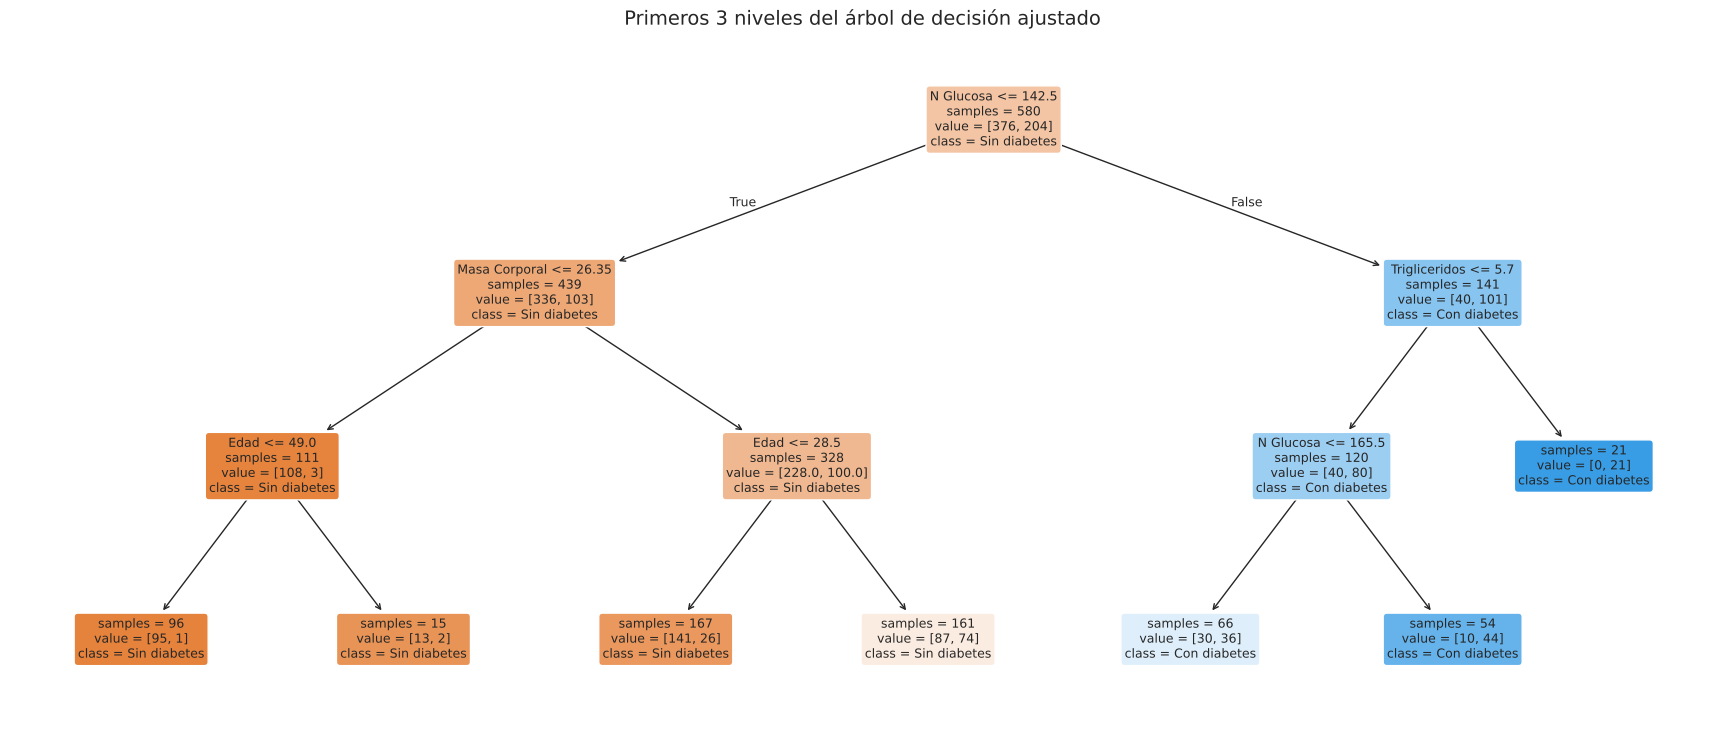

|--- N Glucosa <= 142.50
|   |--- Masa Corporal <= 26.35
|   |   |--- Edad <= 49.00
|   |   |   |--- weights: [95.00, 1.00] class: 0
|   |   |--- Edad >  49.00
|   |   |   |--- weights: [13.00, 2.00] class: 0
|   |--- Masa Corporal >  26.35
|   |   |--- Edad <= 28.50
|   |   |   |--- weights: [141.00, 26.00] class: 0
|   |   |--- Edad >  28.50
|   |   |   |--- weights: [87.00, 74.00] class: 0
|--- N Glucosa >  142.50
|   |--- Trigliceridos <= 5.70
|   |   |--- N Glucosa <= 165.50
|   |   |   |--- weights: [30.00, 36.00] class: 1
|   |   |--- N Glucosa >  165.50
|   |   |   |--- weights: [10.00, 44.00] class: 1
|   |--- Trigliceridos >  5.70
|   |   |--- weights: [0.00, 21.00] class: 1



In [20]:
arbol = MODELOS['Árbol de Decisión'].named_steps['modelo']
plt.figure(figsize=(22, 9))
plot_tree(arbol, feature_names=VARIABLES, class_names=['Sin diabetes', 'Con diabetes'], filled=True,
          rounded=True, max_depth=3, fontsize=9, impurity=False, proportion=False)
plt.title('Primeros 3 niveles del árbol de decisión ajustado', fontsize=14); plt.show()

print(export_text(arbol, feature_names=VARIABLES, max_depth=3, show_weights=True))

**Interpretación de las reglas (puntos de división):**
- **La primera pregunta del árbol es la glucosa: ¿N Glucosa ≤ 142.5?** Es la variable que mejor divide a las personas.
- **Glucosa > 142.5** (141 personas, 72% con diabetes):
  - Si además **Triglicéridos > 5.7**, las **21 personas** de ese grupo tienen diabetes (100%).
  - Si **Glucosa > 165.5**, 44 de 54 tienen diabetes (81%).
  - Entre 142.5 y 165.5 de glucosa, 36 de 66 (55%).
- **Glucosa ≤ 142.5** (439 personas, 23% con diabetes):
  - Con **Masa Corporal ≤ 26.35**, solo 3 de 111 tienen diabetes (3%).
  - Con masa corporal mayor y **Edad ≤ 28.5**, 26 de 167 (16%).
  - Con masa corporal mayor y **Edad > 28.5**, el riesgo sube a 74 de 161 (46%).

Los puntos de corte que usa el árbol (**glucosa ≈ 140 y 165, masa corporal ≈ 26, edad ≈ 28 y triglicéridos ≈ 5.7**) son los que se usan como referencia para los rangos críticos de la sección 13.

### 8.4 Random Forest
Random Forest construye **muchos árboles de decisión**, cada uno con una muestra aleatoria de las personas y de las variables, y clasifica por **votación** de todos los árboles. Al promediar árboles distintos, los errores individuales se compensan: es más robusto, más estable y sobreajusta menos que un solo árbol.

**Perillas:**
- `n_estimators`: número de árboles del bosque.
- `max_depth`: profundidad máxima de cada árbol.
- `min_samples_leaf`: mínimo de personas por hoja.
- `max_features`: cuántas variables puede considerar cada corte (`sqrt` = raíz cuadrada del total).

In [21]:
pipe_rf = Pipeline([('imputar', SimpleImputer(strategy='median')),
                    ('modelo', RandomForestClassifier(random_state=SEMILLA, n_jobs=-1))])
grid_rf = GridSearchCV(pipe_rf, {'modelo__n_estimators': [100, 300],
                                 'modelo__max_depth': [3, 5, 8, None],
                                 'modelo__min_samples_leaf': [1, 5, 10],
                                 'modelo__max_features': ['sqrt', None]},
                       cv=CV5, scoring='roc_auc', return_train_score=True, refit=menos_sobreajuste).fit(X_train, y_train)
MODELOS['Random Forest'] = grid_rf.best_estimator_
print('Mejores perillas:', {k.replace('modelo__', ''): v for k, v in grid_rf.best_params_.items()})
display(tabla_busqueda(grid_rf))
entrenamiento_vs_prueba('Random Forest', MODELOS['Random Forest'])

Mejores perillas: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 300}


,max_depth,max_features,min_samples_leaf,n_estimators,AUC entren. (CV),AUC validación (CV),Brecha,Elegida
0,None,sqrt,1,100,1.000,0.850,0.150,
1,8,sqrt,1,100,0.998,0.850,0.148,
2,5,sqrt,1,100,0.957,0.850,0.108,
3,5,sqrt,1,300,0.958,0.848,0.110,
4,None,sqrt,1,300,1.000,0.847,0.153,
5,8,sqrt,1,300,0.999,0.847,0.152,
6,5,sqrt,10,300,0.919,0.846,0.073,◄
7,8,sqrt,5,100,0.966,0.845,0.121,


,Accuracy,Precision,Recall,Especificidad,F1,AUC
Random Forest,,,,,,
Entrenamiento,0.822,0.802,0.657,0.912,0.722,0.916
Prueba,0.763,0.723,0.534,0.888,0.614,0.800


**Interpretación:**
- Las combinaciones con mayor AUC de validación (≈ 0.850) usaban árboles sin límite y hojas de 1 persona, pero tenían **AUC de entrenamiento de 1.000**: memorizaban los datos (brecha de 0.15).
- La regla de menor sobreajuste eligió **300 árboles, max_depth = 5, min_samples_leaf = 10 y max_features = sqrt**. Su AUC de validación es prácticamente el mismo (0.846), pero con la mitad de la brecha (0.073).
- En prueba obtuvo **AUC = 0.800**, **accuracy = 0.763**, **precision = 0.723** y **recall = 0.534**. Su brecha entre entrenamiento y prueba (0.916 contra 0.800) es mayor que la de la regresión logística, pero mucho menor que la de un bosque sin restricciones.

**Estabilidad ante la semilla.** Random Forest usa azar para construir sus árboles. Para comprobar que el resultado no depende de una semilla "afortunada", se reentrena el mismo modelo con otras semillas (35 y 50) y se comparan sus métricas en prueba.

In [22]:
semillas = {}
for s in [35, 42, 50]:
    m = clone(MODELOS['Random Forest']).set_params(modelo__random_state=s).fit(X_train, y_train)
    semillas[f'Semilla {s}'] = metricas(m, X_test, y_test)
semillas = pd.DataFrame(semillas).T
semillas.loc['Diferencia máx.'] = semillas.max() - semillas.min()
semillas

,Accuracy,Precision,Recall,Especificidad,F1,AUC
Semilla 35,0.755,0.708,0.523,0.882,0.601,0.798
Semilla 42,0.763,0.723,0.534,0.888,0.614,0.800
Semilla 50,0.755,0.714,0.511,0.888,0.596,0.795
Diferencia máx.,0.008,0.015,0.023,0.006,0.018,0.005


**Interpretación:** al cambiar la semilla a 35 o 50, las métricas casi no cambian: la diferencia máxima es de **0.005 en AUC**, 0.008 en accuracy y 0.023 en recall. El resultado de Random Forest es **estable** y no depende de una semilla afortunada.

### 8.5 K Vecinos Más Cercanos (KNN), modelo adicional de comparación
KNN clasifica a una persona nueva buscando a las **K personas más parecidas** del entrenamiento (las más cercanas en el espacio de las variables) y le asigna la clase mayoritaria entre ellas. Por trabajar con distancias, **necesita las variables estandarizadas**.

**Perillas:**
- `n_neighbors` (K): cuántos vecinos votan. Un K muy pequeño se deja llevar por casos aislados (sobreajuste); uno muy grande pierde detalle.
- `metric`: forma de medir la distancia. **Euclidiana** (línea recta) o **Manhattan** (suma de diferencias absolutas, menos sensible a una variable con una diferencia muy grande).

Mejores perillas: {'metric': 'manhattan', 'n_neighbors': 11}


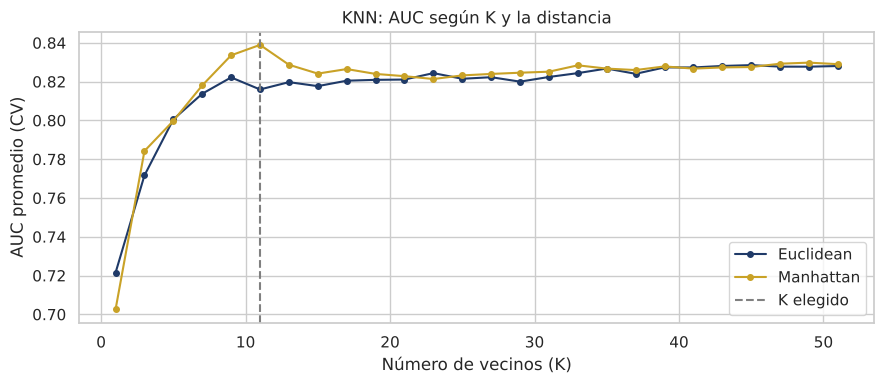

,Accuracy,Precision,Recall,Especificidad,F1,AUC
KNN,,,,,,
Entrenamiento,0.788,0.740,0.613,0.883,0.670,0.885
Prueba,0.727,0.647,0.500,0.851,0.564,0.748


In [23]:
pipe_knn = Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler()),
                     ('modelo', KNeighborsClassifier())])
grid_knn = GridSearchCV(pipe_knn, {'modelo__n_neighbors': list(range(1, 52, 2)),
                                   'modelo__metric': ['euclidean', 'manhattan']},
                        cv=CV5, scoring='roc_auc', return_train_score=True, refit=menos_sobreajuste).fit(X_train, y_train)
MODELOS['KNN'] = grid_knn.best_estimator_
print('Mejores perillas:', {k.replace('modelo__', ''): v for k, v in grid_knn.best_params_.items()})

r = pd.DataFrame(grid_knn.cv_results_)
plt.figure(figsize=(9, 4))
for met, col in [('euclidean', AZUL), ('manhattan', DORADO)]:
    s = r[r['param_modelo__metric'] == met]
    plt.plot(s['param_modelo__n_neighbors'], s['mean_test_score'], 'o-', ms=4, color=col, label=met.capitalize())
plt.axvline(grid_knn.best_params_['modelo__n_neighbors'], color='gray', ls='--', label='K elegido')
plt.xlabel('Número de vecinos (K)'); plt.ylabel('AUC promedio (CV)'); plt.title('KNN: AUC según K y la distancia')
plt.legend(); plt.tight_layout(); plt.show()

entrenamiento_vs_prueba('KNN', MODELOS['KNN'])

**Interpretación:**
- La mejor configuración fue **distancia Manhattan con K = 11 vecinos**. En la gráfica, con K muy pequeño (1 o 3) el AUC es bajo porque el modelo se deja llevar por casos aislados. Manhattan alcanza su máximo en K = 11 (≈ 0.84) y a partir de ahí ambas distancias se estabilizan alrededor de 0.82–0.83.
- En prueba obtuvo **AUC = 0.748** y **recall = 0.500**, con una brecha de 0.136 respecto del entrenamiento (0.885). Queda por debajo de la regresión logística y de Random Forest.

### 8.6 Comparación entre entrenamiento y prueba (detección de sobreajuste)
Se reúnen las métricas de todos los modelos. La columna **Brecha AUC** es la diferencia entre el AUC de entrenamiento y el de prueba: una brecha grande indica sobreajuste.

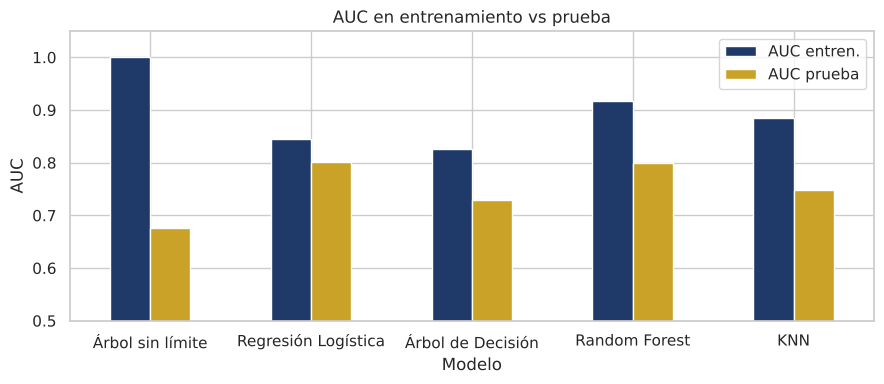

,Accuracy entren.,Accuracy prueba,AUC entren.,AUC prueba,Brecha AUC
Modelo,,,,,
Árbol sin límite,1.000,0.719,1.000,0.677,0.323
Regresión Logística,0.774,0.747,0.845,0.800,0.044
Árbol de Decisión,0.753,0.691,0.826,0.730,0.097
Random Forest,0.822,0.763,0.916,0.800,0.116
KNN,0.788,0.727,0.885,0.748,0.136


In [24]:
comparacion = []
for nombre, m in [('Árbol sin límite', arbol_libre)] + list(MODELOS.items()):
    tr, te = metricas(m, X_train, y_train), metricas(m, X_test, y_test)
    comparacion.append({'Modelo': nombre, 'Accuracy entren.': tr['Accuracy'], 'Accuracy prueba': te['Accuracy'],
                        'AUC entren.': tr['AUC'], 'AUC prueba': te['AUC'], 'Brecha AUC': tr['AUC'] - te['AUC']})
comparacion = pd.DataFrame(comparacion).set_index('Modelo')

comparacion[['AUC entren.', 'AUC prueba']].plot.bar(figsize=(9, 4), color=[AZUL, DORADO], rot=0)
plt.ylim(0.5, 1.05); plt.ylabel('AUC'); plt.title('AUC en entrenamiento vs prueba')
plt.tight_layout(); plt.show()
comparacion

**Interpretación:**
- El **árbol sin límite** tiene la brecha más grande (**0.323**): AUC de 1.000 en entrenamiento y 0.677 en prueba. Es el ejemplo de sobreajuste y **se descarta**.
- La **Regresión Logística** es la más consistente (brecha de solo **0.044**).
- **Random Forest** (0.116), **KNN** (0.136) y el **Árbol ajustado** (0.097) tienen un sobreajuste moderado, controlado con sus perillas.
- En el conjunto de prueba, la Regresión Logística y Random Forest empatan en AUC (**0.800**). Para desempatar y confirmar que estos resultados no dependen del split, se usa la validación cruzada.

## 9. Validación cruzada (K-Fold)
Un solo split 70/30 puede ser engañoso: si por azar el conjunto de prueba quedó "fácil" o "difícil", las métricas no reflejan el desempeño real. En la **validación cruzada K-Fold** los datos se dividen en K bloques; en cada vuelta se entrena con K−1 bloques y se prueba con el bloque restante, hasta que cada bloque fue prueba una vez. Se reporta el **promedio** y la **desviación estándar** de las K vueltas: un promedio alto indica buen desempeño y una desviación pequeña indica un **modelo estable**.

Se usa K-Fold **estratificado** (cada bloque conserva la proporción de personas con diabetes) con **K = 5** y **K = 8**, sobre los 829 registros, con las perillas elegidas en la sección 8. Gracias al `Pipeline`, la imputación y la estandarización se recalculan dentro de cada vuelta, sin fuga de información.

In [25]:
METRICAS_CV = {'Accuracy': 'accuracy', 'Precision': 'precision', 'Recall': 'recall', 'F1': 'f1', 'AUC': 'roc_auc'}
filas = []
for k in [5, 8]:
    cv_k = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEMILLA)
    for nombre, m in MODELOS.items():
        res = cross_validate(clone(m), X, y, cv=cv_k, scoring=METRICAS_CV)
        fila = {'K': k, 'Modelo': nombre}
        for met in METRICAS_CV:
            fila[met] = f"{res['test_' + met].mean():.3f} ± {res['test_' + met].std():.3f}"
        fila['_auc'] = res['test_AUC'].mean()
        filas.append(fila)
validacion = pd.DataFrame(filas)

GANADOR = validacion[validacion['K'] == 5].sort_values('_auc', ascending=False)['Modelo'].iloc[0]
print('Modelo con mayor AUC promedio en K-Fold (K=5):', GANADOR)
validacion.drop(columns='_auc').set_index(['K', 'Modelo'])

Modelo con mayor AUC promedio en K-Fold (K=5): Random Forest


Accuracy      Precision         Recall  \
K Modelo                                                             
5 Regresión Logística  0.756 ± 0.024  0.707 ± 0.044  0.527 ± 0.045   
  Árbol de Decisión    0.733 ± 0.025  0.687 ± 0.036  0.451 ± 0.130   
  Random Forest        0.761 ± 0.026  0.723 ± 0.051  0.524 ± 0.056   
  KNN                  0.754 ± 0.013  0.695 ± 0.033  0.544 ± 0.049   
8 Regresión Logística  0.761 ± 0.032  0.714 ± 0.055  0.537 ± 0.075   
  Árbol de Decisión    0.738 ± 0.035  0.702 ± 0.048  0.438 ± 0.152   
  Random Forest        0.770 ± 0.030  0.729 ± 0.040  0.548 ± 0.081   
  KNN                  0.742 ± 0.031  0.672 ± 0.070  0.534 ± 0.049   

                                  F1            AUC  
K Modelo                                             
5 Regresión Logística  0.603 ± 0.042  0.824 ± 0.023  
  Árbol de Decisión    0.532 ± 0.100  0.785 ± 0.039  
  Random Forest        0.606 ± 0.048  0.838 ± 0.020  
  KNN                  0.608 ± 0.026  0.818 ± 0.025  
8 Regresión Logística  0.611 ± 0.062  0.825 ± 0.029  
  Árbol de Decisión    0.524 ± 0.132  0.778 ± 0.056  
  Random Forest        0.623 ± 0.065  0.840 ± 0.024  
  KNN                  0.593 ± 0.045  0.813 ± 0.028

**Interpretación:**
- Con **K = 5**, **Random Forest** obtiene el mayor AUC promedio (**0.838 ± 0.020**), seguido de la Regresión Logística (0.824 ± 0.023), KNN (0.818 ± 0.025) y el Árbol de Decisión (0.785 ± 0.039). También tiene la mayor accuracy (0.761) y precision (0.723).
- Con **K = 8** el orden es el mismo (Random Forest 0.840 ± 0.024). Que la conclusión no cambie al variar K confirma que los resultados son **estables**.
- Las desviaciones estándar de Random Forest, Regresión Logística y KNN son pequeñas (≈ 0.02 en AUC). El **Árbol de Decisión es el menos estable**: su recall varía mucho entre particiones (± 0.13 con K = 5 y ± 0.15 con K = 8).
- El AUC de validación cruzada (≈ 0.84) es algo mayor que el del conjunto de prueba (0.80): ese 30% de prueba resultó un poco más difícil que el promedio. El desempeño realista esperado está entre **0.80 y 0.84 de AUC**, cercano al rango de alta confiabilidad (0.85–0.90).
- **Modelo seleccionado: Random Forest**, por tener el mayor AUC promedio en ambos valores de K. La Regresión Logística queda muy cerca y tiene la ventaja de ser más fácil de interpretar.

## 10. Matriz de confusión
La matriz de confusión compara, para el conjunto de prueba, el **diagnóstico real** (filas) contra la **predicción del modelo** (columnas). En este caso, sus cuatro celdas significan:

| | Predicción: sin diabetes (0) | Predicción: con diabetes (1) |
|---|---|---|
| **Real: sin diabetes (0)** | **VN – Verdadero Negativo:** persona sana que el modelo identificó como sana | **FP – Falso Positivo:** persona sana que el modelo señaló con diabetes |
| **Real: con diabetes (1)** | **FN – Falso Negativo:** persona con diabetes que el modelo dejó pasar como sana | **VP – Verdadero Positivo:** persona con diabetes detectada correctamente |

- **Falso negativo (error más grave):** la persona tiene diabetes, pero el modelo le dice que no. Se va sin tratamiento ni seguimiento y la enfermedad avanza (daño renal, cardiovascular, en la vista, etc.).
- **Falso positivo (error menos grave):** la persona no tiene diabetes, pero el modelo la marca como posible caso. El costo es un estudio de confirmación (por ejemplo, una prueba de glucosa o de hemoglobina glucosilada) y la preocupación mientras se aclara.

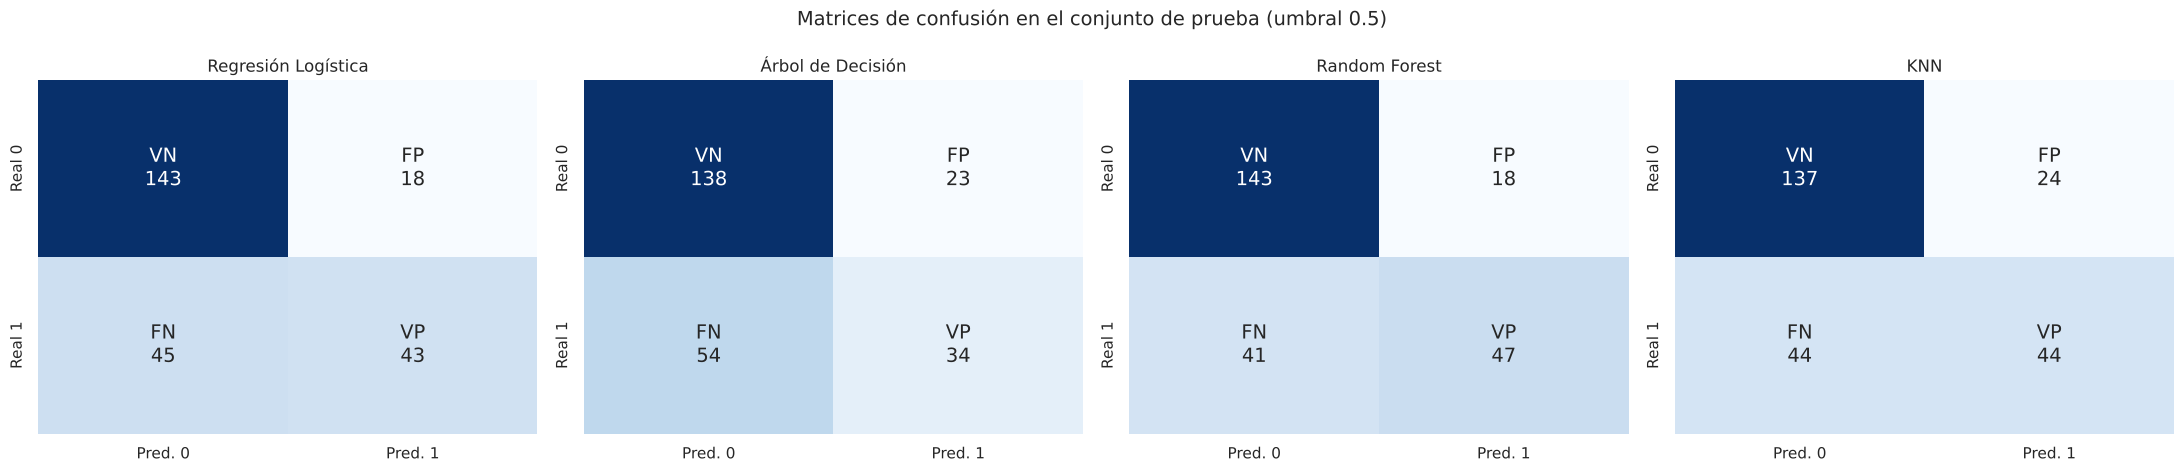

,VN,FP,FN,VP,Errores totales
Regresión Logística,143,18,45,43,63
Árbol de Decisión,138,23,54,34,77
Random Forest,143,18,41,47,59
KNN,137,24,44,44,68


In [26]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
nombres_celdas = np.array([['VN', 'FP'], ['FN', 'VP']])
for ax, (nombre, m) in zip(axes, MODELOS.items()):
    cm = confusion_matrix(y_test, m.predict(X_test))
    etiquetas = np.array([[f'{nombres_celdas[i, j]}\n{cm[i, j]}' for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=etiquetas, fmt='', cmap='Blues', cbar=False, ax=ax, annot_kws={'size': 14},
                xticklabels=['Pred. 0', 'Pred. 1'], yticklabels=['Real 0', 'Real 1'])
    ax.set_title(nombre)
plt.suptitle('Matrices de confusión en el conjunto de prueba (umbral 0.5)', fontsize=14)
plt.tight_layout(); plt.show()

celdas = {}
for nombre, m in MODELOS.items():
    vn, fp, fn, vp = confusion_matrix(y_test, m.predict(X_test)).ravel()
    celdas[nombre] = {'VN': vn, 'FP': fp, 'FN': fn, 'VP': vp, 'Errores totales': fp + fn}
pd.DataFrame(celdas).T

**Interpretación (umbral de 0.5, conjunto de prueba con 161 personas sin diabetes y 88 con diabetes):**
- **Random Forest** es el modelo con **menos errores totales (59)** y **menos falsos negativos (41)**: detecta a 47 de las 88 personas con diabetes (VP) e identifica correctamente a 143 de las 161 sanas (VN). Sus 18 falsos positivos empatan con los de la Regresión Logística, que tiene el mismo número de VN, pero deja pasar a 45 diabéticos.
- El **Árbol de Decisión** es el que más falla: 54 falsos negativos.
- **En todos los modelos hay más falsos negativos que falsos positivos** (por ejemplo, 41 contra 18 en Random Forest). Es la situación menos deseable en un problema de salud: el modelo se equivoca más dejando pasar enfermos que dando falsas alarmas. Con el umbral de 0.5, casi la mitad de las personas con diabetes se irían a casa sin diagnóstico. Esto se corrige en la sección 11.1 ajustando el umbral.

## 11. Métricas de evaluación de los algoritmos
A partir de la matriz de confusión se calculan las métricas de evaluación en el conjunto de prueba:

| Métrica | Fórmula | Qué responde en este caso |
|---|---|---|
| **Accuracy (exactitud)** | (VP + VN) / Total | ¿Qué porcentaje de todas las personas clasificó bien? |
| **Precision (precisión)** | VP / (VP + FP) | De las personas que el modelo marcó con diabetes, ¿cuántas sí la tienen? |
| **Recall (sensibilidad)** | VP / (VP + FN) | De las personas que sí tienen diabetes, ¿cuántas detectó? **Es la métrica más importante aquí** |
| **Especificidad** | VN / (VN + FP) | De las personas sanas, ¿cuántas identificó como sanas? |
| **F1-Score** | 2 · Precision · Recall / (Precision + Recall) | Equilibrio entre precision y recall |
| **AUC-ROC** | Área bajo la curva ROC | Capacidad de separar las dos clases en todos los umbrales (0.5 = azar, 1 = perfecto) |

La accuracy sola no basta: con 65% de personas sin diabetes, un modelo que dijera siempre "no tiene" tendría 65% de accuracy y **0% de recall**.

In [27]:
evaluacion = pd.DataFrame({n: metricas(m, X_test, y_test) for n, m in MODELOS.items()}).T
display(evaluacion.style.format('{:.3f}').highlight_max(axis=0, color='#F3E3A3'))
print(f'Reporte de clasificación del modelo con mayor AUC en validación cruzada ({GANADOR}):\n')
print(classification_report(y_test, MODELOS[GANADOR].predict(X_test),
                            target_names=['Sin diabetes (0)', 'Con diabetes (1)'], digits=3))

,Accuracy,Precision,Recall,Especificidad,F1,AUC
Regresión Logística,0.747,0.705,0.489,0.888,0.577,0.800
Árbol de Decisión,0.691,0.596,0.386,0.857,0.469,0.730
Random Forest,0.763,0.723,0.534,0.888,0.614,0.800
KNN,0.727,0.647,0.500,0.851,0.564,0.748


Reporte de clasificación del modelo con mayor AUC en validación cruzada (Random Forest):

                  precision    recall  f1-score   support

Sin diabetes (0)      0.777     0.888     0.829       161
Con diabetes (1)      0.723     0.534     0.614        88

        accuracy                          0.763       249
       macro avg      0.750     0.711     0.722       249
    weighted avg      0.758     0.763     0.753       249



**Curva ROC.** La curva ROC muestra, para todos los umbrales posibles, la tasa de verdaderos positivos (recall) contra la tasa de falsos positivos (1 − especificidad). Mientras más se acerque la curva a la esquina superior izquierda, mejor separa el modelo; la diagonal punteada representa un modelo que clasifica al azar (AUC = 0.5).

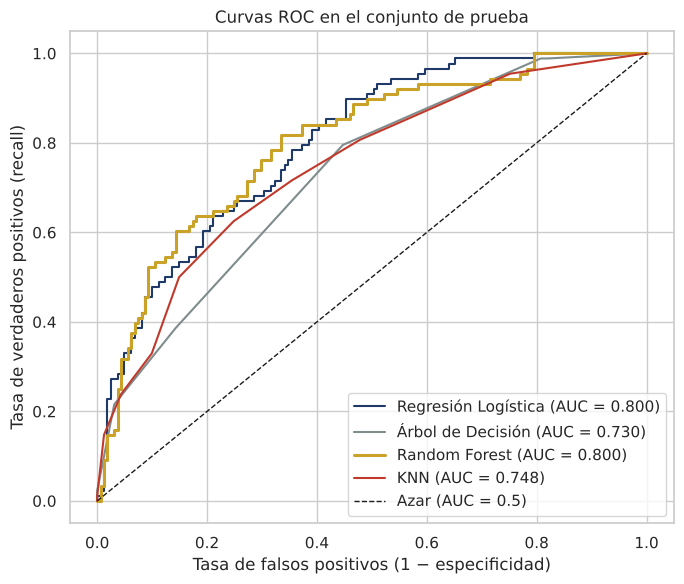

In [28]:
plt.figure(figsize=(7, 6))
for (nombre, m), col in zip(MODELOS.items(), [AZUL, '#7F8C8D', DORADO, '#C0392B']):
    prob = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, color=col, lw=2.2 if nombre == GANADOR else 1.5,
             label=f'{nombre} (AUC = {roc_auc_score(y_test, prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Azar (AUC = 0.5)')
plt.xlabel('Tasa de falsos positivos (1 − especificidad)'); plt.ylabel('Tasa de verdaderos positivos (recall)')
plt.title('Curvas ROC en el conjunto de prueba'); plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

**Interpretación:**
- **Random Forest** tiene la mejor **accuracy (0.763)**, **precision (0.723)**, **recall (0.534)** y **F1 (0.614)**, y empata en especificidad (0.888) y en AUC (0.800) con la Regresión Logística.
- La **Regresión Logística** es la segunda mejor (accuracy 0.747, recall 0.489, AUC 0.800). En la curva ROC, las curvas de ambos modelos están prácticamente encimadas.
- **KNN** (AUC 0.748) y el **Árbol de Decisión** (AUC 0.730) quedan por debajo; el árbol tiene el recall más bajo (0.386).
- Todos los modelos están claramente por encima de la diagonal del azar, es decir, **sí aprendieron a separar las clases**.
- **Precision de 0.723 con recall de 0.534** significa que cuando Random Forest dice "tiene diabetes" acierta 72% de las veces, pero solo encuentra a 53% de los diabéticos. Para un problema de salud ese recall es insuficiente.

### 11.1 Ajuste del umbral para reducir los falsos negativos
Por defecto un modelo clasifica como "con diabetes" cuando la probabilidad es ≥ 0.5. Como el **falso negativo es el error más grave**, conviene **bajar el umbral**: así el modelo marca como posible caso a más personas, detecta más diabéticos (sube el recall) a cambio de algunos falsos positivos más.

Para no hacer trampa con el conjunto de prueba, el umbral se elige con las **probabilidades de validación cruzada sobre el entrenamiento**: se toma el umbral más alto que logra un **recall de al menos 80%**. Después se aplica, sin cambios, al conjunto de prueba.

Umbral elegido (recall ≥ 80% en validación cruzada del entrenamiento): 0.35


,Recall,Precision,Especificidad,FN,FP
Umbral,,,,,
0.200,0.931,0.491,0.476,14,197
0.250,0.912,0.541,0.580,18,158
0.300,0.863,0.581,0.662,28,127
0.350,0.804,0.614,0.726,40,103
0.400,0.755,0.661,0.790,50,79
0.450,0.652,0.679,0.832,71,63
0.500,0.559,0.717,0.880,90,45


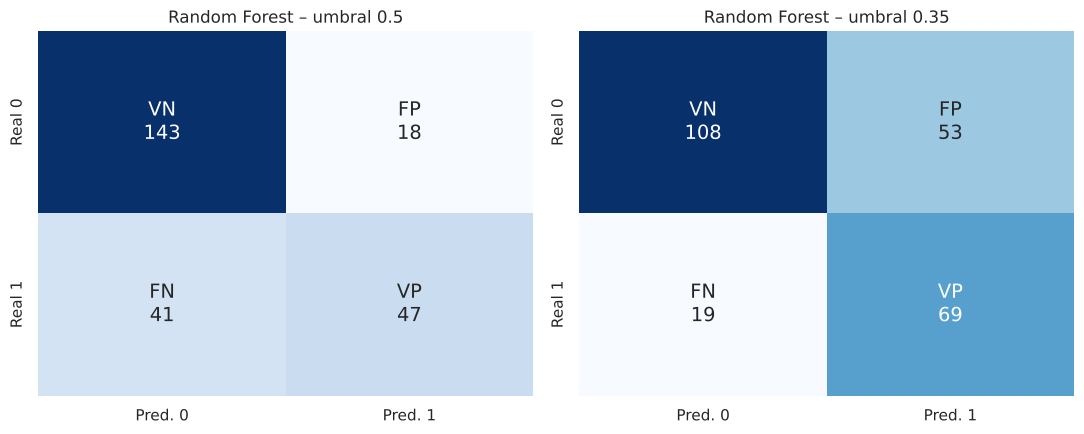

,Accuracy,Precision,Recall,Especificidad,F1,AUC
Umbral 0.5,0.763,0.723,0.534,0.888,0.614,0.800
Umbral 0.35,0.711,0.566,0.784,0.671,0.657,0.800


In [29]:
modelo_final = MODELOS[GANADOR]
prob_cv = cross_val_predict(clone(modelo_final), X_train, y_train, cv=CV5, method='predict_proba')[:, 1]

umbrales = []
for u in np.arange(0.20, 0.51, 0.05):
    pred = (prob_cv >= u).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_train, pred).ravel()
    umbrales.append({'Umbral': round(u, 2), 'Recall': vp / (vp + fn), 'Precision': vp / (vp + fp),
                     'Especificidad': vn / (vn + fp), 'FN': fn, 'FP': fp})
umbrales = pd.DataFrame(umbrales)
UMBRAL = umbrales.loc[umbrales['Recall'] >= 0.80, 'Umbral'].max()
print(f'Umbral elegido (recall ≥ 80% en validación cruzada del entrenamiento): {UMBRAL}')
display(umbrales.set_index('Umbral'))

# Aplicación al conjunto de prueba
comparar_umbral = pd.DataFrame({'Umbral 0.5': metricas(modelo_final, X_test, y_test, 0.5),
                                f'Umbral {UMBRAL}': metricas(modelo_final, X_test, y_test, UMBRAL)}).T
prob_test = modelo_final.predict_proba(X_test)[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, u in zip(axes, [0.5, UMBRAL]):
    cm = confusion_matrix(y_test, (prob_test >= u).astype(int))
    etiquetas = np.array([[f'{nombres_celdas[i, j]}\n{cm[i, j]}' for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=etiquetas, fmt='', cmap='Blues', cbar=False, ax=ax, annot_kws={'size': 14},
                xticklabels=['Pred. 0', 'Pred. 1'], yticklabels=['Real 0', 'Real 1'])
    ax.set_title(f'{GANADOR} – umbral {u}')
plt.tight_layout(); plt.show()
comparar_umbral

**Interpretación:**
- En la validación cruzada del entrenamiento, el umbral más alto que logra un recall de al menos 80% es **0.35** (recall 0.804, precision 0.614).
- Aplicado al **conjunto de prueba**, el cambio de umbral de 0.5 a 0.35:
  - sube el **recall de 0.534 a 0.784**: ahora se detecta a 69 de las 88 personas con diabetes, antes eran 47;
  - reduce los **falsos negativos de 41 a 19**: **22 personas con diabetes más son detectadas**;
  - aumenta los **falsos positivos de 18 a 53**: 35 falsas alarmas más;
  - baja la accuracy de 0.763 a 0.711 y la precision de 0.723 a 0.566, pero **sube el F1 de 0.614 a 0.657**. El AUC no cambia (0.800), porque mide la separación en todos los umbrales.
- Para el negocio este intercambio conviene: un falso positivo cuesta un estudio de confirmación, mientras que un falso negativo es una persona con diabetes sin tratamiento. **El modelo final recomendado es Random Forest con umbral de 0.35.**

## 12. Variables independientes que más inciden en tener diabetes
Se identifican las variables más influyentes con cuatro métricas complementarias, una por cada forma de medir la incidencia:
1. **Importancia en Random Forest**: qué porcentaje de la capacidad de decisión del bosque aporta cada variable (suman 100%).
2. **Importancia por permutación (en prueba)**: cuánto **cae el AUC** del modelo si se revuelven al azar los valores de esa variable. Si al revolverla el modelo empeora mucho, la variable es importante.
3. **Coeficiente de la regresión logística y razón de momios (odds ratio)**: con las variables estandarizadas, el coeficiente indica la **dirección** (positivo = aumenta el riesgo) y la **fuerza** del efecto. La razón de momios indica por cuánto se multiplica la probabilidad relativa (momios) de tener diabetes cuando la variable aumenta una desviación estándar.
4. **Valor p** (significancia estadística, con `statsmodels`): si es menor a 0.05, el efecto de la variable es **estadísticamente significativo** (es muy poco probable que se deba al azar).

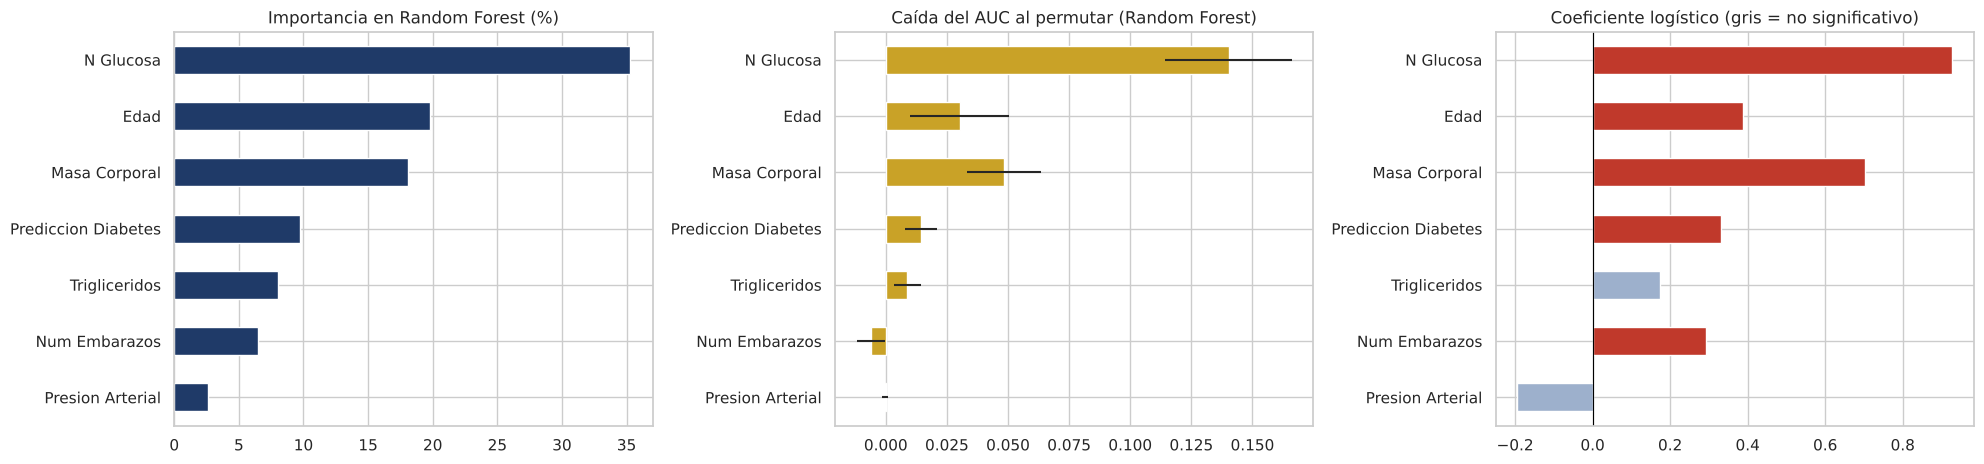

,Importancia RF (%),Caída del AUC al permutar,Coeficiente (estandarizado),Odds ratio por 1 desv. est.,Valor p,Significativa (p < 0.05)
N Glucosa,35.256,0.140,0.928,2.529,0.000,Sí
Edad,19.792,0.030,0.388,1.474,0.002,Sí
Masa Corporal,18.104,0.048,0.703,2.019,0.000,Sí
Prediccion Diabetes,9.720,0.014,0.331,1.392,0.003,Sí
Trigliceridos,8.064,0.009,0.173,1.189,0.118,No
Num Embarazos,6.442,-0.006,0.294,1.341,0.016,Sí
Presion Arterial,2.622,-0.000,-0.194,0.824,0.096,No


In [30]:
# 1) Importancia en Random Forest
rf = MODELOS['Random Forest'].named_steps['modelo']
imp_rf = pd.Series(rf.feature_importances_, index=VARIABLES) * 100

# 2) Importancia por permutación en el conjunto de prueba (caída del AUC), modelo final
perm = permutation_importance(modelo_final, X_test, y_test, scoring='roc_auc', n_repeats=30, random_state=SEMILLA)
imp_perm = pd.Series(perm.importances_mean, index=VARIABLES)

# 3) y 4) Regresión logística con statsmodels (variables imputadas y estandarizadas con el entrenamiento)
prep_lr = Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())]).fit(X_train)
Xs = pd.DataFrame(prep_lr.transform(X_train), columns=VARIABLES, index=X_train.index)
logit = sm.Logit(y_train, sm.add_constant(Xs)).fit(disp=0)

incidencia = pd.DataFrame({
    'Importancia RF (%)': imp_rf,
    'Caída del AUC al permutar': imp_perm,
    'Coeficiente (estandarizado)': logit.params[VARIABLES],
    'Odds ratio por 1 desv. est.': np.exp(logit.params[VARIABLES]),
    'Valor p': logit.pvalues[VARIABLES],
}).sort_values('Importancia RF (%)', ascending=False)
incidencia['Significativa (p < 0.05)'] = np.where(incidencia['Valor p'] < 0.05, 'Sí', 'No')

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
incidencia['Importancia RF (%)'][::-1].plot.barh(ax=axes[0], color=AZUL)
axes[0].set_title('Importancia en Random Forest (%)')
incidencia['Caída del AUC al permutar'][::-1].plot.barh(ax=axes[1], color=DORADO, xerr=pd.Series(perm.importances_std, index=VARIABLES)[incidencia.index[::-1]])
axes[1].set_title(f'Caída del AUC al permutar ({GANADOR})')
coef = incidencia['Coeficiente (estandarizado)'][::-1]
coef.plot.barh(ax=axes[2], color=[('#C0392B' if c > 0 else '#4F6D9A') if p < 0.05 else GRIS
                                   for c, p in zip(coef, incidencia['Valor p'][::-1])])
axes[2].axvline(0, color='black', lw=0.8); axes[2].set_title('Coeficiente logístico (gris = no significativo)')
plt.tight_layout(); plt.show()
incidencia

**Interpretación: métricas de cada variable significativa**

| Variable | Importancia RF | Caída del AUC al permutar | Odds ratio (por 1 desv. est.) | Valor p | Lectura |
|---|---|---|---|---|---|
| **N Glucosa** | **35.3%** | **0.140** | **2.53** | < 0.001 | La más influyente en las cuatro métricas. Cada aumento de una desviación estándar (≈ 31 unidades) multiplica por 2.5 los momios de tener diabetes |
| **Masa Corporal** | 18.1% | 0.048 | 2.02 | < 0.001 | Segunda en efecto: +1 desv. est. (≈ 7 puntos de IMC) duplica los momios |
| **Edad** | 19.8% | 0.030 | 1.47 | 0.002 | A mayor edad, mayor riesgo (+1 desv. est. ≈ 12 años aumenta los momios 47%) |
| **Prediccion Diabetes** | 9.7% | 0.014 | 1.39 | 0.003 | Los antecedentes familiares aumentan el riesgo de forma significativa |
| **Num Embarazos** | 6.4% | −0.006 | 1.34 | 0.016 | Significativa en la regresión logística. En Random Forest aporta poco porque su información se traslapa con la edad (r = 0.51) |
| Trigliceridos | 8.1% | 0.009 | 1.19 | 0.118 | **No significativa**: su efecto se explica en buena parte por las demás variables |
| Presion Arterial | 2.6% | ≈ 0 | 0.82 | 0.096 | **No significativa** y prácticamente sin aporte |

**Conclusión:** las variables que más inciden en tener diabetes son, en orden, **N Glucosa, Masa Corporal, Edad y Prediccion Diabetes**; Num Embarazos también es significativa. Todas las variables significativas tienen efecto **positivo**: valores más altos, mayor riesgo. Las cuatro métricas coinciden en que la glucosa es la principal, por mucho.

### 12.1 ¿Hay una variable dominante? Experimento sin la glucosa
Una regla vista en clase es que si una sola variable domina la decisión (por ejemplo, si la glucosa por sí sola definiera el 90% del diagnóstico), conviene **quitarla y analizar el modelo sin ella**, para ver el impacto y si las demás variables pueden aprender por sí mismas. La glucosa es la variable más importante, así que se reentrenan los modelos **sin N Glucosa** (con las mismas perillas) y se comparan los resultados.

In [31]:
SIN_GLUCOSA = [v for v in VARIABLES if v != 'N Glucosa']
filas = []
for nombre, m in MODELOS.items():
    m_sin = clone(m).fit(X_train[SIN_GLUCOSA], y_train)
    con, sin = metricas(m, X_test, y_test), metricas(m_sin, X_test[SIN_GLUCOSA], y_test)
    cv_con = cross_val_score(clone(m), X, y, cv=CV5, scoring='roc_auc').mean()
    cv_sin = cross_val_score(clone(m), X[SIN_GLUCOSA], y, cv=CV5, scoring='roc_auc').mean()
    filas.append({'Modelo': nombre, 'AUC CV con glucosa': cv_con, 'AUC CV sin glucosa': cv_sin,
                  'Recall con glucosa': con['Recall'], 'Recall sin glucosa': sin['Recall']})
sin_glucosa = pd.DataFrame(filas).set_index('Modelo')
sin_glucosa['Caída AUC'] = sin_glucosa['AUC CV con glucosa'] - sin_glucosa['AUC CV sin glucosa']

rf_sin = clone(MODELOS['Random Forest']).fit(X_train[SIN_GLUCOSA], y_train)
print('Importancia en Random Forest sin la glucosa (%):')
print((pd.Series(rf_sin.named_steps['modelo'].feature_importances_, index=SIN_GLUCOSA) * 100)
      .sort_values(ascending=False).round(1).to_string())
sin_glucosa

Importancia en Random Forest sin la glucosa (%):
Edad                  29.200
Masa Corporal         27.800
Prediccion Diabetes   14.600
Trigliceridos         14.500
Num Embarazos          9.500
Presion Arterial       4.300


,AUC CV con glucosa,AUC CV sin glucosa,Recall con glucosa,Recall sin glucosa,Caída AUC
Modelo,,,,,
Regresión Logística,0.824,0.767,0.489,0.455,0.056
Árbol de Decisión,0.785,0.734,0.386,0.352,0.051
Random Forest,0.838,0.786,0.534,0.386,0.051
KNN,0.818,0.755,0.500,0.386,0.064


**Interpretación:**
- La glucosa **no es una variable dominante en el sentido de la regla de clase**: aporta 35% de la importancia en Random Forest, lejos del 90%.
- Al quitarla, el AUC de validación cruzada baja entre **0.05 y 0.06** en todos los modelos (Random Forest de 0.838 a 0.786; Regresión Logística de 0.824 a 0.767). El recall de Random Forest en prueba baja de 0.534 a 0.386.
- **Sin la glucosa, las demás variables siguen aprendiendo por sí mismas**: con AUC ≈ 0.79 el modelo todavía separa bastante mejor que el azar. Su importancia se redistribuye: Edad (29.2%) y Masa Corporal (27.8%) pasan a ser las principales, seguidas de Prediccion Diabetes (14.6%) y Triglicéridos (14.5%).
- **Decisión:** la glucosa **se conserva** en el modelo final. Es la variable más útil, pero no "contamina" el aprendizaje, porque las demás conservan su capacidad predictiva. Además, es una medición clínica legítima y barata. El experimento confirma que **edad y masa corporal son los factores de riesgo más fuertes después de la glucosa**, algo útil para detectar personas en riesgo antes de un estudio de laboratorio.

## 13. Métricas por variable significativa: rangos críticos (bins)
Para que el resultado sea útil para el negocio no basta con saber **qué** variable importa; hay que saber **a partir de qué valor** el riesgo aumenta. Para cada variable significativa se agrupan los valores en **rangos (bins)** y se calcula:
- **Personas** en el rango y cuántas tienen diabetes.
- **% con diabetes** (tasa de diabetes en el rango).
- **Riesgo relativo**: cuántas veces es mayor (o menor) la tasa del rango respecto de la tasa general (35.2%).

Los cortes se basan en rangos de referencia habituales (por ejemplo, las categorías de IMC de la OMS) y en los puntos de división que encontró el árbol de decisión (sección 8.3).

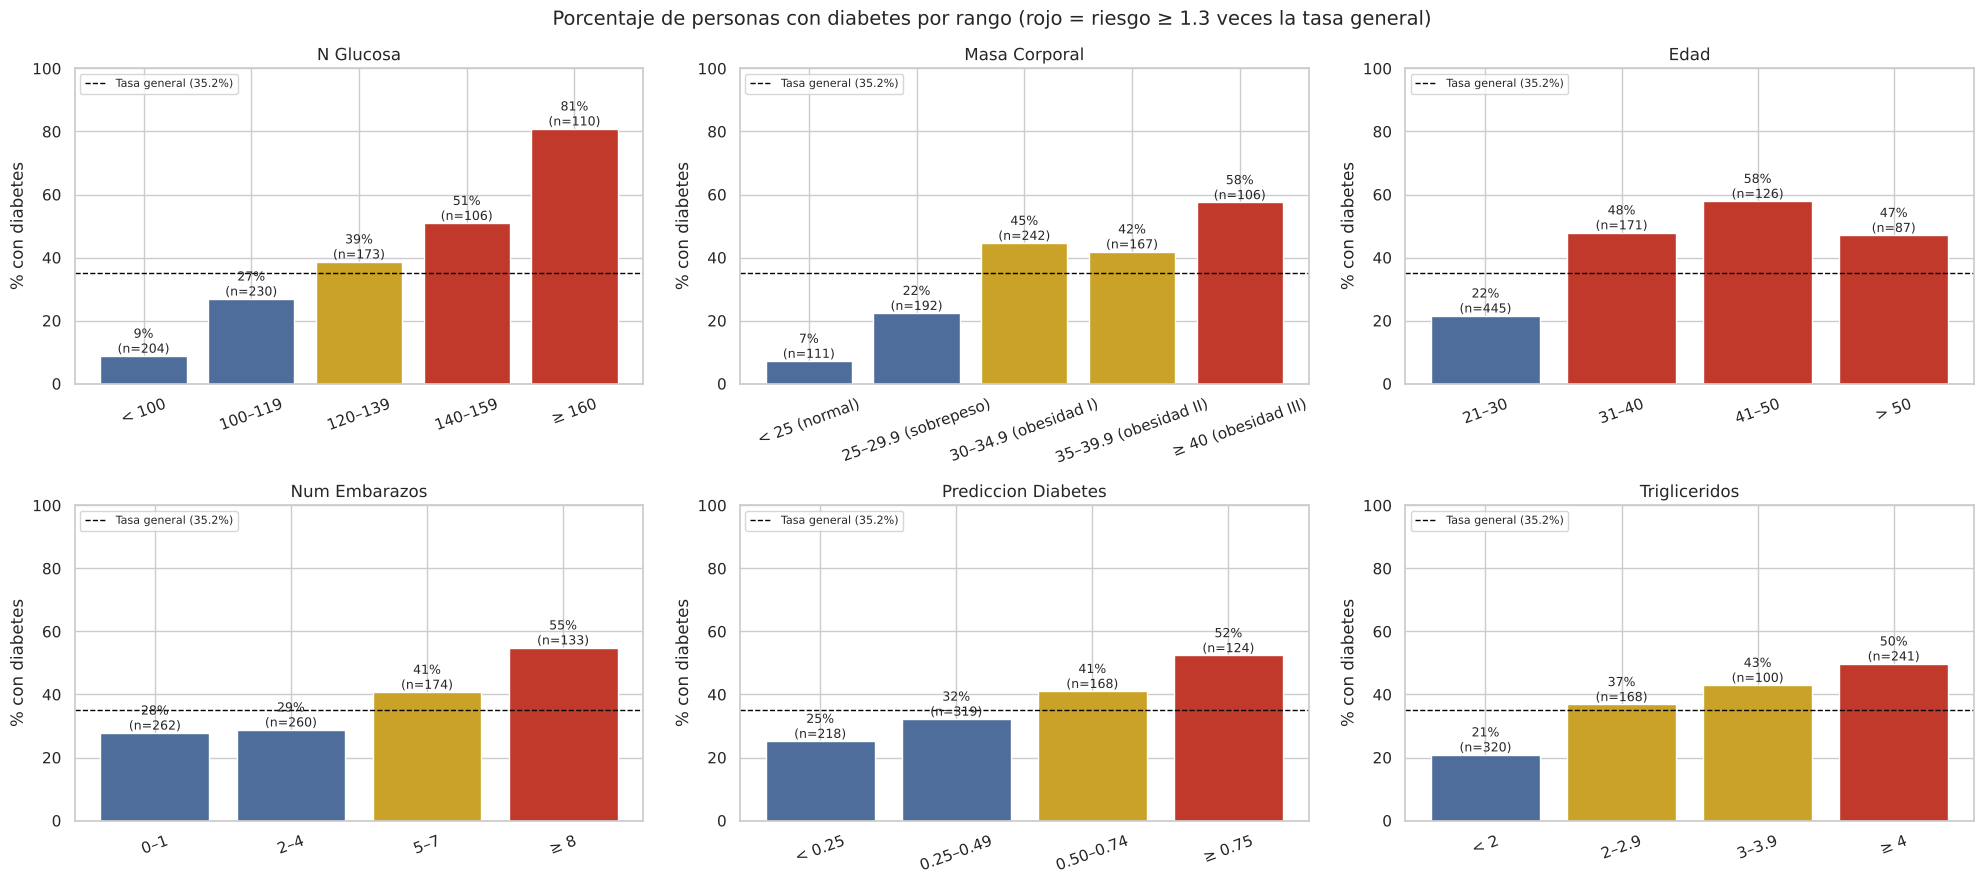


N Glucosa
           Personas  Con diabetes  % con diabetes  Riesgo relativo
N Glucosa                                                         
< 100           204            18           8.800            0.250
100–119         230            62          27.000            0.770
120–139         173            67          38.700            1.100
140–159         106            54          50.900            1.450
≥ 160           110            89          80.900            2.300

Masa Corporal
                       Personas  Con diabetes  % con diabetes  Riesgo relativo
Masa Corporal                                                                 
< 25 (normal)               111             8           7.200            0.200
25–29.9 (sobrepeso)         192            43          22.400            0.640
30–34.9 (obesidad I)        242           108          44.600            1.270
35–39.9 (obesidad II)       167            70          41.900            1.190
≥ 40 (obesidad III)         106

In [32]:
BINS = {
    'N Glucosa': ([0, 100, 120, 140, 160, 300], ['< 100', '100–119', '120–139', '140–159', '≥ 160']),
    'Masa Corporal': ([0, 25, 30, 35, 40, 100], ['< 25 (normal)', '25–29.9 (sobrepeso)', '30–34.9 (obesidad I)',
                                                '35–39.9 (obesidad II)', '≥ 40 (obesidad III)']),
    'Edad': ([21, 31, 41, 51, 100], ['21–30', '31–40', '41–50', '> 50']),
    'Num Embarazos': ([0, 2, 5, 8, 30], ['0–1', '2–4', '5–7', '≥ 8']),
    'Prediccion Diabetes': ([0, 0.25, 0.5, 0.75, 3], ['< 0.25', '0.25–0.49', '0.50–0.74', '≥ 0.75']),
    'Trigliceridos': ([0, 2, 3, 4, 10], ['< 2', '2–2.9', '3–3.9', '≥ 4']),
}
TASA_GENERAL = y.mean()
tablas_bins = {}
for v, (cortes, etiquetas) in BINS.items():
    rango = pd.cut(datos[v], bins=cortes, labels=etiquetas, right=False)
    t = datos.groupby(rango, observed=False)[OBJETIVO].agg(Personas='size', **{'Con diabetes': 'sum'})
    t['% con diabetes'] = t['Con diabetes'] / t['Personas'] * 100
    t['Riesgo relativo'] = t['% con diabetes'] / 100 / TASA_GENERAL
    tablas_bins[v] = t

fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for ax, (v, t) in zip(axes.ravel(), tablas_bins.items()):
    barras = ax.bar(t.index.astype(str), t['% con diabetes'],
                    color=[('#C0392B' if r >= 1.3 else DORADO if r >= 1 else '#4F6D9A') for r in t['Riesgo relativo']])
    ax.axhline(TASA_GENERAL * 100, color='black', ls='--', lw=1, label=f'Tasa general ({TASA_GENERAL*100:.1f}%)')
    for b, (p, n) in zip(barras, zip(t['% con diabetes'], t['Personas'])):
        ax.text(b.get_x() + b.get_width() / 2, p + 1, f'{p:.0f}%\n(n={n})', ha='center', fontsize=9)
    ax.set_title(v); ax.set_ylabel('% con diabetes'); ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=20); ax.legend(fontsize=8, loc='upper left')
plt.suptitle('Porcentaje de personas con diabetes por rango (rojo = riesgo ≥ 1.3 veces la tasa general)', fontsize=14)
plt.tight_layout(); plt.show()

for v, t in tablas_bins.items():
    print(f'\n{v}')
    print(t.round({'% con diabetes': 1, 'Riesgo relativo': 2}).to_string())

**Interpretación (rangos críticos):**
- **N Glucosa:** el riesgo crece de forma constante. Con glucosa menor a 100 solo 8.8% tiene diabetes (0.25 veces la tasa general); de 140 a 159 la proporción sube a **50.9% (1.45 veces)** y con **160 o más llega a 80.9% (2.3 veces)**. **Valor crítico: glucosa ≥ 140**, que coincide con el primer corte del árbol (142.5).
- **Masa Corporal:** con IMC normal (< 25) solo 7.2% tiene diabetes. En sobrepeso la proporción sube a 22.4% y **desde la obesidad (IMC ≥ 30) supera el 40%**, hasta llegar a **57.5% con IMC ≥ 40 (1.63 veces)**. **Valor crítico: IMC ≥ 30.**
- **Edad:** de 21 a 30 años 21.6% tiene diabetes; **de 31 a 40 la proporción se duplica (48.0%)** y llega a su máximo entre 41 y 50 años (**57.9%, 1.64 veces**). **Valor crítico: más de 30 años**, igual que el corte del árbol (28.5).
- **Num Embarazos:** con 0 a 4 embarazos ≈ 28% tiene diabetes; con **8 o más, 54.9% (1.56 veces)**.
- **Prediccion Diabetes:** el riesgo aumenta con el índice de antecedentes familiares, de 25.2% (< 0.25) a **52.4% con 0.75 o más (1.49 veces)**.
- **Trigliceridos:** de 20.9% (< 2) a 49.8% (≥ 4). La relación es visible, aunque en la regresión logística no resultó significativa porque se traslapa con las otras variables. Se incluye como complemento.

**Perfil de alto riesgo:** glucosa ≥ 140, IMC ≥ 30 y más de 30 años, sobre todo si hay antecedentes familiares altos o 8 embarazos o más.

## 14. Personas en los falsos positivos y falsos negativos
Siguiendo la indicación de no quedarse solo con el porcentaje de error, se identifica **por registro y número de persona** a cada caso que el modelo clasificó mal en el conjunto de prueba. Se usa el **modelo final recomendado**: el modelo ganador con el **umbral ajustado** de la sección 11.1.

Para cada persona se muestra la **probabilidad de diabetes** que le asignó el modelo y sus valores clínicos (los valores faltantes aparecen como NaN).

In [33]:
resultado = pd.concat([id_test, X_test, y_test.rename('Real')], axis=1)
resultado['Probabilidad'] = prob_test
resultado['Predicción'] = (prob_test >= UMBRAL).astype(int)
resultado['Tipo'] = np.select(
    [(resultado['Real'] == 1) & (resultado['Predicción'] == 1), (resultado['Real'] == 0) & (resultado['Predicción'] == 0),
     (resultado['Real'] == 0) & (resultado['Predicción'] == 1), (resultado['Real'] == 1) & (resultado['Predicción'] == 0)],
    ['VP', 'VN', 'FP', 'FN'], default='')
COLS = ['Registro', 'Persona', 'Probabilidad'] + VARIABLES

falsos_negativos = resultado[resultado['Tipo'] == 'FN'].sort_values('Probabilidad')[COLS].reset_index(drop=True)
falsos_negativos.index += 1
print(f'FALSOS NEGATIVOS: {len(falsos_negativos)} personas CON diabetes que el modelo clasificó como sanas '
      f'({GANADOR}, umbral {UMBRAL})')
falsos_negativos

FALSOS NEGATIVOS: 19 personas CON diabetes que el modelo clasificó como sanas (Random Forest, umbral 0.35)


,Registro,Persona,Probabilidad,N Glucosa,Masa Corporal,Edad,Num Embarazos,Trigliceridos,Prediccion Diabetes,Presion Arterial
1,789,160,0.097,78.000,31.000,26,3,4.000,0.248,50.000
2,220,2520,0.100,139.000,25.600,22,3,1.300,0.402,54.000
3,704,480,0.105,90.000,38.200,27,2,1.900,0.503,68.000
4,484,7360,0.113,111.000,28.400,22,3,4.000,0.259,62.000
5,565,4580,0.129,104.000,33.600,22,0,1.500,0.510,64.000
6,459,3310,0.141,112.000,31.600,25,3,2.800,0.197,74.000
7,374,6880,0.199,121.000,36.000,25,3,2.900,0.127,52.000
8,304,5510,0.214,128.000,32.400,27,3,2.000,0.549,72.000
9,302,3030,0.228,128.000,40.500,24,1,2.000,0.613,48.000
10,267,5450,0.241,132.000,32.900,23,4,2.000,0.302,NaN


In [34]:
falsos_positivos = resultado[resultado['Tipo'] == 'FP'].sort_values('Probabilidad', ascending=False)[COLS].reset_index(drop=True)
falsos_positivos.index += 1
print(f'FALSOS POSITIVOS: {len(falsos_positivos)} personas SIN diabetes que el modelo señaló con diabetes '
      f'({GANADOR}, umbral {UMBRAL})')
falsos_positivos

FALSOS POSITIVOS: 53 personas SIN diabetes que el modelo señaló con diabetes (Random Forest, umbral 0.35)


,Registro,Persona,Probabilidad,N Glucosa,Masa Corporal,Edad,Num Embarazos,Trigliceridos,Prediccion Diabetes,Presion Arterial
1,10,3700,0.849,196.000,46.300,32,8,5.000,1.096,76.000
2,70,4970,0.795,173.000,46.500,58,0,2.000,1.159,78.000
3,152,5910,0.736,151.000,32.000,39,12,5.500,0.391,70.000
4,136,5090,0.688,154.000,29.300,39,6,3.000,0.839,74.000
5,149,3050,0.685,151.000,35.500,28,6,5.400,0.692,62.000
6,172,680,0.677,146.000,40.500,44,0,1.500,1.781,82.000
7,138,6790,0.631,154.000,30.900,45,9,3.000,0.164,78.000
8,190,4800,0.605,144.000,41.300,28,1,3.800,0.607,82.000
9,175,2540,0.604,146.000,38.200,29,2,3.700,0.329,76.000
10,45,7640,0.592,181.000,32.400,22,8,5.500,0.433,68.000


**¿Por qué se equivocó el modelo?** Se compara el perfil promedio de cada grupo de la matriz de confusión. Si los falsos negativos se parecen más a los sanos que a los diabéticos detectados (y los falsos positivos se parecen más a los diabéticos), el error no es un defecto del algoritmo sino que **esas personas tienen valores clínicos atípicos para su diagnóstico**.

In [35]:
perfil = resultado.groupby('Tipo')[VARIABLES + ['Probabilidad']].median().loc[['VP', 'FN', 'FP', 'VN']]
perfil.insert(0, 'Personas', resultado['Tipo'].value_counts()[perfil.index])
perfil.index = ['VP (diabetes detectada)', 'FN (diabetes no detectada)', 'FP (falsa alarma)', 'VN (sano identificado)']
print('Mediana de cada variable por grupo (conjunto de prueba):')
display(perfil)

fn_, fp_ = resultado[resultado['Tipo'] == 'FN'], resultado[resultado['Tipo'] == 'FP']
print(f"Falsos negativos con glucosa < 120: {(fn_['N Glucosa'] < 120).sum()} de {len(fn_)}")
print(f"Falsos negativos con IMC < 30:      {(fn_['Masa Corporal'] < 30).sum()} de {len(fn_)}")
print(f"Falsos negativos con edad ≤ 30:     {(fn_['Edad'] <= 30).sum()} de {len(fn_)}")
print(f"Falsos positivos con glucosa ≥ 140: {(fp_['N Glucosa'] >= 140).sum()} de {len(fp_)}")
print(f"Falsos positivos con IMC ≥ 30:      {(fp_['Masa Corporal'] >= 30).sum()} de {len(fp_)}")

Mediana de cada variable por grupo (conjunto de prueba):


,Personas,N Glucosa,Masa Corporal,Edad,Num Embarazos,Trigliceridos,Prediccion Diabetes,Presion Arterial,Probabilidad
VP (diabetes detectada),69,142.000,35.250,37.000,5.000,3.000,0.402,78.000,0.562
FN (diabetes no detectada),19,111.000,32.400,27.000,3.000,2.900,0.503,69.000,0.241
FP (falsa alarma),53,128.000,33.950,39.000,5.000,2.900,0.380,75.000,0.465
VN (sano identificado),108,100.000,29.500,25.000,2.000,1.900,0.334,70.000,0.158


Falsos negativos con glucosa < 120: 12 de 19
Falsos negativos con IMC < 30:      5 de 19
Falsos negativos con edad ≤ 30:     15 de 19
Falsos positivos con glucosa ≥ 140: 21 de 53
Falsos positivos con IMC ≥ 30:      40 de 53


**Interpretación de los falsos negativos (19 personas: las más importantes de atender):**
- Son personas **con diabetes que tienen valores clínicos de persona sana**. Su glucosa mediana es **111**, muy por debajo de la de los diabéticos detectados (142) y cercana a la de los sanos (100). **12 de los 19 tienen glucosa menor a 120.**
- Además son **jóvenes**: mediana de 27 años y **15 de 19 tienen 30 años o menos**, el grupo de menor riesgo según la sección 13. El modelo les asignó probabilidades bajas (de 0.10 a 0.34).
- Un dato importante: su índice de **Predicción Diabetes** (mediana 0.503) es **más alto** que el de los diabéticos detectados (0.402). Son personas jóvenes, con glucosa todavía normal en la medición, pero con **antecedentes familiares fuertes**.
- **Ejemplos:** el registro 789 (Persona 160), con glucosa de 78, y el registro 704 (Persona 480), con glucosa de 90, tienen diabetes, pero nada en sus valores lo indica. Con los datos disponibles ningún modelo podría detectarlos. Haría falta otra prueba, como la hemoglobina glucosilada, que refleja el promedio de glucosa de los últimos meses.

**Interpretación de los falsos positivos (53 personas):**
- Son personas **sin diabetes con perfil de alto riesgo**: glucosa mediana de **128**, IMC mediano de **33.95** (obesidad) y **39 años**, valores parecidos a los de los diabéticos detectados. **40 de las 53 tienen IMC ≥ 30 y 21 tienen glucosa ≥ 140.**
- Por eso estas "falsas alarmas" **no son un gasto inútil**: muchas pueden estar en una etapa previa a la diabetes (prediabetes) y son justo la población que conviene incluir en programas de prevención.
- **El primer falso positivo es el registro 10 (Persona 3700)**, con la probabilidad más alta (0.849), glucosa de 196 e IMC de 46.3. Con esos valores es muy probable que tenga diabetes no diagnosticada o un error de captura en su diagnóstico; conviene revisar su expediente. Además, el número 3700 también aparece en el registro 22, de otra persona con diabetes: por eso **se identifica a cada persona con Registro y Persona juntos**.

**Acción propuesta:**
- **Falsos negativos:** citar a las 19 personas a una prueba confirmatoria (hemoglobina glucosilada o curva de tolerancia a la glucosa). Como regla de negocio, **no descartar diabetes en personas jóvenes con Predicción Diabetes alta** aunque el modelo indique bajo riesgo.
- **Falsos positivos:** confirmar con una prueba de laboratorio y, si no tienen diabetes, incluirlas en un **programa preventivo** (control de peso y seguimiento anual de glucosa).

## 15. Conclusiones desde el punto de vista de negocio

1. **Variables que más inciden en tener diabetes.** En orden: **N Glucosa** (35% de la importancia en Random Forest; cada desviación estándar adicional multiplica por 2.5 los momios de tener diabetes), **Masa Corporal** (momios × 2.0), **Edad** (× 1.5) y **Prediccion Diabetes** (× 1.4, antecedentes familiares). **Num Embarazos** también es significativa. Triglicéridos y presión arterial no resultaron significativas al considerar las demás variables. Insulina, grosor de la piel, urea y lipoproteína BD se descartaron en el EDA por tener demasiados faltantes, ser redundantes o no separar las clases.

2. **Rangos críticos.** El riesgo de diabetes se dispara con **glucosa ≥ 140** (51% con diabetes; 81% con glucosa ≥ 160), **IMC ≥ 30** (más de 40%; 58% con IMC ≥ 40) y **edad mayor a 30 años** (el porcentaje se duplica, de 22% a 48%). También aumenta con 8 o más embarazos (55%) y con antecedentes familiares altos (52%). El árbol de decisión encontró una regla muy clara: con **glucosa > 142.5 y triglicéridos > 5.7, el 100%** de las personas (21 de 21) tiene diabetes.

3. **Mejor modelo: Random Forest.** Obtuvo el mayor AUC en validación cruzada (**0.838 ± 0.020 con K = 5 y 0.840 ± 0.024 con K = 8**) y en el conjunto de prueba (**AUC = 0.800**, accuracy = 0.763), con resultados estables ante cambios de semilla. La **Regresión Logística** quedó muy cerca (AUC 0.824) y es la mejor opción para **explicar** el efecto de cada variable. El **árbol sin límite** mostró el sobreajuste visto en clase (1.000 en entrenamiento contra 0.677 en prueba) y se descartó.

4. **Ajuste al costo del error.** En salud, el falso negativo es el error más grave. Con el umbral estándar de 0.5 el modelo solo detectaba a 53% de los diabéticos. **Con el umbral de 0.35, el recall sube a 78%**: los falsos negativos bajan de 41 a 19 a cambio de 35 falsas alarmas más. Para la institución es preferible pagar un estudio de confirmación que dejar a una persona con diabetes sin tratamiento.

5. **Quiénes son los errores.** Los **falsos negativos** son, sobre todo, **personas jóvenes con glucosa normal pero antecedentes familiares altos**: un perfil que los datos actuales no permiten detectar. Los **falsos positivos** son **personas con obesidad, glucosa elevada y mayor edad**, un grupo de alto riesgo aunque hoy no tenga diabetes.

6. **Recomendaciones para la institución:**
   - Usar el modelo como **herramienta de detección temprana (tamizaje)**, no como diagnóstico. A toda persona con probabilidad ≥ 0.35 se le hace una prueba confirmatoria.
   - Priorizar campañas de prevención en personas con **IMC ≥ 30, glucosa ≥ 140 y más de 30 años**.
   - Para personas jóvenes con antecedentes familiares altos, aplicar la prueba de hemoglobina glucosilada aunque el modelo indique bajo riesgo.
   - Corregir la captura de datos: medir siempre insulina y grosor de piel (hoy faltan en 49% y 30% de los registros), revisar los valores imposibles de lipoproteína BD y asignar un **identificador único** a cada persona, porque el número de `Persona` se repite.

7. **Limitaciones.** El modelo se entrenó con 829 registros. Se asumió que todas las personas son mujeres, porque el archivo no incluye el sexo. No se sabe si la glucosa se midió en ayuno. Su capacidad de separación es buena (AUC entre 0.80 y 0.84), pero no perfecta, por lo que siempre debe acompañarse del criterio médico.